<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/VQC_QuantumAdversarialLearning_Lu2020.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum adversarial machine learning: attacking and defending a quantum classifier (Lu, Duan and Deng, 2020) step by step

This notebook re-implements, runs and checks the numerical experiments of

> Sirui Lu, Lu-Ming Duan and Dong-Ling Deng,
> "Quantum adversarial machine learning",
> Physical Review Research 2, 033212 (2020). https://doi.org/10.1103/PhysRevResearch.2.033212 (arXiv:2001.00030)

**What the notebook does.** An *adversarial example* is an input that has been changed by an amount a human would not notice (or, for a quantum state, by an amount that leaves its
fidelity with the original close to 1) but that makes a classifier give the wrong answer. The paper shows that a **quantum classifier** (a parametrised circuit with 9-10 qubits) is as
vulnerable as a neural network, for three kinds of data, and that the damage can be repaired by adversarial training:

1. **images**: MNIST digits (1 versus 9, and the four digits 1, 3, 7, 9) reduced to 16 x 16 pixels and *amplitude-encoded* in 8 qubits;
2. **phases of matter**: spin-resolved time-of-flight images of a topological (quantum anomalous Hall) model, again amplitude-encoded;
3. **quantum data**: the ground states of the 1-D transverse-field Ising model (ferromagnet versus paramagnet), used directly as input states.

Every experiment of the paper is rerun on a CPU: white-box attacks (FGSM, BIM, MIM, PGD; additive and "functional"; untargeted and targeted), black-box transfer attacks from classical networks,
the effect of random depolarising noise, and adversarial training. The notebook adds what the paper does not have: an **exact simulator that is asserted equal to the real Qiskit circuits**,
**classical baselines on exactly the same inputs**, **adaptive attacks that test whether the defence only masks gradients**, and an explicit verdict for every claim.

**How to run.** Open in Google Colab (button above), choose a CPU runtime and *Run all*. `FAST_MODE = True` (about 9 minutes on one CPU thread) uses small data sets and short training; `FAST_MODE = False` uses
the larger budgets that are documented in the configuration cell (about 45-90 minutes on one CPU thread). The committed copy of this notebook was executed with `FAST_MODE = False`. MNIST is read from a public Hugging Face mirror
(no token needed); the other two data sets are generated here from their Hamiltonians. If a gated data set were ever needed, the token is read only from the environment variable `HF_TOKEN` or from
Colab *Secrets* (never typed into the notebook).

**What you get at the end.** Re-drawn Fig. 4-16 and Tables I-IV of the paper next to the paper's numbers, drawings of every executed circuit, a table of about 40 claims with verdicts
("reproduced" / "not reached here" / "exceeded here" / "cannot be checked"), and a critical reading of what the numbers do and do not show.

## The paper in one page

**Problem.** Classical neural networks can be fooled by tiny, carefully computed input changes (Szegedy's panda that becomes a gibbon). Do quantum classifiers have the same weakness, for classical
data that is encoded into a quantum state, *and* for genuinely quantum data? And can the weakness be reduced?

**The classifier (Fig. 2).** An n-qubit input state |psi> (the data) is tensored with m output qubits in |1>^m. Then p layers act; layer i is a *rotation unit* (an arbitrary single-qubit Euler
rotation Z(c) X(b) Z(a) on every qubit) followed by an *entangler* made of CNOT gates. The probability of every bit string on the m output qubits (the diagonal g of the reduced density matrix)
is the probability of the corresponding class; the label is the largest one. Loss: cross-entropy of Eq. (2). Training: Adam, exact gradients (the parameter-shift rule of Eq. (3), here equal to automatic differentiation).

**Classical data -> quantum state: amplitude encoding.** The 256 pixel values (16 x 16 image) are normalised and used as the 2^8 amplitudes of |psi> (8 qubits). One output qubit for two classes,
two for four classes.

**Attacks (Appendix A).** The attacker adds a perturbation to the input state to *maximise* the loss of the true label (untargeted, Eq. 4) or *minimise* the loss of a chosen wrong label (targeted, Eq. 5).
*Additive* attacks change every amplitude independently; *functional* attacks only apply a layer of local unitaries (much cheaper to realise on hardware, a smaller search space).
Methods: **FGSM** (one step eps*sign(gradient)), **BIM** (T steps of size eps/T, re-normalising the state after each step), MIM and PGD; white-box (the attacker knows the circuit) or black-box
(adversarial examples crafted for a classical CNN / feed-forward net are fed to the quantum classifier). Size of a perturbation: the **fidelity** F = |<psi_adv|psi>|^2 (1 = identical).

**Data and numbers the paper reports** (every one of them is checked below):
MNIST 1 vs 9 (11633 train / 1058 validation / 2144 test): accuracy about 98 %; four digits 1,3,7,9 (20000 / 2000 / test set): 91.6 %; Table I (untargeted BIM/FGSM: fidelity and remaining accuracy), Table II (targeted),
Table III (black-box transfer from a CNN and an FNN), Table IV (topological phases), Fig. 7 (accuracy reaches 0 after about five BIM iterations while the average fidelity stays > 0.73), Fig. 8 (functional attacks are weaker),
Fig. 11 (random depolarising noise lowers the accuracy only roughly linearly - adversarial perturbations are *not* random noise), Fig. 12-13 (topological phases), Fig. 14-15 (Ising ground states, L = 8), Fig. 16 (adversarial training
restores more than 98 % accuracy against the attack it was trained on).

**Note on the data the paper uses.** The two physics data sets are simulated by the authors; the paper gives their Hamiltonians (Eq. 7 and Eq. 9) but not the sampling details. They are generated here by exact
diagonalisation, and every label is the physical phase (Chern number, or the side of the critical field J_x = 1) of the Hamiltonian that produced the state.

### What follows the paper and what had to be chosen

The paper gives the circuit family, the data sets, the optimiser and the attack names and budgets, but not the entangler layout, the initialisation, the units of the attack step sizes, the sampling of the physics data sets, or the
number of runs. Everything unspecified is marked `# CHOICE:` in the code. The most important choice concerns the **units of the attack budgets** (see the row "attack budgets").

| Item | Paper | This notebook |
|---|---|---|
| Circuit | p layers of Z(c)X(b)Z(a) on every qubit + "a series of CNOT gates"; input |psi>|1>^m | same rotations; CNOT **ring** CNOT(i, i+1 mod N); written in Qiskit (drawn and verified) and as an exact batched PyTorch simulator, **asserted equal** to the Qiskit circuits |
| Depth | 10 (2 classes, Ising, topological, Table I/IV), 20 (Fig. 7, 8, 11), 40 (4 classes, Fig. 5, Table I), 10 (Table II) | 10 everywhere (a depth-40 circuit on 10 qubits costs 4x more); `P_DEPTH_4C = 40` follows Fig. 5 if you have hours |
| Optimiser | Adam, lr 0.005, batch 256 / 512, 200 epochs | Adam, lr 0.05 (FAST) / 0.02 (full), batch 128 (FAST) / 256, 6-100 epochs (the full budget has 7-15x fewer optimiser steps than the paper, FAST about 100x fewer), angles initialised N(0, 0.5^2) |
| Data sizes | MNIST 1/9: 11633 / 1058 / 2144; 4 digits: 20000 / 2000 / test; topological: 19956 / 6652 / 2000; Ising: 1182 / 395 / 395 | same sources and splits (train and validation disjoint, from the official training split; test from the official test split) but fewer images in FAST mode and for the 4-digit train set in the full run (12000 instead of 20000) and the topological set (6000 instead of 19956) - see the configuration cell; the Ising set has the paper's size |
| MNIST 28 -> 16 pixels | "reduced to 16 x 16" | bilinear resize with anti-aliasing (PIL) |
| Topological data | lower band of the QAH model, 10 x 10 lattice, "spin-resolved time-of-flight images", lambda_SO and t varied | momentum-space Bloch Hamiltonian derived from Eq. (7); image = spin-up probability of the lower band along x, y and z (3 x 10 x 10 = 300 values, zero-padded to 512 amplitudes = 9 qubits); J_x, J_y, t in [0.5, 1.5], mu/t in [-8, 8]; samples with band gap < 0.5 are dropped; labels from the **numerically computed Chern number**, asserted equal to C1 = -sign(mu) for 0 < |mu| < 4t |
| Ising data | L = 8, H of Eq. (9), J_x from 0 to 2 | open chain, exact diagonalisation (parity-even sector, so the ferromagnetic cat state is exact), J_x uniform in [0, 2], label = ferromagnetic (J_x < 1) / paramagnetic |
| **Attack budgets** | BIM(T, eps): "T iterations, step size"; FGSM(1, eps); the unit of eps is not stated and a literal reading in amplitude units (eps added to each component of the unit-norm state) gives fidelities far below the paper's Table I/II/IV values | both readings are run ("amplitude" units: the state's components; "pixel" units: raw pixel intensities in [0,1]) with the literal numbers, **and** a unit-free comparison: the budget is calibrated (bisection) so that the *average fidelity equals the paper's*, then the remaining accuracy is compared ("iso-fidelity") |
| BIM step | Algorithm 2: alpha = eps / T | alpha = eps / T, state re-normalised after every step |
| Functional attack | "a layer of local unitaries close to the identity" | RZ RX RZ on each data qubit, angles start at 0, sign-gradient steps of 0.1 rad (BIM) or one step (FGSM) |
| Targeted attack accuracy | "accuracy" for all images whose label is not the target | fraction still classified with the true label (and, in addition, the targeted success rate) |
| Depolarising noise | Eq. (6) on each qubit, 1000 realisations | on each data qubit: with probability beta a random X, Y or Z (1/3 each), pure-state trajectories, fewer realisations (see configuration) |
| Classical surrogates | Keras CNN and FNN (Table V), Adam 1e-3, batch 256, Cleverhans attacks | the same architectures in PyTorch ("(filters, kernel, kernel)" read as filters, kernel, stride 2, "same" padding), attacks re-implemented (eps = 0.3 l_inf ball); fewer training images/epochs |
| Adversarial training | BIM(3, 0.05), 20000 images, 100 epochs | BIM(3, eps) with eps chosen so that the undefended classifier is as badly hurt as in Table I (15.6 % accuracy left), fewer images/epochs; a control trained with random-sign noise of the same size. All attack budgets are calibrated on **validation** samples; the reported numbers come from test samples |
| Seeds, repetitions | not stated | `SEED = 42` everywhere; one run per setting (no error bars; the exercises ask for repetitions) |
| Verdict rule | - | "reproduced" = within 2 accuracy points / 0.02 or the stated qualitative behaviour is observed |

## 0. Setup

One pinned install cell (skipped when Qiskit is already present), one configuration cell with every tunable constant, one import cell that prints library versions and sets all seeds, and one cell that stores the numbers of the paper that are tested below.

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy, matplotlib, pyarrow, pillow and PyTorch.
# Added here: Qiskit (to draw the circuits and to verify our fast simulator), pylatexenc (circuit drawings) and huggingface_hub (MNIST mirror).
# The pip line runs on Colab (or wherever one of them is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_missing = [m for m in ("qiskit", "pylatexenc", "huggingface_hub") if importlib.util.find_spec(m) is None]
if IN_COLAB or _missing:
    %pip install -q "qiskit==2.5.2" pylatexenc huggingface_hub
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit, pylatexenc and huggingface_hub already present; skipping pip install.")


qiskit, pylatexenc and huggingface_hub already present; skipping pip install.


In [2]:
# ---------------- configuration (every tunable constant lives here) ----------------
FAST_MODE = False         # True: class demo (about 9 minutes on one laptop CPU thread). False: the full budgets below (about 45-90 minutes on one CPU thread).

SEED = 42                # CHOICE: the paper gives no seed
IBM_TOKEN = ""           # unused: every circuit is simulated exactly with a state-vector simulator, no quantum hardware is needed

DATA_DIR = "data"        # MNIST is cached here as a small .npz; the other two data sets are generated from their Hamiltonians
IMG = 16                 # paper: 28 x 28 MNIST images reduced to 16 x 16 pixels -> 256 amplitudes -> 8 data qubits
P_DEPTH = 10             # paper: depth-10 circuit for the 2-class MNIST, Ising and topological classifiers (Table I, IV, Fig. 4, 12, 14)
P_DEPTH_4C = 10          # CHOICE: paper uses depth 40 for the 4-class MNIST model (Fig. 5, Table I) and depth 10 in Table II. Depth 40 costs 4x more on a CPU.
                         #         Depth 10 is also one of the paper's own settings (Table II); set 40 to follow Fig. 5 / Table I (needs hours).

# ---- data set sizes (paper values in the comments) ----
if FAST_MODE:
    N_BIN  = dict(train=2000, val=400, test=600)      # 1-vs-9 MNIST:   paper 11633 / 1058 / 2144 (all training images of 1 and 9, all test images)
    N_4C   = dict(train=2400, val=400, test=600)      # 4-class MNIST:  paper 20000 / 2000 / test set
    N_QAH  = dict(train=1200, val=300, test=400)      # topological:    paper 19956 / 6652 / 2000
    N_ISING = dict(train=1182, val=395, test=395)     # Ising:          paper 1182 / 395 / 395 (cheap, same as the paper)
    N_CLASSICAL = 3000                                # training images of the CNN / FNN used as black-box surrogate (paper: whole training set)
else:
    N_BIN  = dict(train=11633, val=1058, test=2144)
    N_4C   = dict(train=12000, val=2000, test=4182)
    N_QAH  = dict(train=6000, val=1500, test=2000)
    N_ISING = dict(train=1182, val=395, test=395)
    N_CLASSICAL = 12000

# ---- training of the quantum classifiers: Adam, cross-entropy of the measured output-qubit probabilities (paper: lr 0.005, batch 256 / 512) ----
LR        = 0.05 if FAST_MODE else 0.02    # CHOICE: larger than the paper's 0.005 because we train for ~7-15x (FULL) or ~100x (FAST) fewer optimiser steps than the paper (200 epochs)
EPOCHS    = dict(bin=6, c4=6, qah=6, ising=20) if FAST_MODE else dict(bin=30, c4=12, qah=20, ising=100)
BATCH     = dict(bin=128, c4=128, qah=128, ising=64) if FAST_MODE else dict(bin=256, c4=256, qah=256, ising=64)
INIT_STD  = 0.5          # CHOICE: initial Euler angles ~ N(0, 0.5^2); the paper does not state the initialisation

# ---- attacks ----
F_STEP, F_T = 0.1, 7      # functional attack (a layer of local unitaries): BIM step 0.1 rad as in Fig. 8, up to 7 iterations
N_ATTACK  = 200 if FAST_MODE else 800     # CHOICE: number of test samples attacked per setting (the paper attacks the whole test set)
N_NOISE_REAL = 10 if FAST_MODE else 40    # CHOICE: noise realisations per sample (paper: 1000 random realisations)
ADV_EPOCHS = 8 if FAST_MODE else 15       # adversarial training epochs (paper: 100)
ADV_N_TRAIN = 1000 if FAST_MODE else 6000 # CHOICE: clean training images for adversarial training (paper: 20000)

# ---- classical surrogate networks for the black-box transfer attack (paper: Keras CNN / FNN, Adam lr 1e-3, batch 256) ----
CLASSICAL_EPOCHS = 3 if FAST_MODE else 5

# ---- classical baselines ----
RF_TREES = 100 if FAST_MODE else 300


In [3]:
import os, io, time, math, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import torch, torch.nn as nn, torch.nn.functional as F
import sklearn
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix
from PIL import Image
import pyarrow.parquet as pq
import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit.library import StatePreparation
from qiskit.quantum_info import Statevector
from huggingface_hub import hf_hub_download

# Hugging Face token: only needed for gated data sets (MNIST is public, so None works). Never printed or stored.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

torch.manual_seed(SEED); np.random.seed(SEED)       # seeds everywhere: torch, numpy, scikit-learn (random_state=SEED below)
torch.set_num_threads(1)                            # one thread: small footprint, and fastest for these small matrices on a shared machine
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 85, "axes.grid": False})
T_START = time.time()
print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | torch {torch.__version__} | qiskit {qiskit.__version__}")
print(f"FAST_MODE={FAST_MODE}  SEED={SEED}  torch threads={torch.get_num_threads()}")


numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | qiskit 2.5.2
FAST_MODE=False  SEED=42  torch threads=1


In [4]:
# ---- every number of the paper that this notebook can test (tables and the text of Sec. III-IV; figure values are read from the text only) ----
PAPER = dict(
    acc_bin=0.98, acc_c4=0.916, acc_qah=0.90, acc_ising=0.98,                           # test accuracies (Sec. III B-D)
    table1={("bin", "BIM(3,0.1)"): (0.923, 0.156), ("bin", "FGSM(1,0.03)"): (0.901, 0.0),   # Table I: (average fidelity, accuracy)
            ("c4", "BIM(3,0.1)"): (0.943, 0.237), ("c4", "FGSM(1,0.05)"): (0.528, 0.0)},
    table2={"BIM(3,0.05)":  dict(acc=[0.057, 0.066, 0.027, 0.0],   fid=[0.941, 0.936, 0.938, 0.935]),     # Table II, targets 1, 3, 7, 9
            "FGSM(1,0.03)": dict(acc=[0.021, 0.109, 0.157, 0.119], fid=[0.899, 0.902, 0.902, 0.901])},
    table3={("CNN", "BIM(50,0.01)"): (0.0007, 0.664), ("CNN", "FGSM(1,0.3)"): (0.006, 0.516), ("CNN", "MIM(10,0.06)"): (0.007, 0.623),   # Table III: (classical acc on adv, quantum acc on adv)
            ("FNN", "BIM(50,0.01)"): (0.006, 0.681), ("FNN", "FGSM(1,0.3)"): (0.010, 0.568), ("FNN", "MIM(10,0.06)"): (0.008, 0.599)},
    table3_clean_q=0.920,                                                               # quantum clean accuracy implied by Table III (alpha_adv + drop)
    table4={"BIM(3,0.01)": (0.988, 0.316), "FGSM(1,0.03)": (0.952, 0.063)},              # Table IV (topological phases): (fidelity, accuracy)
    fig6_fidelity=0.916, fig7_zero_acc_fidelity_min=0.73, fig8_resid_acc=0.14, fig8_fid=0.2,
    fig10_fid_zero_acc=0.85, fig12b_acc_after6=0.40, fig16_adv_train_acc=0.98,
)
TOL_ACC = 0.02           # tolerance of the verdicts: 2 accuracy points / 0.02 in a fidelity


## 1. Data

**MNIST.** The training and test images of the digits 1, 3, 7 and 9 are read from the public Hugging Face mirror `ylecun/mnist` (parquet files, deleted after reading; a small `.npz` stays in `DATA_DIR`).
For the two-category task the images of 1 and 9 are used; for the four-category task all four digits. Train and validation images are disjoint and come from the official training split, test images from the official test split.
The 28 x 28 originals are kept because the classical surrogate networks of the black-box attack (Table III) work on 28 x 28 pixels.

**Topological phases and Ising ground states.** Both are *simulated physics data*, as in the paper, generated here from the Hamiltonians of Eq. (7) and Eq. (9). Nothing is invented: the quantum-anomalous-Hall labels are the Chern number
computed numerically from the band eigenvectors (and asserted to equal the closed form C1 = -sign(mu) for 0 < |mu| < 4t), the Ising labels are the phase of the Hamiltonian that produced the ground state (J_x < 1 ferromagnetic, J_x >= 1 paramagnetic).

In [5]:
DIGITS = (1, 3, 7, 9)          # the digits used by the paper: 1 vs 9 (two-category) and 1, 3, 7, 9 (four-category)

def _resize(arr_u8, size):
    """28 x 28 uint8 -> size x size float32 in [0, 1] (bilinear with anti-aliasing, PIL)."""      # CHOICE: the paper only says "reduced to 16 x 16"
    return np.asarray(Image.fromarray(arr_u8).resize((size, size), Image.BILINEAR), dtype=np.float32) / 255.0

def load_mnist_1379():
    """All MNIST training / test images of the digits 1, 3, 7, 9 (28 x 28 uint8) + the label counts of the COMPLETE original splits.
    Public Hugging Face parquet mirror (ylecun/mnist); the parquet files are deleted after reading, only a small .npz stays in DATA_DIR."""
    cache = os.path.join(DATA_DIR, "mnist_1379_28x28.npz")
    if os.path.exists(cache):
        print("using cached", cache)
        return {k: v for k, v in np.load(cache).items()}
    out = {}
    local = os.path.join(DATA_DIR, "hf_mnist")
    for split in ["train", "test"]:
        path = hf_hub_download(repo_id="ylecun/mnist", filename=f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset",
                               local_dir=local, token=HF_TOKEN)
        tbl = pq.read_table(path)
        labels = tbl.column("label").to_numpy()
        out[f"counts_{split}"] = np.bincount(labels, minlength=10)       # original label counts of the complete split
        idx = np.where(np.isin(labels, DIGITS))[0]
        imgs = tbl.take(idx).column("image").to_pylist()
        out[f"x_{split}"] = np.stack([np.asarray(Image.open(io.BytesIO(d["bytes"])).convert("L")) for d in imgs])
        out[f"y_{split}"] = labels[idx]
        del tbl, imgs
        os.remove(path)
    shutil.rmtree(local, ignore_errors=True)
    np.savez_compressed(cache, **out)
    return out

MN = load_mnist_1379()
print("MNIST digits 1,3,7,9:", {k: v.shape for k, v in MN.items() if k.startswith(("x_", "y_"))})
print("complete original label counts  train:", dict(enumerate(MN["counts_train"].tolist())))
print("                                 test :", dict(enumerate(MN["counts_test"].tolist())))

def make_mnist_task(digits, sizes, seed):
    """Disjoint train / validation images from the official TRAINING split (random order), test images from the official TEST split.
    Returns raw 16 x 16 images (flattened, in [0,1]) plus the 28 x 28 originals (needed by the classical surrogate networks) and class indices 0..K-1."""
    rs = np.random.default_rng(seed)
    pools = {}
    for split in ["train", "test"]:
        idx = np.where(np.isin(MN[f"y_{split}"], digits))[0]
        pools[split] = idx[rs.permutation(len(idx))]
    n_tr, n_va, n_te = sizes["train"], sizes["val"], sizes["test"]
    assert len(pools["train"]) >= n_tr + n_va and len(pools["test"]) >= n_te
    sel = dict(tr=pools["train"][:n_tr], va=pools["train"][n_tr:n_tr + n_va], te=pools["test"][:n_te])
    cls = {d: i for i, d in enumerate(digits)}
    task = {}
    for s, split in [("tr", "train"), ("va", "train"), ("te", "test")]:
        x28 = MN[f"x_{split}"][sel[s]]
        task[s] = dict(x28=x28, x=np.stack([_resize(a, IMG) for a in x28]).reshape(len(x28), -1),
                       y=np.array([cls[d] for d in MN[f"y_{split}"][sel[s]]]), digit=MN[f"y_{split}"][sel[s]])
    return task

BIN = make_mnist_task((1, 9), N_BIN, SEED)
C4  = make_mnist_task((1, 3, 7, 9), N_4C, SEED + 1)
for nm, t in [("MNIST 1 vs 9", BIN), ("MNIST 1,3,7,9", C4)]:
    print(f"{nm}: " + ", ".join(f"{s}: {t[s]['x'].shape} classes {np.bincount(t[s]['y']).tolist()}" for s in ["tr", "va", "te"]))


using cached data\mnist_1379_28x28.npz


MNIST digits 1,3,7,9: {'x_train': (25087, 28, 28), 'y_train': (25087,), 'x_test': (4182, 28, 28), 'y_test': (4182,)}
complete original label counts  train: {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}
                                 test : {0: 980, 1: 1135, 2: 1032, 3: 1010, 4: 982, 5: 892, 6: 958, 7: 1028, 8: 974, 9: 1009}


MNIST 1 vs 9: tr: (11633, 256) classes [6172, 5461], va: (1058, 256) classes [570, 488], te: (2144, 256) classes [1135, 1009]
MNIST 1,3,7,9: tr: (12000, 256) classes [3241, 2908, 3036, 2815], va: (2000, 256) classes [523, 504, 517, 456], te: (4182, 256) classes [1135, 1010, 1028, 1009]


In [6]:
# =====================================================================================================================
# (1) Topological phases: spin-resolved time-of-flight images of the lower band of the quantum-anomalous-Hall model, Eq. (7).
# =====================================================================================================================
# In momentum space H(k) = d(k) . sigma with   d_x = -2 J_y sin k_y,  d_y = -2 J_x sin k_x,  d_z = -2 t (cos k_x + cos k_y) + mu
# (derived from the four terms of Eq. (7): spin-orbit couplings J_SO^x, J_SO^y, hopping t, Zeeman term mu).
# The gap closes at mu = 0 and mu = +-4 t; the Chern number of the lower band is C1 = -sign(mu) for 0 < |mu| < 4t and 0 otherwise (paper).
# The measurable "time-of-flight image" of the lower band is the spin-resolved momentum distribution: the probability n_a(k) of finding spin UP
# when the spin is measured along a = x, y, z.  For the lower band the Bloch vector is -d/|d|, so n_a(k) = (1 - d_a/|d|)/2.
L_K = 10                                     # paper: lattice size 10 x 10 (Fig. 13)

def qah_samples(n, seed):
    rs = np.random.default_rng(seed)
    out_x, out_y, out_c, out_p = [], [], [], []
    k = -np.pi + 2 * np.pi * np.arange(L_K) / L_K
    KX, KY = np.meshgrid(k, k, indexing="ij")
    while sum(len(a) for a in out_y) < n:
        m = 4 * n                                                     # oversample, then drop samples that are too close to a phase transition
        Jx, Jy = rs.uniform(0.5, 1.5, m), rs.uniform(0.5, 1.5, m)    # CHOICE: spin-orbit strengths, hopping and Zeeman ranges are not given
        t = rs.uniform(0.5, 1.5, m); mu = t * rs.uniform(-8, 8, m)   # mu/t in [-8, 8]: about half of the samples are topological (|mu| < 4t)
        dx = -2 * Jy[:, None, None] * np.sin(KY)[None]
        dy = -2 * Jx[:, None, None] * np.sin(KX)[None]
        dz = -2 * t[:, None, None] * (np.cos(KX) + np.cos(KY))[None] + mu[:, None, None]
        dn = np.sqrt(dx ** 2 + dy ** 2 + dz ** 2)
        gap = 2 * dn.min(axis=(1, 2))
        keep = gap >= 0.5                                             # CHOICE: discard samples whose band gap on the 10 x 10 grid is below 0.5 (labels near the transition are fragile)
        # numerical Chern number (Fukui-Hatsugai link variables) of the lower band on the 10 x 10 mesh
        H = np.zeros((m, L_K, L_K, 2, 2), complex)
        H[..., 0, 0] = dz; H[..., 1, 1] = -dz; H[..., 0, 1] = dx - 1j * dy; H[..., 1, 0] = dx + 1j * dy
        _, U = np.linalg.eigh(H); u = U[..., :, 0]                    # lower band eigenvector [m, L, L, 2]
        link = lambda a, b: (np.conj(a) * b).sum(-1) / np.abs((np.conj(a) * b).sum(-1))
        Ux = link(u, np.roll(u, -1, axis=1)); Uy = link(u, np.roll(u, -1, axis=2))
        plaq = Ux * np.roll(Uy, -1, axis=1) * np.conj(np.roll(Ux, -1, axis=2)) * np.conj(Uy)
        chern = np.angle(plaq).sum(axis=(1, 2)) / (2 * np.pi)
        label_formula = ((np.abs(mu) < 4 * t) & (np.abs(mu) > 0)).astype(int)
        assert np.all(np.abs(chern[keep] - np.round(chern[keep])) < 1e-6)
        assert np.array_equal(np.abs(np.round(chern[keep])).astype(int), label_formula[keep]), "numerical Chern number disagrees with C1 = -sign(mu) for 0<|mu|<4t"
        assert np.all(np.round(chern[keep]) * (-np.sign(mu[keep])) * label_formula[keep] >= 0)   # sign: C1 = -sign(mu) up to the orientation convention
        nvec = [(1 - d / dn) / 2 for d in (dx, dy, dz)]               # spin-up probability along x, y, z at every k
        img = np.stack(nvec, axis=1)[keep]                            # [m_keep, 3, L, L]
        out_x.append(img); out_y.append(label_formula[keep]); out_c.append(np.round(chern[keep]).astype(int))
        out_p.append(np.stack([Jx, Jy, t, mu], 1)[keep])
    X = np.concatenate(out_x)[:n]; y = np.concatenate(out_y)[:n]; C = np.concatenate(out_c)[:n]; P = np.concatenate(out_p)[:n]
    V = np.zeros((n, 512), np.float32)                                # CHOICE: 3 images x 100 values = 300 intensities, zero-padded to 2^9 = 512 amplitudes (9 data qubits)
    V[:, :300] = X.reshape(n, 300)
    return dict(x=V, y=y, chern=C, params=P, img=X.astype(np.float32))

QAH = {s: qah_samples(N_QAH[k], SEED + 200 + i) for i, (s, k) in enumerate([("tr", "train"), ("va", "val"), ("te", "test")])}
print("topological data: " + ", ".join(f"{s}: {d['x'].shape} phases {np.bincount(d['y']).tolist()}" for s, d in QAH.items()))
print("numerical Chern numbers found (train):", dict(zip(*np.unique(QAH['tr']['chern'], return_counts=True))), "- all equal to the closed form C1 = -sign(mu) (asserted above)")

# =====================================================================================================================
# (2) Quantum data: ground states of the 1-D transverse-field Ising model, Eq. (9), open chain, L = 8 spins, exact diagonalisation.
# =====================================================================================================================
# H = - sum_{i=1}^{L-1} Z_i Z_{i+1} - J_x sum_i X_i ;  ferromagnetic for J_x < 1, paramagnetic for J_x > 1 (critical point J_x = 1).
L_SPIN = 8                                   # paper: L = 8 (Fig. 15)

def _ising_parts(L):
    idx = np.arange(2 ** L)
    zz = sum((1 - 2 * ((idx >> i) & 1)) * (1 - 2 * ((idx >> (i + 1)) & 1)) for i in range(L - 1)).astype(float)   # diagonal of sum Z_i Z_{i+1}
    # parity-even sector (all spin-flip symmetric combinations): the ground state of H always lives there, which keeps the
    # (near-)degenerate ferromagnetic cat state exact even for tiny J_x
    rep = idx[idx < (idx ^ (2 ** L - 1))]                              # one representative per pair (s, not s)
    Vsym = np.zeros((2 ** L, len(rep)))
    Vsym[rep, np.arange(len(rep))] = 1 / np.sqrt(2); Vsym[rep ^ (2 ** L - 1), np.arange(len(rep))] = 1 / np.sqrt(2)
    X = np.zeros((2 ** L, 2 ** L))                                     # sum_i X_i
    for i in range(L):
        X[idx, idx ^ (1 << i)] += 1
    return zz, Vsym, X

_ZZ, _VS, _XS = _ising_parts(L_SPIN)
_Hzz_e = _VS.T @ np.diag(-_ZZ) @ _VS; _Hx_e = _VS.T @ (-_XS) @ _VS

def ising_samples(n, seed):
    rs = np.random.default_rng(seed)
    Jx = rs.uniform(0.0, 2.0, n)                                       # paper: J_x sampled between 0 and 2
    states = np.empty((n, 2 ** L_SPIN), np.float32)
    for i, j in enumerate(Jx):
        w, v = np.linalg.eigh(_Hzz_e + j * _Hx_e)
        g = _VS @ v[:, 0]
        states[i] = g if g.sum() >= 0 else -g                          # Perron-Frobenius: the ground state of this stoquastic H is non-negative; fix the global sign
    return dict(x=states, y=(Jx >= 1.0).astype(int), Jx=Jx.astype(np.float32))

ISING = {s: ising_samples(N_ISING[k], SEED + 300 + i) for i, (s, k) in enumerate([("tr", "train"), ("va", "val"), ("te", "test")])}
# sanity: the exact diagonalisation in the even sector equals the full 256 x 256 diagonalisation (non-degenerate cases) and Jx = 1 gap is small
_Hfull = np.diag(-_ZZ) - 0.7 * _XS
_w, _v = np.linalg.eigh(_Hfull); _wsec = np.linalg.eigvalsh(_Hzz_e + 0.7 * _Hx_e)
assert abs(_w[0] - _wsec[0]) < 1e-9
print("Ising data: " + ", ".join(f"{s}: {d['x'].shape} phases {np.bincount(d['y']).tolist()}" for s, d in ISING.items()))


topological data: tr: (6000, 512) phases [3138, 2862], va: (1500, 512) phases [790, 710], te: (2000, 512) phases [1025, 975]
numerical Chern numbers found (train): {np.int64(-1): np.int64(1415), np.int64(0): np.int64(3138), np.int64(1): np.int64(1447)} - all equal to the closed form C1 = -sign(mu) (asserted above)


Ising data: tr: (1182, 256) phases [571, 611], va: (395, 256) phases [204, 191], te: (395, 256) phases [206, 189]


## Dataset Exploration and Visualisation

Before any quantum circuit: what exactly are the inputs? The cells below print the shape, the feature names and the original label values with their counts, plot the real class distributions, show real samples, and draw 2-D scatter plots
in which **every dot is a real observation coloured by its ground-truth label** (PCA fitted on the training split only; first the raw coordinates, then the amplitude-encoded vectors the circuits actually receive).
The classifiers use *amplitude* encoding, so the angle scaling to [0, pi] of angle-encoding notebooks does not apply (no rotation angles are produced from the data).
The physics data are coloured both by phase and by the physical control parameter (mu/t, J_x), so you can see that the phase boundary is a line in this projection.

MNIST (16 x 16 pixels): 256 features, pixel_r0_c0 ... pixel_r15_c15
topological images (3 bases x 10 x 10 + padding): 512 features, P_up_x(kx_0,ky_0) ... zero_padding_211
Ising ground state (amplitudes): 256 features, <s|psi>, s=00000000 ... <s|psi>, s=11111111



,dataset,split,shape,labels,class_counts,label_meaning
0,MNIST 1 vs 9,train,"(11633, 256)","[0, 1]","[6172, 5461]","digit 1 -> 0, digit 9 -> 1"
1,MNIST 1 vs 9,validation,"(1058, 256)","[0, 1]","[570, 488]","digit 1 -> 0, digit 9 -> 1"
2,MNIST 1 vs 9,test,"(2144, 256)","[0, 1]","[1135, 1009]","digit 1 -> 0, digit 9 -> 1"
3,"MNIST 1,3,7,9",train,"(12000, 256)","[0, 1, 2, 3]","[3241, 2908, 3036, 2815]","digits 1,3,7,9 -> 0..3"
4,"MNIST 1,3,7,9",validation,"(2000, 256)","[0, 1, 2, 3]","[523, 504, 517, 456]","digits 1,3,7,9 -> 0..3"
5,"MNIST 1,3,7,9",test,"(4182, 256)","[0, 1, 2, 3]","[1135, 1010, 1028, 1009]","digits 1,3,7,9 -> 0..3"
6,topological (QAH),train,"(6000, 512)","[0, 1]","[3138, 2862]","label 0: Chern number C1 = 0, label 1: |C1| = 1"
7,topological (QAH),validation,"(1500, 512)","[0, 1]","[790, 710]","label 0: Chern number C1 = 0, label 1: |C1| = 1"
8,topological (QAH),test,"(2000, 512)","[0, 1]","[1025, 975]","label 0: Chern number C1 = 0, label 1: |C1| = 1"
9,Ising ground states,train,"(1182, 256)","[0, 1]","[571, 611]","0: ferromagnetic (Jx < 1), 1: paramagnetic (Jx >= 1)"


MNIST original label values (all ten digits) - counts in the COMPLETE official splits:
  train: {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949} 
  test : {0: 980, 1: 1135, 2: 1032, 3: 1010, 4: 982, 5: 892, 6: 958, 7: 1028, 8: 974, 9: 1009}
Topological data: original (physical) label = Chern number of the lower band, counts in the training split: {-1: 1415, 0: 3138, 1: 1447}
   parameter ranges (train): J_x, J_y in [0.5, 1.5], t in [0.5, 1.5], mu/t in [-8, 8]; band gap >= 0.5 -> columns J_x, J_y, t, mu, e.g. [0.586, 0.805, 1.251, -1.956]
Ising data: original (physical) label = phase of H(J_x); J_x in [0, 2], critical point J_x = 1; first training values of J_x: [1.1979999542236328, 0.9440000057220459, 0.2750000059604645, 0.2329999953508377, 0.9679999947547913]


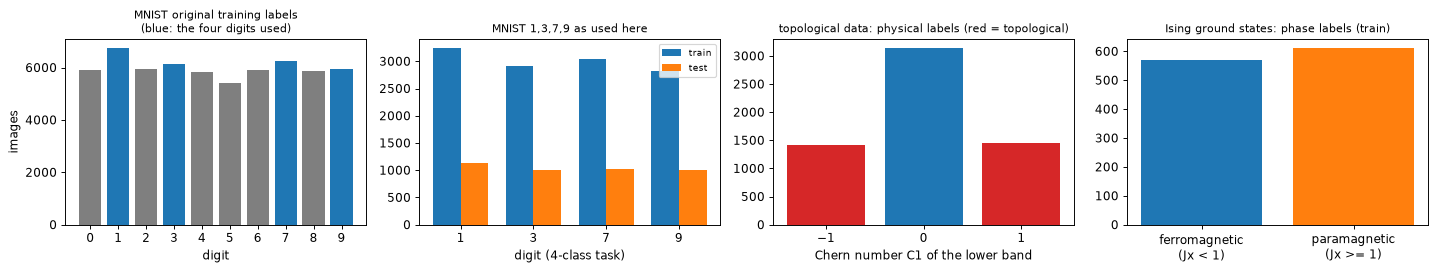

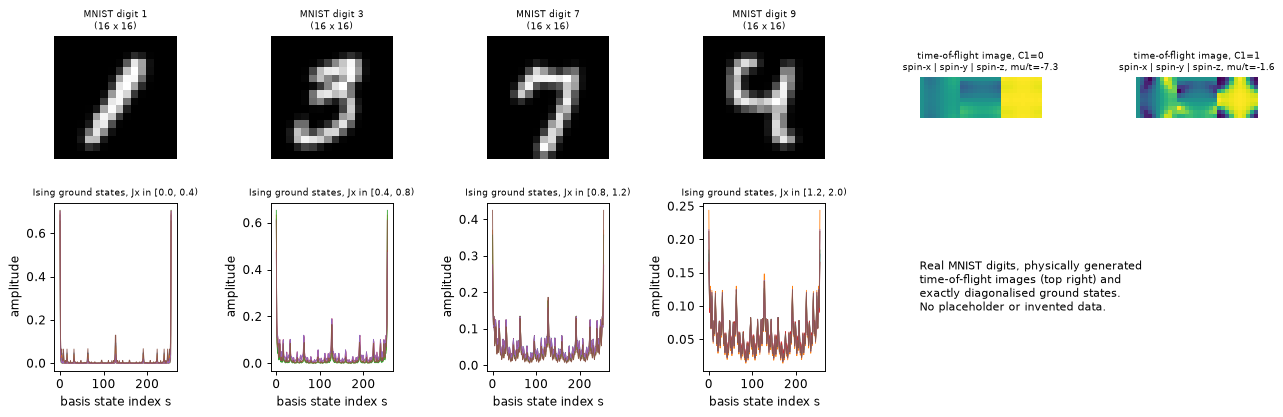

In [7]:
# ---- 1. shapes, feature names, original label values and class counts of every data set used ----
FEATURE_NAMES = {
    "MNIST (16 x 16 pixels)": [f"pixel_r{r}_c{c}" for r in range(IMG) for c in range(IMG)],
    "topological images (3 bases x 10 x 10 + padding)": [f"P_up_{b}(kx_{i},ky_{j})" for b in "xyz" for i in range(L_K) for j in range(L_K)] + [f"zero_padding_{i}" for i in range(212)],
    "Ising ground state (amplitudes)": [f"<s|psi>, s={format(s, '08b')}" for s in range(2 ** L_SPIN)],
}
for nm, fn in FEATURE_NAMES.items():
    print(f"{nm}: {len(fn)} features, {fn[0]} ... {fn[-1]}")
print()
rows = []
for nm, d, labels in [("MNIST 1 vs 9", BIN, "digit 1 -> 0, digit 9 -> 1"), ("MNIST 1,3,7,9", C4, "digits 1,3,7,9 -> 0..3"),
                      ("topological (QAH)", QAH, "label 0: Chern number C1 = 0, label 1: |C1| = 1"), ("Ising ground states", ISING, "0: ferromagnetic (Jx < 1), 1: paramagnetic (Jx >= 1)")]:
    for s, sn in [("tr", "train"), ("va", "validation"), ("te", "test")]:
        rows.append(dict(dataset=nm, split=sn, shape=str(d[s]["x"].shape), labels=np.unique(d[s]["y"]).tolist(), class_counts=np.bincount(d[s]["y"]).tolist(), label_meaning=labels))
display(pd.DataFrame(rows))
print("MNIST original label values (all ten digits) - counts in the COMPLETE official splits:")
print("  train:", dict(enumerate(MN["counts_train"].tolist())), "\n  test :", dict(enumerate(MN["counts_test"].tolist())))
print("Topological data: original (physical) label = Chern number of the lower band, counts in the training split:", {int(k): int(v) for k, v in zip(*np.unique(QAH['tr']['chern'], return_counts=True))})
print("   parameter ranges (train): J_x, J_y in [0.5, 1.5], t in [0.5, 1.5], mu/t in [-8, 8]; band gap >= 0.5 -> columns J_x, J_y, t, mu, e.g.", QAH['tr']['params'][0].round(3).tolist())
print("Ising data: original (physical) label = phase of H(J_x); J_x in [0, 2], critical point J_x = 1; first training values of J_x:", ISING['tr']['Jx'][:5].round(3).tolist())

# ---- 2. real class distributions ----
fig, ax = plt.subplots(1, 4, figsize=(17, 3.3))
cols_ = ["tab:grey"] * 10
for k in DIGITS:
    cols_[k] = "tab:blue"
ax[0].bar(range(10), MN["counts_train"], color=cols_); ax[0].set_xticks(range(10)); ax[0].set_xlabel("digit"); ax[0].set_ylabel("images")
ax[0].set_title("MNIST original training labels\n(blue: the four digits used)", fontsize=9)
w = 0.38
ax[1].bar(np.arange(4) - w / 2, np.bincount(C4["tr"]["y"], minlength=4), w, label="train"); ax[1].bar(np.arange(4) + w / 2, np.bincount(C4["te"]["y"], minlength=4), w, label="test")
ax[1].set_xticks(range(4)); ax[1].set_xticklabels([str(d) for d in DIGITS]); ax[1].set_xlabel("digit (4-class task)"); ax[1].legend(fontsize=8); ax[1].set_title("MNIST 1,3,7,9 as used here", fontsize=9)
ch = QAH["tr"]["chern"]; ax[2].bar([-1, 0, 1], [(ch == -1).sum(), (ch == 0).sum(), (ch == 1).sum()], color=["tab:red", "tab:blue", "tab:red"]); ax[2].set_xticks([-1, 0, 1])
ax[2].set_xlabel("Chern number C1 of the lower band"); ax[2].set_title("topological data: physical labels (red = topological)", fontsize=9)
ax[3].bar([0, 1], np.bincount(ISING["tr"]["y"]), color=["tab:blue", "tab:orange"]); ax[3].set_xticks([0, 1]); ax[3].set_xticklabels(["ferromagnetic\n(Jx < 1)", "paramagnetic\n(Jx >= 1)"])
ax[3].set_title("Ising ground states: phase labels (train)", fontsize=9)
plt.tight_layout(); plt.show()

# ---- 3. real samples ----
fig, ax = plt.subplots(2, 6, figsize=(15, 5.2))
for j, dgt in enumerate(DIGITS):
    i = int(np.where(C4["tr"]["digit"] == dgt)[0][0]); ax[0, j].imshow(C4["tr"]["x"][i].reshape(IMG, IMG), cmap="gray"); ax[0, j].set_title(f"MNIST digit {dgt}\n(16 x 16)", fontsize=8); ax[0, j].axis("off")
for j in range(2):
    ph = int(np.where(QAH["tr"]["y"] == j)[0][0]); img = QAH["tr"]["img"][ph]
    ax[0, 4 + j].imshow(np.concatenate([img[0], img[1], img[2]], axis=1), cmap="viridis", vmin=0, vmax=1); ax[0, 4 + j].axis("off")
    ax[0, 4 + j].set_title(f"time-of-flight image, C1={int(QAH['tr']['chern'][ph])}\nspin-x | spin-y | spin-z, mu/t={QAH['tr']['params'][ph, 3] / QAH['tr']['params'][ph, 2]:.1f}", fontsize=8)
for j, (a, b) in enumerate([(0.0, 0.4), (0.4, 0.8), (0.8, 1.2), (1.2, 2.0)]):
    idx = np.where((ISING["tr"]["Jx"] >= a) & (ISING["tr"]["Jx"] < b))[0][:6]
    for i in idx:
        ax[1, j].plot(ISING["tr"]["x"][i], lw=0.7)
    ax[1, j].set_title(f"Ising ground states, Jx in [{a}, {b})", fontsize=8); ax[1, j].set_xlabel("basis state index s"); ax[1, j].set_ylabel("amplitude")
for a in ax[1, 4:]:
    a.axis("off")
ax[1, 4].text(0, 0.5, "Real MNIST digits, physically generated\ntime-of-flight images (top right) and\nexactly diagonalised ground states.\nNo placeholder or invented data.", fontsize=9, va="center")
plt.tight_layout(); plt.show()


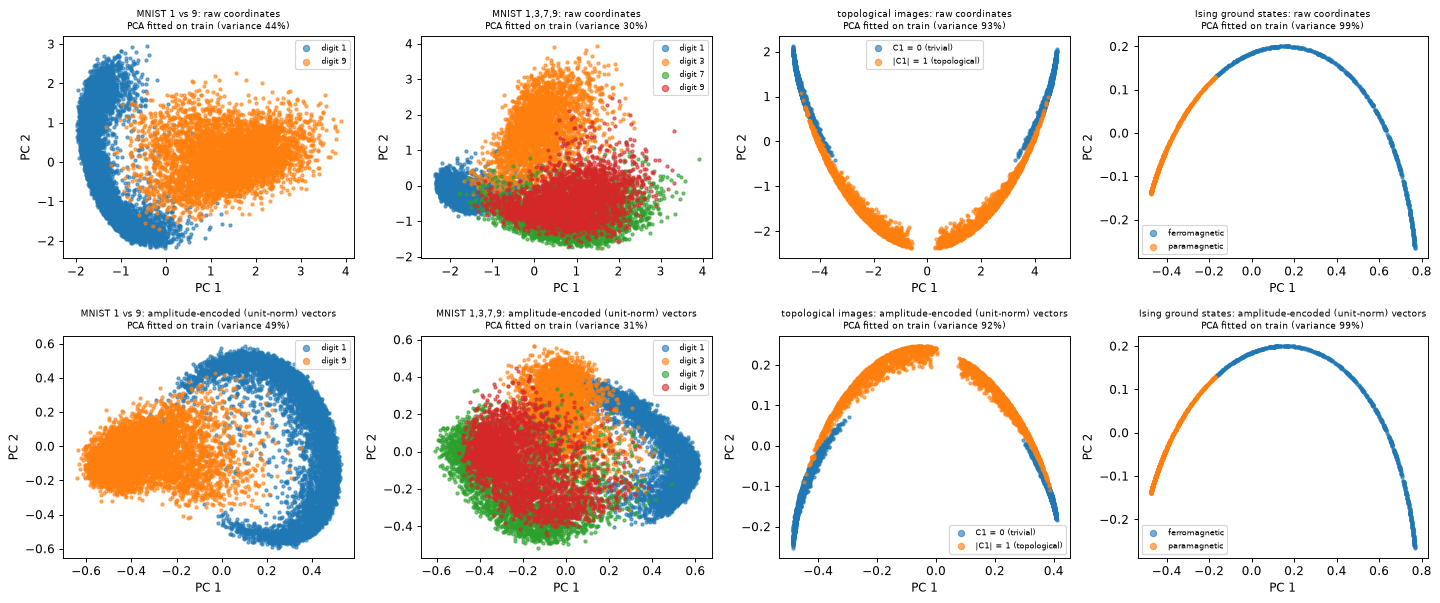

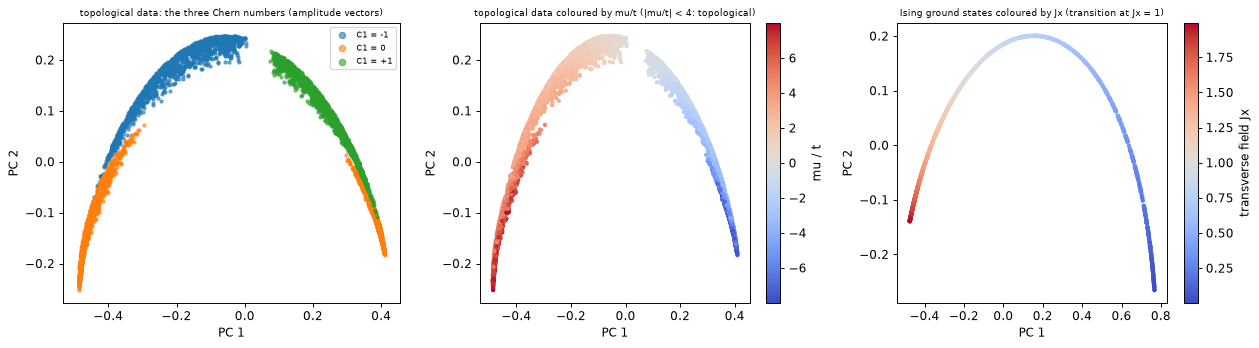

In [8]:
# ---- 4. 2-D scatter of REAL observations coloured by their ground-truth label (PCA fitted on the training split only) ----
# Row 1: raw coordinates (MNIST: pixel values; topological: the 300 spin-resolved probabilities; Ising: the ground-state amplitudes).
# Row 2: the same PCA fitted on the amplitude-encoded vectors = exactly what the circuits receive (unit norm).
# The circuits use AMPLITUDE encoding, so the angle scaling to [0, pi] of angle-encoding notebooks does not apply (no angles are produced).
def scatter(a, Z, y, names, title, cmap="tab10"):
    for c in np.unique(y):
        m = y == c
        a.scatter(Z[m, 0], Z[m, 1], s=7, alpha=0.6, label=names[c], color=plt.get_cmap(cmap)(c % 10))
    a.set_title(title, fontsize=8); a.set_xlabel("PC 1"); a.set_ylabel("PC 2"); a.legend(fontsize=7, markerscale=2)

panels = [("MNIST 1 vs 9", BIN, {0: "digit 1", 1: "digit 9"}, BIN["tr"]["y"]),
          ("MNIST 1,3,7,9", C4, {i: f"digit {d}" for i, d in enumerate(DIGITS)}, C4["tr"]["y"]),
          ("topological images", QAH, {0: "C1 = 0 (trivial)", 1: "|C1| = 1 (topological)"}, QAH["tr"]["y"]),
          ("Ising ground states", ISING, {0: "ferromagnetic", 1: "paramagnetic"}, ISING["tr"]["y"])]
fig, ax = plt.subplots(2, 4, figsize=(17, 7.2))
for j, (nm, d, names, y) in enumerate(panels):
    Xr = d["tr"]["x"]; Xa = Xr / (np.linalg.norm(Xr, axis=1, keepdims=True) + 1e-12)
    for r_, (X_, kind) in enumerate([(Xr, "raw coordinates"), (Xa, "amplitude-encoded (unit-norm) vectors")]):
        pca = PCA(n_components=2, random_state=SEED).fit(X_)
        scatter(ax[r_, j], pca.transform(X_), y, names, f"{nm}: {kind}\nPCA fitted on train (variance {pca.explained_variance_ratio_.sum():.0%})")
plt.tight_layout(); plt.show()

# the same for the physical parameters: topological data coloured by the Chern number (3 classes) and Ising data coloured by the continuous field J_x
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
Xa = QAH["tr"]["x"] / np.linalg.norm(QAH["tr"]["x"], axis=1, keepdims=True); Z = PCA(n_components=2, random_state=SEED).fit_transform(Xa)
scatter(ax[0], Z, QAH["tr"]["chern"] + 1, {0: "C1 = -1", 1: "C1 = 0", 2: "C1 = +1"}, "topological data: the three Chern numbers (amplitude vectors)")
mu_t = QAH["tr"]["params"][:, 3] / QAH["tr"]["params"][:, 2]
sc = ax[1].scatter(Z[:, 0], Z[:, 1], c=mu_t, s=7, cmap="coolwarm"); plt.colorbar(sc, ax=ax[1], label="mu / t"); ax[1].set_title("topological data coloured by mu/t (|mu/t| < 4: topological)", fontsize=8)
Zi = PCA(n_components=2, random_state=SEED).fit_transform(ISING["tr"]["x"])
sc = ax[2].scatter(Zi[:, 0], Zi[:, 1], c=ISING["tr"]["Jx"], s=7, cmap="coolwarm"); plt.colorbar(sc, ax=ax[2], label="transverse field Jx"); ax[2].set_title("Ising ground states coloured by Jx (transition at Jx = 1)", fontsize=8)
for a in ax:
    a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
plt.tight_layout(); plt.show()


## 2. An exact simulator, verified against Qiskit

Every attack needs hundreds of forward and backward passes through a circuit with 9-10 qubits and 10 layers, for hundreds of inputs at once. Qiskit's `Statevector` handles one circuit at a time, so the notebook uses a small
batched PyTorch state-vector simulator of exactly the circuit of Fig. 2 (all numbers in this notebook come from it). The qubit layout is Qiskit's: the n data qubits are qubits 0 .. n-1, the m output qubits are
qubits n .. n+m-1 (initialised to |1>), qubit 0 is the least significant bit, and a layer is "RZ(a) RX(b) RZ(c) on every qubit, then CNOT(0->1), CNOT(1->2), ..., CNOT(N-1->0)".
Two small matrix products apply the rotations of a whole layer (the Kronecker product of the single-qubit unitaries is split into a low and a high half), and one index permutation applies the CNOT ring.

In [9]:
# ----------------------------------------------------------------------------------------------------------------
# An exact, batched state-vector simulator of the paper's hardware-efficient classifier (Fig. 2), written in plain PyTorch.
#   * input: n data qubits (qubits 0..n-1) in the amplitude-encoded state |psi>, m output qubits (qubits n..n+m-1) in |1>^m
#   * p layers; layer i = rotation unit on EVERY qubit q:  Z(theta_c) X(theta_b) Z(theta_a)  (RZ(a) first, then RX(b), then RZ(c))
#     followed by the entangler: a ring of CNOTs  CNOT(0->1), CNOT(1->2), ..., CNOT(N-1->0)   # CHOICE: the paper only says "a series of CNOT gates"
#   * read-out: probability of every output-qubit bit string  g_k = <k| rho_out |k>  (diagonal of the reduced density matrix); label = argmax
# Qubit 0 is the least significant bit of the state index (Qiskit's convention), so the flat index is  data + 2^n * output.
# Why a custom simulator: every attack needs hundreds of forward/backward passes through circuits with 9-10 qubits; Qiskit's
# Statevector needs ~50 ms per circuit and no batching.  The next cell ASSERTS that this simulator equals the real Qiskit circuits.
# ----------------------------------------------------------------------------------------------------------------
CDT = torch.complex64

def euler_mats(th):
    """th[..., 3] = (a, b, c) -> 2x2 matrices of  RZ(c) RX(b) RZ(a)  (RZ(a) acts first, as in the circuit)."""
    a, b, c = th[..., 0], th[..., 1], th[..., 2]
    cb, sb = torch.cos(b / 2), torch.sin(b / 2)
    e = lambda z: torch.polar(torch.ones_like(z), z)
    m00 = e(-(a + c) / 2) * cb
    m01 = -1j * e((a - c) / 2) * sb
    m10 = -1j * e(-(a - c) / 2) * sb
    m11 = e((a + c) / 2) * cb
    return torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2)

def kron_msb_first(M):
    """M[..., j, 2, 2] with j = 0 the MOST significant qubit of the group -> Kronecker product of the matrices."""
    out = M[..., 0, :, :]
    for j in range(1, M.shape[-3]):
        n = out.shape[-1]
        out = torch.einsum("...ij,...kl->...ikjl", out, M[..., j, :, :]).reshape(*out.shape[:-2], 2 * n, 2 * n)
    return out

_PERM = {}
def cnot_ring_src(N):
    """new_state = old_state[:, src] for the CNOT ring CNOT(i -> i+1 mod N), i = 0..N-1, applied in this order."""
    if N not in _PERM:
        idx = np.arange(2 ** N); cur = idx.copy()
        for i in range(N):
            cur = cur ^ (((cur >> i) & 1) << ((i + 1) % N))      # image of every basis state under CNOT(i -> i+1)
        src = np.empty_like(cur); src[cur] = idx
        _PERM[N] = torch.as_tensor(src, dtype=torch.long)
    return _PERM[N]

def amp_normalise(v):
    """Amplitude encoding: the (real) input vector becomes the unit-norm state vector."""
    return v / (v.norm(dim=1, keepdim=True) + 1e-12)

def initial_state(psi, n, m):
    B = psi.shape[0]
    dt = torch.complex128 if psi.dtype in (torch.float64, torch.complex128) else CDT
    st = torch.zeros(B, 2 ** (n + m), dtype=dt)
    st[:, (2 ** m - 1) * 2 ** n:] = psi.to(dt)                 # |1>^m on the output qubits (index block 2^m - 1), |psi> on the data qubits
    return st

def circuit_state(psi, theta, n, m):
    """Final state [B, 2^(n+m)] of the classifier with parameters theta[p, N, 3] acting on |psi>|1..1>."""
    p, N, _ = theta.shape
    lo = N // 2; hi = N - lo
    cdt = CDT if theta.dtype == torch.float32 else torch.complex128
    U = euler_mats(theta).to(cdt)
    Ulo = kron_msb_first(U[:, :lo].flip(1)); Uhi = kron_msb_first(U[:, lo:].flip(1))   # the highest qubit of a group comes first in the Kronecker product
    s = initial_state(psi, n, m).to(cdt).reshape(-1, 2 ** hi, 2 ** lo)
    src = cnot_ring_src(N); B = s.shape[0]
    for l in range(p):
        s = Uhi[l] @ s @ Ulo[l].transpose(-1, -2)               # rotation unit of layer l on all qubits (two small matrix products)
        s = torch.index_select(s.reshape(B, 2 ** N), 1, src).reshape(B, 2 ** hi, 2 ** lo)   # entangler: permutation of the basis states
    return s.reshape(B, 2 ** N)

def class_probs(psi, theta, n, m):
    """g = diag(rho_out): probabilities of the 2^m output bit strings, shape [B, 2^m]."""
    st = circuit_state(psi, theta, n, m)
    return (st.real ** 2 + st.imag ** 2).reshape(-1, 2 ** m, 2 ** n).sum(-1)

class QC:
    """A trained (or to be trained) quantum classifier = architecture (n, m, p) + parameters theta[p, n+m, 3]."""
    def __init__(self, n, m, p, seed, std=None):
        self.n, self.m, self.p = n, m, p
        g = torch.Generator().manual_seed(seed)
        self.theta = (torch.randn(p, n + m, 3, generator=g) * (INIT_STD if std is None else std)).requires_grad_(True)
    @property
    def n_params(self): return int(self.theta.numel())
    def probs_psi(self, psi, theta=None):                      # psi: unit-norm real/complex states [B, 2^n]
        return class_probs(psi, self.theta if theta is None else theta, self.n, self.m)
    def probs(self, v, theta=None):                            # v: raw real vectors [B, 2^n] -> amplitude encoding -> probabilities
        return self.probs_psi(amp_normalise(v), theta)
    @torch.no_grad()
    def predict(self, v, bs=512):
        out = [self.probs(v[i:i + bs]).argmax(1) for i in range(0, len(v), bs)]
        return torch.cat(out)

def ce_loss(pr, y, reduction="mean"):
    """Eq. (2): cross entropy  -sum_k a_k log g_k  with one-hot a."""
    l = -torch.log(pr.gather(1, y[:, None]).squeeze(1) + 1e-7)
    return l.mean() if reduction == "mean" else (l.sum() if reduction == "sum" else l)

def T(x, dtype=torch.float32):
    return torch.as_tensor(np.asarray(x), dtype=dtype)


### Verification

The next cell builds the **real Qiskit circuit** (amplitude encoding with `StatePreparation`, X gates on the output qubits, layers of `rz`, `rx`, `cx`) and **asserts** that its state vector and its output-qubit probabilities equal the simulator's
(to 1e-10 in double precision, 1e-5 in the single precision used for training) for every architecture used below. A second assertion checks Eq. (3): the exact parameter-shift gradient equals the automatic-differentiation gradient that we use.

In [10]:
def qiskit_classifier(theta, n, m, psi=None, boxed=False):
    """The REAL Qiskit circuit of Fig. 2: amplitude encoding (StatePreparation) on the n data qubits, X on the m output qubits (|1>^m), then p layers of
    [RZ(a) RX(b) RZ(c) on every qubit] + [CNOT ring].  boxed=True wraps every layer in one gate (same circuit, shorter drawing)."""
    th = np.asarray(theta, dtype=float)
    p, N, _ = th.shape
    qc = QuantumCircuit(N, name=f"classifier_{n}+{m}q_p{p}")
    if psi is not None:
        qc.append(StatePreparation(np.asarray(psi, dtype=complex), label="amplitude\nencoding"), list(range(n)))
    for q in range(n, N):
        qc.x(q)
    for l in range(p):
        layer = QuantumCircuit(N, name=f"layer {l + 1}")
        for q in range(N):
            layer.rz(th[l, q, 0], q); layer.rx(th[l, q, 1], q); layer.rz(th[l, q, 2], q)    # Z(theta_c) X(theta_b) Z(theta_a): theta_a acts first
        for i in range(N):
            layer.cx(i, (i + 1) % N)
        if boxed:
            qc.append(layer.to_gate(label=f"layer {l + 1}"), list(range(N)))
        else:
            qc.compose(layer, inplace=True)
    return qc

def qiskit_probs(theta, n, m, psi):
    """Class probabilities from Qiskit's exact Statevector: marginal of the output qubits (qubits n..n+m-1)."""
    qc = qiskit_classifier(theta, n, m, psi)
    probs = Statevector(qc).probabilities(qargs=list(range(n, n + m)))   # little-endian: bit string of the output qubits as an integer
    return np.asarray(probs)

# ---- ASSERT: simulator == Qiskit, for random angles and random input states, for every architecture used below ----
chk = np.random.default_rng(SEED)
rows = []
for (n_, m_, p_) in [(8, 1, 10), (8, 2, 10), (9, 1, 10), (8, 1, 3)]:
    th = chk.normal(0, 1.0, (p_, n_ + m_, 3))
    psi = np.abs(chk.normal(size=2 ** n_)); psi /= np.linalg.norm(psi)
    qc = qiskit_classifier(th, n_, m_, psi)
    sv = Statevector(qc).data                                    # Qiskit: full final state vector
    mine = circuit_state(torch.as_tensor(psi[None]), torch.as_tensor(th), n_, m_)[0].numpy()     # float64 / complex128 path of our simulator
    mine32 = circuit_state(T(psi[None]), T(th), n_, m_)[0].numpy()                              # float32 / complex64 path (used for training)
    pr_q = qiskit_probs(th, n_, m_, psi)
    pr_m = class_probs(T(psi[None]), T(th), n_, m_)[0].numpy()
    e64 = np.abs(sv - mine).max(); e32 = np.abs(sv - mine32).max()
    assert e64 < 1e-10 and e32 < 1e-5 and np.allclose(pr_q, pr_m, atol=1e-5)
    rows.append(dict(architecture=f"n={n_} data + m={m_} output qubits, p={p_}", max_abs_state_diff_float64=e64, max_abs_state_diff_float32=e32,
                     max_prob_diff=float(np.abs(pr_q - pr_m).max()), qiskit_gates=sum(qc.count_ops().values())))
display(pd.DataFrame(rows))
print("ASSERTION PASSED: the batched PyTorch simulator reproduces the Qiskit state vector (and the output-qubit probabilities) of the real circuits.")

# ---- Eq. (3): parameter-shift rule  dg/dtheta = 1/2 [ g(theta + pi/2) - g(theta - pi/2) ]  equals the exact (autograd) gradient used for training ----
n_, m_, p_ = 8, 1, 4
th = torch.as_tensor(chk.normal(0, 1.0, (p_, n_ + m_, 3)), dtype=torch.float64).requires_grad_(True)
psi = torch.as_tensor(np.abs(chk.normal(size=(1, 2 ** n_))), dtype=torch.float64); psi = psi / psi.norm()
g1 = class_probs(psi, th, n_, m_)[0, 1]
(auto,) = torch.autograd.grad(g1, th)
worst = 0.0
for (l, q, k) in [(0, 0, 0), (0, 3, 1), (1, 8, 2), (3, 5, 1), (2, 1, 0), (3, 8, 2)]:
    d = torch.zeros_like(th); d[l, q, k] = math.pi / 2
    shift = 0.5 * (class_probs(psi, th.detach() + d, n_, m_)[0, 1] - class_probs(psi, th.detach() - d, n_, m_)[0, 1])
    worst = max(worst, abs(float(shift - auto[l, q, k])))
assert worst < 1e-10
print(f"ASSERTION PASSED: parameter-shift gradient (Eq. 3) equals the autograd gradient for 6 parameters (largest difference {worst:.1e}).")


,architecture,max_abs_state_diff_float64,max_abs_state_diff_float32,max_prob_diff,qiskit_gates
0,"n=8 data + m=1 output qubits, p=10",5.182616e-14,7.966635e-08,9.332675e-08,362
1,"n=8 data + m=2 output qubits, p=10",2.000403e-14,5.519378e-08,2.223354e-08,403
2,"n=9 data + m=1 output qubits, p=10",7.956300e-14,6.719238e-08,3.621326e-07,402
3,"n=8 data + m=1 output qubits, p=3",3.308783e-14,6.397581e-08,6.790372e-08,110


ASSERTION PASSED: the batched PyTorch simulator reproduces the Qiskit state vector (and the output-qubit probabilities) of the real circuits.
ASSERTION PASSED: parameter-shift gradient (Eq. 3) equals the autograd gradient for 6 parameters (largest difference 8.7e-17).


### 2.2 The attack library

The attacks of Appendix A (FGSM, BIM, MIM, PGD; additive in amplitude or pixel units; functional; targeted) and the depolarising noise are written once, here, for any model that exposes a function `prob_fn(v)` returning class probabilities,
so that the *same* code attacks the quantum classifier and the classical networks. They are explained in Section 4. The cell after the library checks the two non-trivial pieces against Qiskit: the random Pauli errors of the noise study
(equal to explicit Pauli operators) and the local-unitary layer of the functional attack (equal to Qiskit rz/rx/rz gates).

In [11]:
# ------------------------------------------------------------------------------------------------------------------------------
# White-box attacks of the paper's Appendix A, for ANY differentiable model with a function  prob_fn(v) -> class probabilities.
#   loss ascent (untargeted, Eq. 4) or descent on the target's loss (targeted, Eq. 5), sign of the gradient w.r.t. the INPUT components.
#   Q-FGSM (Alg. 1): one step of size eps.   Q-BIM (Alg. 2): T steps of size alpha = eps/T, projected back after every step.
#   MIM: momentum iterative method (decay mu).   PGD: BIM with a random start inside the l_inf ball of radius eps.
# Two "spaces" in which the components are perturbed (the paper's units are ambiguous, see the table above):
#   space="amp": v is the unit-norm amplitude vector |psi>; after every step it is re-normalised (the projection pi_C of Eq. A4).
#   space="pix": v are the raw pixel intensities in [0, 1] (clipped); amplitude encoding (normalisation) happens inside the model.
# ------------------------------------------------------------------------------------------------------------------------------
def fidelity_vec(a, b):
    """F = |<a|b>|^2 of the amplitude-encoded states of two batches of real vectors."""
    return (amp_normalise(a) * amp_normalise(b)).sum(1) ** 2

def input_grad(prob_fn, v, y, target=None, chunk=256):
    """Gradient of the (targeted: negative target) loss w.r.t. the input components; mini-batches of `chunk` rows bound the memory (the loss is a sum over samples)."""
    if len(v) > chunk:
        return torch.cat([input_grad(prob_fn, v[i:i + chunk], y[i:i + chunk], None if target is None else target[i:i + chunk], chunk) for i in range(0, len(v), chunk)])
    v = v.detach().clone().requires_grad_(True)
    pr = prob_fn(v)
    loss = ce_loss(pr, y, "sum") if target is None else -ce_loss(pr, target, "sum")      # ascend `loss`
    (g,) = torch.autograd.grad(loss, v)
    return g

def iterative_sign_attack(prob_fn, v0, y, steps, alpha, space="amp", target=None, momentum=None, ball=None, rand_start=False, gen=None, return_traj=True):
    """Returns the list [v_0, v_1, ..., v_steps] of attacked inputs (v_0 = clean)."""
    v0 = v0.detach()
    if space == "amp":
        v0 = amp_normalise(v0)
    v = v0.clone()
    if rand_start and ball is not None:
        v = v0 + (torch.rand(v0.shape, generator=gen) * 2 - 1) * ball
        v = amp_normalise(v) if space == "amp" else v.clamp(0, 1)
    traj = [v0.clone()] if return_traj else None
    mom = torch.zeros_like(v0)
    for _ in range(steps):
        g = input_grad(prob_fn, v, y, target)
        if momentum is not None:
            mom = momentum * mom + g / (g.abs().sum(1, keepdim=True) + 1e-12)
            g = mom
        v = v + alpha * torch.sign(g)
        if ball is not None:
            v = torch.min(torch.max(v, v0 - ball), v0 + ball)
        v = amp_normalise(v) if space == "amp" else v.clamp(0, 1)
        if return_traj:
            traj.append(v.clone())
    return traj if return_traj else v

def fgsm(prob_fn, v0, y, eps, space="amp", target=None, ball=None):
    return iterative_sign_attack(prob_fn, v0, y, 1, eps, space, target, ball=ball)[-1]

def bim(prob_fn, v0, y, T_, eps, space="amp", target=None, return_traj=False, ball=None):
    out = iterative_sign_attack(prob_fn, v0, y, T_, eps / T_, space, target, ball=ball, return_traj=return_traj)
    return out

def predict_fn(prob_fn, v, bs=512):
    with torch.no_grad():
        return torch.cat([prob_fn(v[i:i + bs]).argmax(1) for i in range(0, len(v), bs)])

def attack_batched(fn, v, y, bs=256, **kw):
    """Run an attack in mini-batches (bounds memory); fn(v_batch, y_batch, **kw) -> attacked batch (or list of per-step batches)."""
    outs = [fn(v[i:i + bs], y[i:i + bs], **kw) for i in range(0, len(v), bs)]
    if isinstance(outs[0], list):
        return [torch.cat([o[k] for o in outs]) for k in range(len(outs[0]))]
    return torch.cat(outs)

def summarise(prob_fn, v_clean, v_adv, y, target=None):
    """accuracy (true label still predicted), average fidelity, and (targeted) success rate of an attack."""
    pred = predict_fn(prob_fn, v_adv)
    d = dict(acc=float((pred == y).float().mean()), fid=float(fidelity_vec(v_clean, v_adv).mean()))
    if target is not None:
        d["success"] = float((pred == target).float().mean())
    return d

# ---- functional attack: a layer of local unitaries (Euler rotations on every DATA qubit) applied to the input state, parameters omega[B, n, 3] ----
def local_layer(psi, omega, n):
    """U(omega) |psi> with U = tensor product of RZ(c) RX(b) RZ(a) on the n data qubits; psi real or complex [B, 2^n]."""
    B = psi.shape[0]; lo = n // 2; hi = n - lo
    U = euler_mats(omega)
    Ulo = kron_msb_first(U[:, :lo].flip(1)); Uhi = kron_msb_first(U[:, lo:].flip(1))
    s = psi.to(CDT).reshape(B, 2 ** hi, 2 ** lo)
    return (Uhi @ s @ Ulo.transpose(-1, -2)).reshape(B, 2 ** n)

def functional_attack(qc, v0, y, steps, alpha, target=None):
    """BIM / FGSM in the space of the local-unitary parameters omega (starting from omega = 0 = identity).  Returns the list of attacked states per step."""
    psi0 = amp_normalise(v0.detach())
    om = torch.zeros(len(psi0), qc.n, 3)
    states = [psi0.to(CDT)]
    for _ in range(steps):
        gs = []
        for i in range(0, len(psi0), 256):                                   # mini-batches bound the memory
            o = om[i:i + 256].clone().requires_grad_(True)
            pr = qc.probs_psi(local_layer(psi0[i:i + 256], o, qc.n))
            loss = ce_loss(pr, y[i:i + 256], "sum") if target is None else -ce_loss(pr, target[i:i + 256], "sum")
            (g,) = torch.autograd.grad(loss, o); gs.append(g)
        om = om + alpha * torch.sign(torch.cat(gs))
        states.append(local_layer(psi0, om, qc.n).detach())
    return states

def fid_states(psi, phi):
    ov = (psi.to(CDT).conj() * phi.to(CDT)).sum(1)
    return ov.real ** 2 + ov.imag ** 2

def summarise_states(qc, psi_clean, states, y, target=None):
    with torch.no_grad():
        pred = torch.cat([qc.probs_psi(states[i:i + 512]).argmax(1) for i in range(0, len(states), 512)])
    d = dict(acc=float((pred == y).float().mean()), fid=float(fid_states(psi_clean, states).mean()))
    if target is not None:
        d["success"] = float((pred == target).float().mean())
    return d

# ---- depolarising noise, Eq. (6): on every DATA qubit, with probability beta an X, Y or Z error (1/3 each) -> one pure-state trajectory per realisation ----
def depolarise(psi, beta, n, gen):
    """psi [B, 2^n] real -> noisy states [B, 2^n] complex (one random realisation per row), and the Pauli pattern is applied exactly."""
    B = psi.shape[0]
    err = (torch.rand(B, n, generator=gen) < beta)
    kind = torch.randint(1, 4, (B, n), generator=gen) * err            # 0 = no error, 1 = X, 2 = Y, 3 = Z
    bits = (2 ** torch.arange(n))[None]
    flip = (((kind == 1) | (kind == 2)).long() * bits).sum(1)         # X and Y flip the bit
    zmask = (((kind == 2) | (kind == 3)).long() * bits).sum(1)        # Y and Z carry a (-1)^bit sign
    ny = (kind == 2).sum(1)
    idx = torch.arange(2 ** n)[None].expand(B, -1)
    par = torch.zeros_like(idx)
    t = idx & zmask[:, None]
    for q in range(n):
        par = par ^ ((t >> q) & 1)
    phase = (1 - 2 * par).to(torch.float32) * torch.pow(torch.tensor(1j, dtype=CDT), ny[:, None])
    out = torch.zeros(B, 2 ** n, dtype=CDT)
    out.scatter_(1, idx ^ flip[:, None], psi.to(CDT) * phase)         # new[b ^ flip] = i^{#Y} (-1)^{popcount(b & zmask)} old[b]
    return out


In [12]:
# ---- ASSERT: the random Pauli errors of the noise study equal explicit Pauli operators (Qiskit), and the functional-attack layer equals Qiskit's rz/rx/rz gates ----
from qiskit.quantum_info import Pauli, Operator
n_chk = 4
gen = torch.Generator().manual_seed(1)
psi_chk = torch.as_tensor(np.abs(np.random.default_rng(0).normal(size=(6, 2 ** n_chk))), dtype=torch.float32); psi_chk = psi_chk / psi_chk.norm(dim=1, keepdim=True)
g2 = torch.Generator().manual_seed(1)                                   # replay the same random draws to learn which Pauli string was applied
err = torch.rand(6, n_chk, generator=g2) < 0.5; kind = torch.randint(1, 4, (6, n_chk), generator=g2) * err
noisy = depolarise(psi_chk, 0.5, n_chk, gen)
worst = 0.0
for b in range(6):
    label = "".join("IXYZ"[int(kind[b, q])] for q in reversed(range(n_chk)))         # Qiskit's label is written with qubit n-1 on the left
    worst = max(worst, float(np.abs(Operator(Pauli(label)).data @ psi_chk[b].numpy().astype(complex) - noisy[b].numpy()).max()))
assert worst < 1e-6
omg = torch.as_tensor(np.random.default_rng(2).normal(0, 0.5, (3, n_chk, 3)), dtype=torch.float32)
lay = local_layer(psi_chk[:3], omg, n_chk)
for b in range(3):
    qc_l = QuantumCircuit(n_chk)
    for q in range(n_chk):
        qc_l.rz(float(omg[b, q, 0]), q); qc_l.rx(float(omg[b, q, 1]), q); qc_l.rz(float(omg[b, q, 2]), q)
    ref = Operator(qc_l).data @ psi_chk[b].numpy().astype(complex)
    assert np.abs(ref - lay[b].numpy()).max() < 1e-5
print(f"ASSERTIONS PASSED: depolarising trajectories == explicit Pauli operators (max diff {worst:.1e}); local_layer == Qiskit rz/rx/rz layer.")


ASSERTIONS PASSED: depolarising trajectories == explicit Pauli operators (max diff 2.8e-08); local_layer == Qiskit rz/rx/rz layer.

## 3. Training the quantum classifiers (Fig. 4, 5, 12a, 14) and the classical baselines

For each of the four tasks the classifier is trained with Adam on the cross-entropy loss of Eq. (2) (hyper-parameters in the configuration cell). The plots re-draw the paper's learning curves; the "train" curves are running averages over the
mini-batches of the epoch, the "validation" curves are computed on the full validation set after each epoch. The paper reports accuracies of about 98 % (1 vs 9), 91.6 % (four digits, depth 40), about 90 % (topological) and about 98 % (Ising).

In [13]:
def train_qc(qc, Xtr, ytr, Xva, yva, epochs, batch, lr, seed, batch_transform=None, tag="", verbose=True, epoch_cb=None):
    """Adam on the cross-entropy loss of Eq. (2), mini-batches, exact gradients by automatic differentiation (equal to the parameter-shift rule, checked above).
    batch_transform(qc, v, y) -> (v', y') lets adversarial training replace / extend every mini-batch.  Returns the history (one row per epoch).
    'train' columns are running averages over the mini-batches of the epoch (cheap); 'val' columns are computed on the whole validation set after the epoch."""
    opt = torch.optim.Adam([qc.theta], lr=lr)
    g = torch.Generator().manual_seed(seed)
    Xtr, ytr, Xva, yva = T(Xtr), torch.as_tensor(ytr), T(Xva), torch.as_tensor(yva)
    hist = []
    t0 = time.time()
    for ep in range(1, epochs + 1):
        perm = torch.randperm(len(Xtr), generator=g)
        tl, ta, nb = 0.0, 0.0, 0
        for i in range(0, len(Xtr), batch):
            idx = perm[i:i + batch]
            v, y = Xtr[idx], ytr[idx]
            if batch_transform is not None:
                v, y = batch_transform(qc, v, y)
            pr = qc.probs(v)
            loss = ce_loss(pr, y)
            opt.zero_grad(); loss.backward(); opt.step()
            tl += float(loss); ta += float((pr.argmax(1) == y).float().mean()); nb += 1
        with torch.no_grad():
            prv = torch.cat([qc.probs(Xva[i:i + 512]) for i in range(0, len(Xva), 512)])
            vl, va = float(ce_loss(prv, yva)), float((prv.argmax(1) == yva).float().mean())
        row = dict(epoch=ep, train_loss=tl / nb, train_acc=ta / nb, val_loss=vl, val_acc=va, seconds=time.time() - t0)
        if epoch_cb is not None:
            row.update(epoch_cb(qc, ep))
        hist.append(row)
        if verbose and (ep == 1 or ep % max(1, epochs // 5) == 0 or ep == epochs):
            print(f"  [{tag}] epoch {ep:3d}/{epochs}  train loss {tl / nb:.3f} acc {ta / nb:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time() - t0:6.1f}s", flush=True)
    return pd.DataFrame(hist)

def acc_of(qc, X, y):
    return float((qc.predict(T(X)) == torch.as_tensor(y)).float().mean())

def plot_history(h, title, paper_note=None, ax=None):
    ax = ax or plt.subplots(figsize=(5.2, 3.4))[1]
    ax.plot(h.epoch, h.val_acc, label="validation accuracy"); ax.plot(h.epoch, h.train_acc, label="training accuracy")
    ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.set_ylim(0.3, 1.02)
    ax2 = ax.twinx(); ax2.plot(h.epoch, h.val_loss, "--", color="C2", label="validation loss"); ax2.plot(h.epoch, h.train_loss, "--", color="C3", label="training loss"); ax2.set_ylabel("loss")
    ax.set_title(title, fontsize=9)
    l1, n1 = ax.get_legend_handles_labels(); l2, n2 = ax2.get_legend_handles_labels(); ax.legend(l1 + l2, n1 + n2, fontsize=7, loc="center right")
    return ax


training MNIST 1 vs 9 (Fig. 4): 9 qubits, depth 10, 270 trainable angles, 30 epochs, batch 256, lr 0.02


  [bin] epoch   1/30  train loss 0.488 acc 0.962 | val loss 0.417 acc 0.967 |    8.9s


  [bin] epoch   6/30  train loss 0.364 acc 0.981 | val loss 0.368 acc 0.968 |   56.2s


  [bin] epoch  12/30  train loss 0.359 acc 0.983 | val loss 0.364 acc 0.972 |  114.9s


  [bin] epoch  18/30  train loss 0.357 acc 0.983 | val loss 0.361 acc 0.975 |  180.0s


...

  [ising] epoch  40/100  train loss 0.287 acc 0.927 | val loss 0.296 acc 0.924 |   57.7s


  [ising] epoch  60/100  train loss 0.285 acc 0.922 | val loss 0.294 acc 0.924 |   84.4s


  [ising] epoch  80/100  train loss 0.287 acc 0.924 | val loss 0.292 acc 0.932 |  109.9s


  [ising] epoch 100/100  train loss 0.284 acc 0.927 | val loss 0.291 acc 0.932 |  137.5s


   test accuracy 0.9570   (138 s)



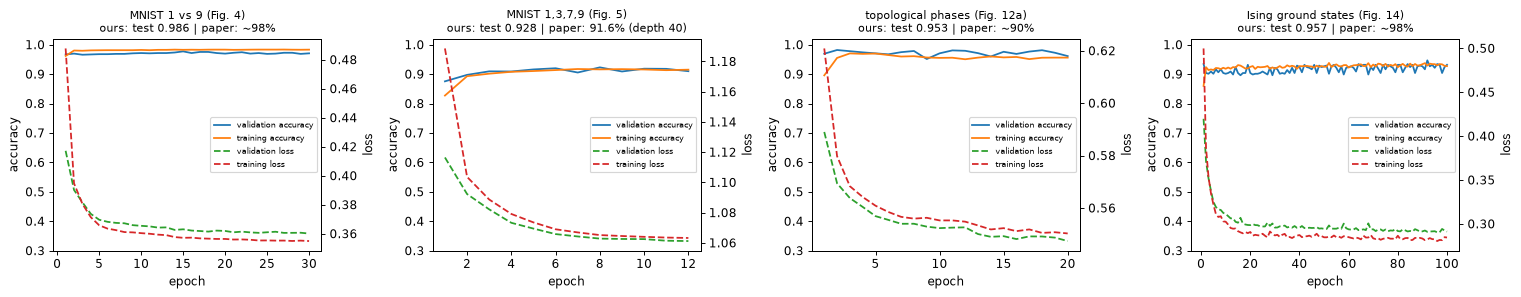

In [14]:
LR_BY = dict(bin=LR, c4=LR, qah=LR, ising=LR)
SPEC = {   # key -> (name, data, n data qubits, m output qubits, depth)
    "bin":   ("MNIST 1 vs 9 (Fig. 4)",            BIN,   8, 1, P_DEPTH),
    "c4":    ("MNIST 1,3,7,9 (Fig. 5)",           C4,    8, 2, P_DEPTH_4C),
    "qah":   ("topological phases (Fig. 12a)",    QAH,   9, 1, P_DEPTH),
    "ising": ("Ising ground states (Fig. 14)",    ISING, 8, 1, P_DEPTH),
}
def sub(key, n=None):
    """The first n (default N_ATTACK) TEST samples of a task: raw vectors and labels as tensors (the set that is attacked)."""
    d = SPEC[key][1]["te"]; n = n or N_ATTACK
    return T(d["x"][:n]), torch.as_tensor(d["y"][:n])

def subval(key, n):
    """The first n VALIDATION samples of a task. Attack budgets are calibrated on these (never on the test samples that the reported numbers come from)."""
    d = SPEC[key][1]["va"]
    return T(d["x"][:n]), torch.as_tensor(d["y"][:n])

QM, HIST, QTIME, TEST_ACC = {}, {}, {}, {}
for key, (name, d, n_, m_, p_) in SPEC.items():
    print(f"training {name}: {n_ + m_} qubits, depth {p_}, {3 * p_ * (n_ + m_)} trainable angles, {EPOCHS[key]} epochs, batch {BATCH[key]}, lr {LR_BY[key]}")
    qc = QC(n_, m_, p_, SEED)
    t0 = time.time()
    HIST[key] = train_qc(qc, d["tr"]["x"], d["tr"]["y"], d["va"]["x"], d["va"]["y"], EPOCHS[key], BATCH[key], LR_BY[key], SEED, tag=key)
    QTIME[key] = time.time() - t0
    QM[key] = qc
    qc.theta.requires_grad_(False)
    TEST_ACC[key] = acc_of(qc, d['te']['x'], d['te']['y'])
    print(f"   test accuracy {TEST_ACC[key]:.4f}   ({QTIME[key]:.0f} s)\n")

PAPER_NOTE = dict(bin="paper: ~98%", c4="paper: 91.6% (depth 40)", qah="paper: ~90%", ising="paper: ~98%")
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, (key, (name, *_)) in zip(ax, SPEC.items()):
    plot_history(HIST[key], f"{name}\nours: test {TEST_ACC[key]:.3f} | {PAPER_NOTE[key]}", ax=a)
plt.tight_layout(); plt.show()


### Classical baselines on exactly the same inputs

The inputs are the unit-norm amplitude vectors (256 numbers; 512 for the topological images) that the circuits receive. On them we train an `SVC` with an RBF kernel, a random forest and the paper's own classical feed-forward
network (Table V: FC(512)-ReLU-Dropout(0.1)-FC(53)-ReLU-Dropout(0.1)-FC(K)). The paper has no such baseline for the quantum classifier; it matters because the physics data are *easy* (a classical model is essentially perfect), so the quantum classifier is not
needed for accuracy, and because the same classical networks are attacked below with the same attacks.

In [15]:
# ---- classical models on EXACTLY the same inputs the circuits receive (the unit-norm amplitude vectors) ----
class FNN(nn.Module):
    """The paper's feed-forward net (Table V): FC(512)+ReLU, Dropout(0.1), FC(53)+ReLU, Dropout(0.1), FC(K)+softmax."""
    def __init__(self, d_in, k):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, 512), nn.ReLU(), nn.Dropout(0.1), nn.Linear(512, 53), nn.ReLU(), nn.Dropout(0.1), nn.Linear(53, k))
    def forward(self, v):
        return self.net(v)
    def probs(self, v):                                          # same interface as the quantum classifier: probabilities of every class
        return F.softmax(self.forward(v), dim=1)

def fit_torch_clf(model, X, y, epochs, lr=1e-3, batch=256, seed=SEED):
    """Adam, cross-entropy; Keras-style training of the paper's classical nets."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    X, y = T(X), torch.as_tensor(y)
    model.train()
    for ep in range(epochs):
        perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(X), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    return model

BASE_EPOCHS = 25 if FAST_MODE else 30             # CHOICE: the FNN sees only a few thousand amplitude vectors, so it needs many small epochs
TASKS = {                                          # name -> (data, number of classes, qubits n, m)
    "MNIST 1 vs 9":  dict(d=BIN, k=2, n=8, m=1, key="bin"),
    "MNIST 1,3,7,9": dict(d=C4, k=4, n=8, m=2, key="c4"),
    "topological (QAH)": dict(d=QAH, k=2, n=9, m=1, key="qah"),
    "Ising ground states": dict(d=ISING, k=2, n=8, m=1, key="ising"),
}
def amp_np(x):
    x = np.asarray(x, np.float32)
    return x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-12)

BASE, FNNS = {}, {}
rows = []
for name, tk in TASKS.items():
    d = tk["d"]
    Xtr, ytr, Xte, yte = amp_np(d["tr"]["x"]), d["tr"]["y"], amp_np(d["te"]["x"]), d["te"]["y"]
    t0 = time.time(); svc = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED).fit(Xtr, ytr); a_svc = svc.score(Xte, yte); t_svc = time.time() - t0
    t0 = time.time(); rf = RandomForestClassifier(n_estimators=RF_TREES, random_state=SEED, n_jobs=1).fit(Xtr, ytr); a_rf = rf.score(Xte, yte); t_rf = time.time() - t0
    t0 = time.time(); fnn = fit_torch_clf(FNN(Xtr.shape[1], tk["k"]), Xtr, ytr, BASE_EPOCHS);
    with torch.no_grad():
        a_fnn = float((fnn(T(Xte)).argmax(1) == torch.as_tensor(yte)).float().mean())
    t_fnn = time.time() - t0
    FNNS[tk["key"]] = fnn
    rows.append({"task": name, "inputs": Xtr.shape[1], "SVC(rbf) acc": a_svc, "RandomForest acc": a_rf, "FNN acc": a_fnn,
                 "fit time SVC/RF/FNN (s)": f"{t_svc:.1f}/{t_rf:.1f}/{t_fnn:.1f}"})
BASE_TABLE = pd.DataFrame(rows)
display(BASE_TABLE.round(4))


,task,inputs,SVC(rbf) acc,RandomForest acc,FNN acc,fit time SVC/RF/FNN (s)
0,MNIST 1 vs 9,256,0.9977,0.9967,0.9967,3.1/43.5/44.3
1,"MNIST 1,3,7,9",256,0.9868,0.9790,0.9854,19.7/76.4/43.1
2,topological (QAH),512,1.0000,1.0000,1.0000,1.8/30.1/28.4
3,Ising ground states,256,1.0000,1.0000,1.0000,0.1/2.9/3.9


## Quantum Circuit Architecture

Every gate-based quantum model of this notebook is one of the following architectures; the drawings are the Qiskit circuits **that are executed** (`circuit.draw("mpl")` of the flat circuit, with the trained weights and a real test input), not illustrations.
Each drawing is folded over several rows: first the amplitude encoding of the data qubits and the X gates that set the output qubit(s) to |1>, then p = 10 layers of [RZ(a) RX(b) RZ(c) on every qubit, CNOT ring].
For every architecture the cell asserts that (a) the drawn circuit gives the same output probabilities as the simulator used for all results, (b) a version with one gate per layer gives the same probabilities as well, and (c) the number of
RZ/RX gates equals the number of trainable angles, 3 x layers x qubits. The table lists qubits, depth (of the flat circuit) and trainable-parameter count.

* **A** - 8 data + 1 output qubit: MNIST 1 vs 9, Ising ground states, and the adversarially trained / noise-trained models.
* **B** - 8 data + 2 output qubits: MNIST 1, 3, 7, 9.
* **C** - 9 data + 1 output qubit: the topological images (300 values padded to 512 amplitudes).
* **D** - the pipeline of the *functional attack*: a layer of RZ RX RZ on every data qubit (24 adversarial angles) in front of classifier A.

Assumptions where the paper omits circuit details: the entangler is a CNOT ring (the paper says "a series of CNOT gates"), the rotation unit is applied to the output qubits as well, the data qubits are the low qubits and the output qubits come
after them, and the depth is 10 (the paper uses 10, 20 and 40 in different experiments). The attacks of the paper act on the *input state* only; the noise study inserts random Pauli gates on the data qubits (architecture A or B, same circuit).

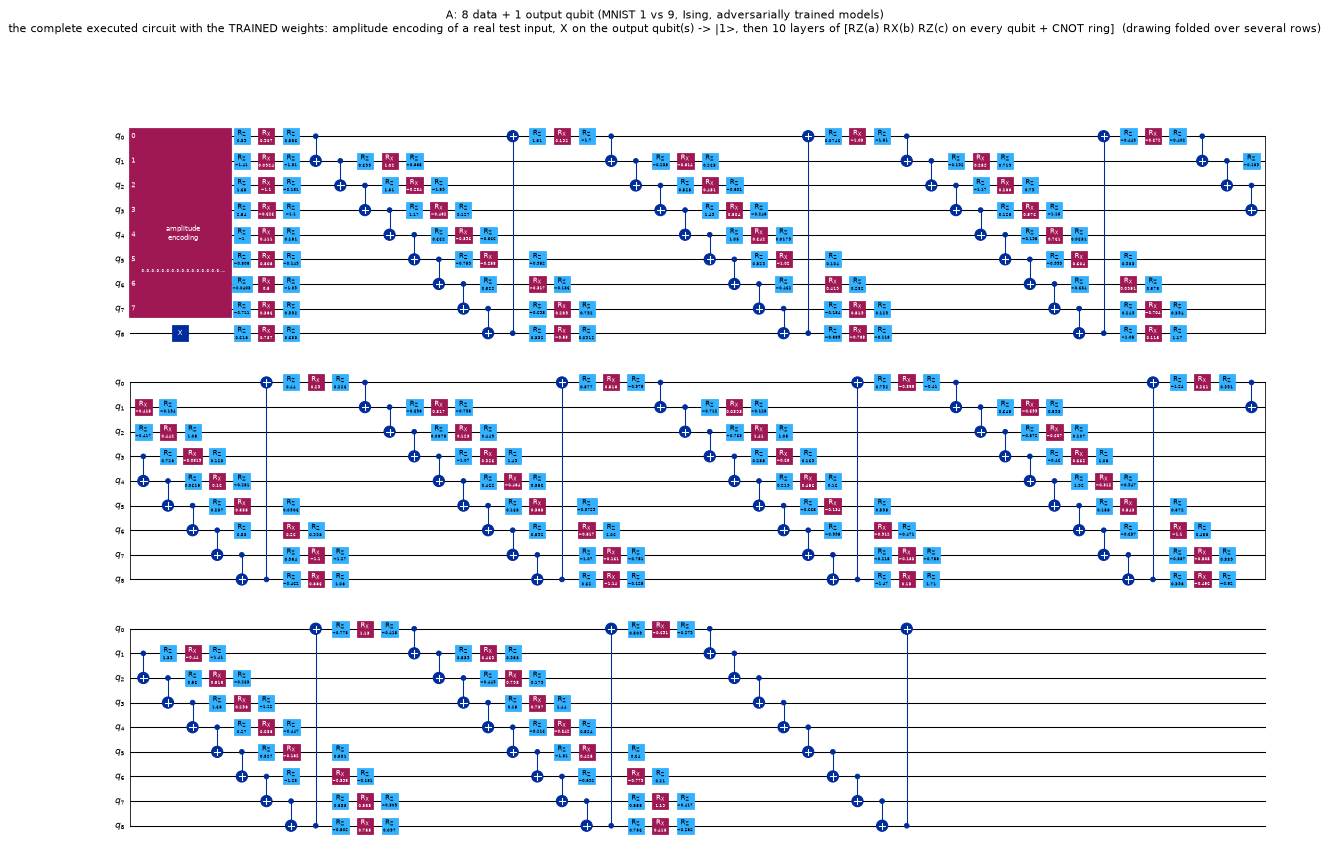

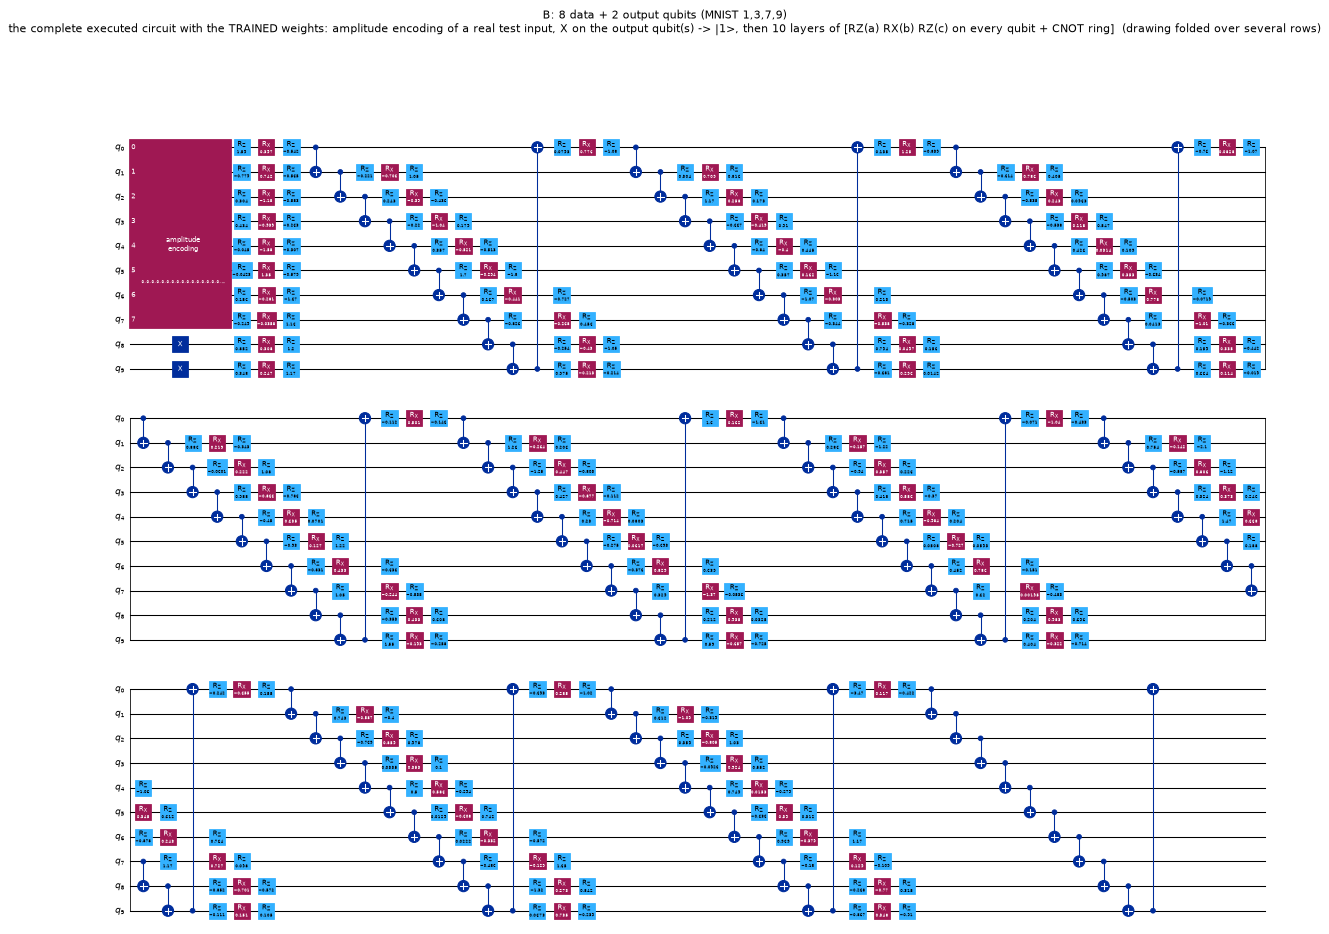

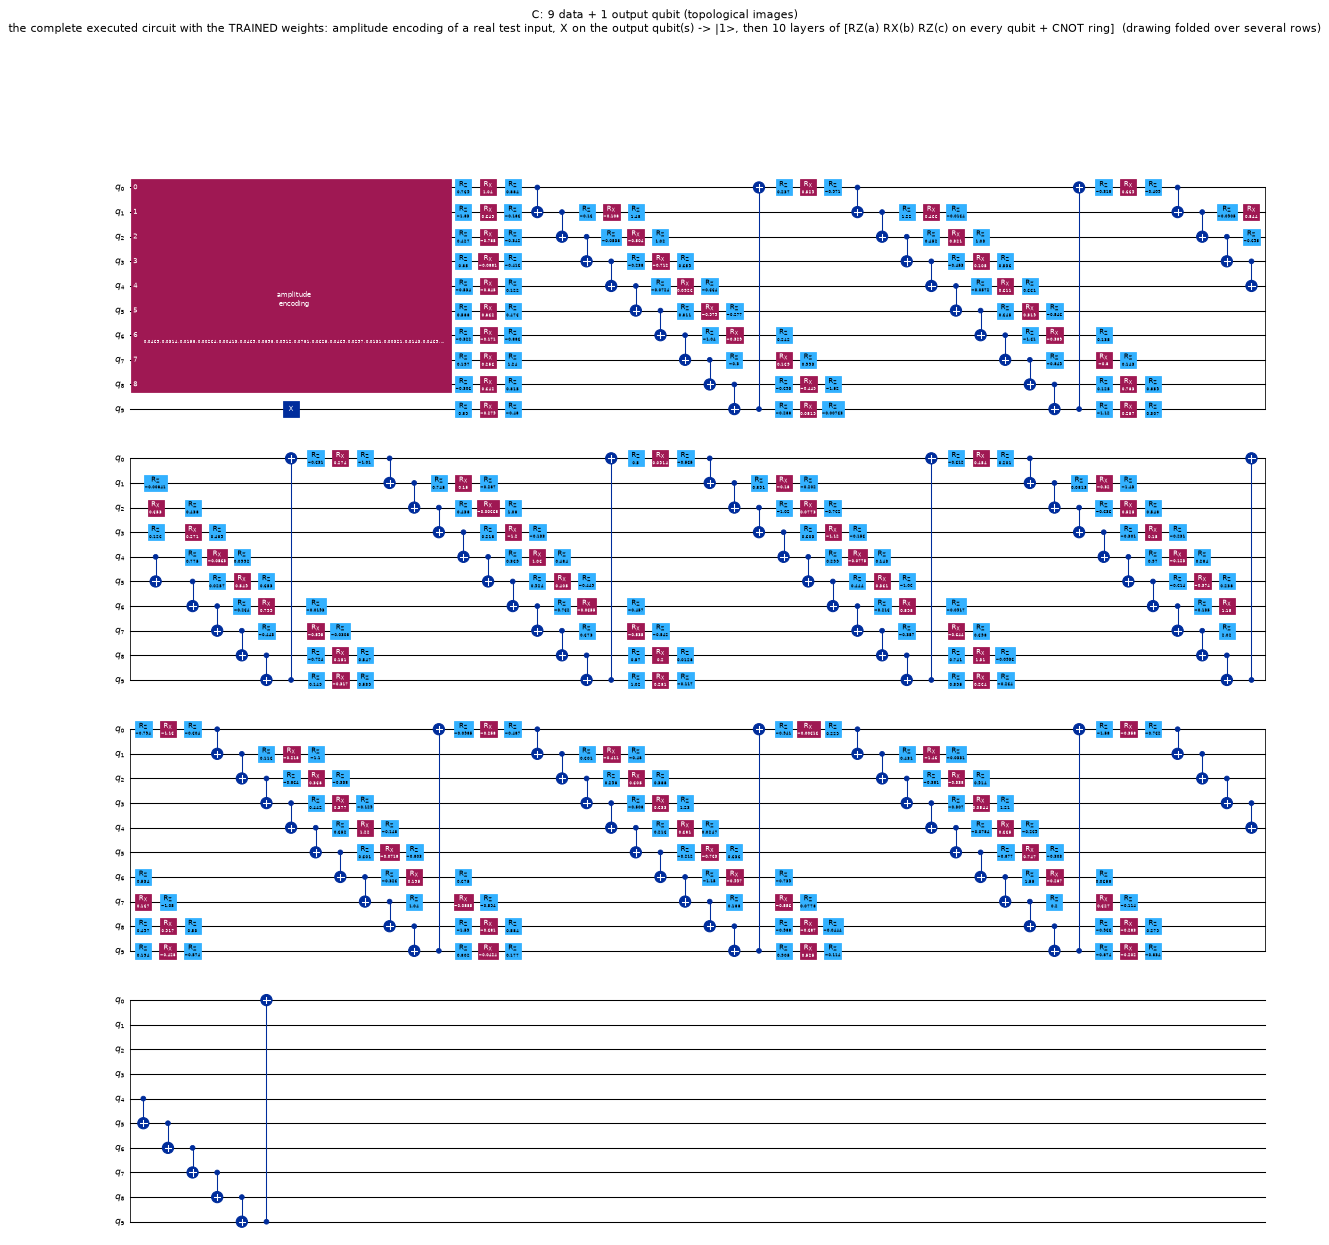

,architecture,qubits,depth_flat_circuit,layers,rotation_gates_RZ_RX,CNOT_gates,trainable_angles,all_gates
0,"A: 8 data + 1 output qubit (MNIST 1 vs 9, Ising, adversarially trained models)",9,121,10,270,90,270,362
1,"B: 8 data + 2 output qubits (MNIST 1,3,7,9)",10,131,10,300,100,300,403
2,C: 9 data + 1 output qubit (topological images),10,131,10,300,100,300,402


ASSERTIONS PASSED: for the trained weights of every architecture the Qiskit circuits (flat and boxed) give the same output probabilities as the simulator used for all results, and the number of RZ/RX gates equals the number of trainable angles = 3 x layers x qubits.


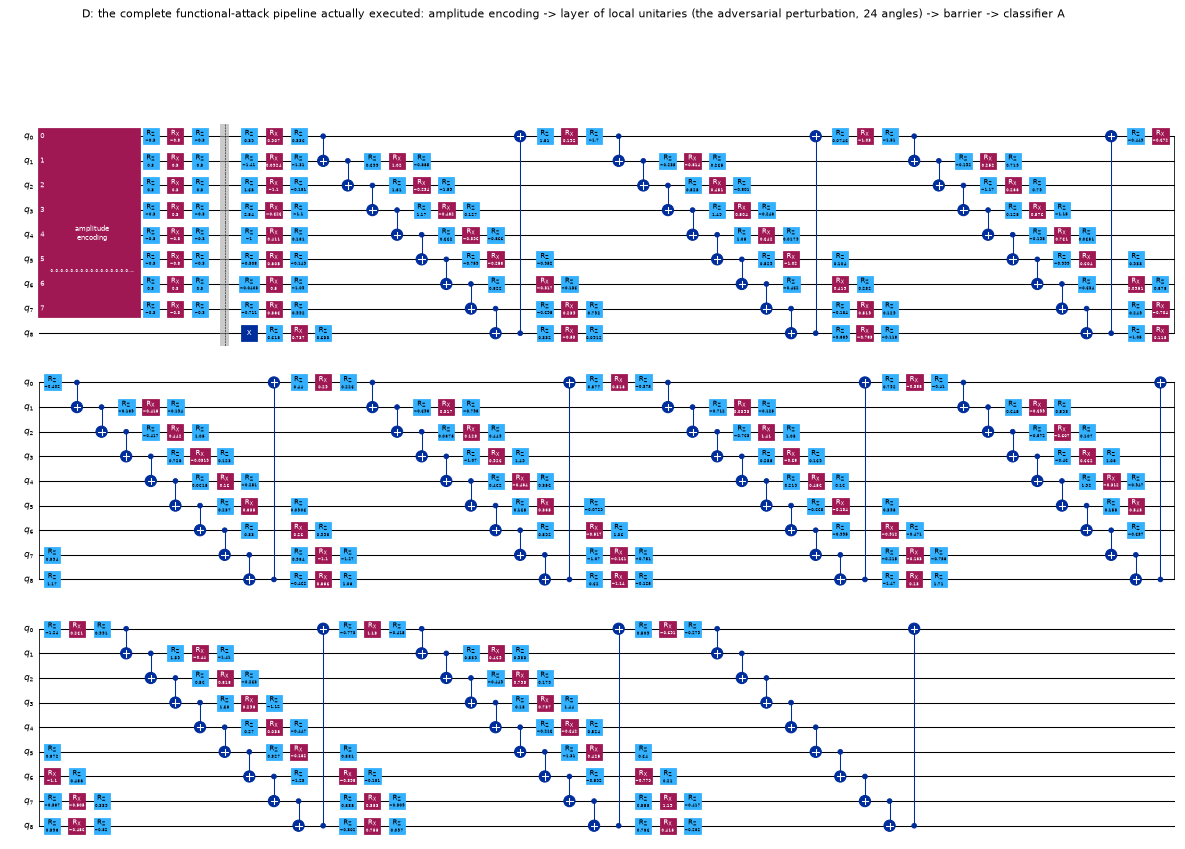

D: qubits 9, depth 124, trainable angles of the classifier 270 (frozen during the attack) + 24 adversarial angles (the attacker's parameters)
ASSERTION PASSED: the functional-attack pipeline in Qiskit equals the simulator used for Fig. 8 / Fig. 10(c,d).


In [16]:
def unit64(x):
    """Amplitude-encode in float64 (Qiskit's StatePreparation insists on a norm of 1 to 1e-10)."""
    x = np.asarray(x, dtype=np.float64)
    return x / np.linalg.norm(x, axis=-1, keepdims=True)

def qiskit_functional_pipeline(omega, theta, n, m, psi, boxed=True):
    """Executed pipeline of the functional attack: amplitude encoding -> layer of local unitaries (RZ RX RZ on every DATA qubit, parameters omega[n, 3]) -> classifier."""
    N = n + m
    qc = QuantumCircuit(N, name="functional_attack+classifier")
    qc.append(StatePreparation(np.asarray(psi, dtype=complex), label="amplitude\nencoding"), list(range(n)))
    for q in range(n):
        qc.rz(omega[q, 0], q); qc.rx(omega[q, 1], q); qc.rz(omega[q, 2], q)             # the adversarial layer of local unitaries (Euler angles, near the identity)
    qc.barrier()
    qc.compose(qiskit_classifier(theta, n, m, psi=None, boxed=boxed), inplace=True)     # X on the output qubit(s), then the p classifier layers
    return qc

def one_layer(th_layer, N):
    """Layer 1 of the classifier on its own (rotation unit on every qubit + CNOT ring), for the expanded drawing."""
    lay = QuantumCircuit(N, name="layer 1")
    for q in range(N):
        lay.rz(th_layer[q, 0], q); lay.rx(th_layer[q, 1], q); lay.rz(th_layer[q, 2], q)
    for i in range(N):
        lay.cx(i, (i + 1) % N)
    return lay

ARCH = {   # distinct architectures that are trained / evaluated in this notebook
    "A: 8 data + 1 output qubit (MNIST 1 vs 9, Ising, adversarially trained models)": ("bin", 8, 1),
    "B: 8 data + 2 output qubits (MNIST 1,3,7,9)": ("c4", 8, 2),
    "C: 9 data + 1 output qubit (topological images)": ("qah", 9, 1),
}
rows = []
for name, (key, n_, m_) in ARCH.items():
    qc_m = QM[key]; th = qc_m.theta.detach().double().numpy()
    psi_all = unit64(SPEC[key][1]["te"]["x"][:3])
    qflat = qiskit_classifier(th, n_, m_, psi_all[0])                                           # flat gate-level circuit
    # ---- ASSERT: the circuit that is drawn is the circuit that is executed: flat == boxed (one gate per layer) == simulator, now with the TRAINED weights on real test inputs ----
    for i in range(3):
        pq = qiskit_probs(th, n_, m_, psi_all[i])
        pb = Statevector(qiskit_classifier(th, n_, m_, psi_all[i], boxed=True)).probabilities(qargs=list(range(n_, n_ + m_)))
        ps = qc_m.probs_psi(T(psi_all[i:i + 1]))[0].numpy()
        assert np.allclose(pq, ps, atol=1e-5) and np.allclose(pb, ps, atol=1e-5), "drawn circuit differs from the simulator"
    n_rot = sum(1 for inst in qflat.data if inst.operation.name in ("rz", "rx")); n_cx = qflat.count_ops().get("cx", 0)
    assert n_rot == qc_m.n_params, "number of rotation gates != number of trainable angles"
    rows.append(dict(architecture=name, qubits=n_ + m_, depth_flat_circuit=qflat.depth(), layers=qc_m.p, rotation_gates_RZ_RX=n_rot, CNOT_gates=n_cx,
                     trainable_angles=qc_m.n_params, all_gates=sum(qflat.count_ops().values())))
    fig = qflat.draw("mpl", fold=46, scale=0.45)
    fig.suptitle(f"{name}\nthe complete executed circuit with the TRAINED weights: amplitude encoding of a real test input, X on the output qubit(s) -> |1>, then {qc_m.p} layers of "
                 f"[RZ(a) RX(b) RZ(c) on every qubit + CNOT ring]  (drawing folded over several rows)", fontsize=9, y=0.995)
    display(fig); plt.close(fig)
ARCH_TABLE = pd.DataFrame(rows); display(ARCH_TABLE)
print("ASSERTIONS PASSED: for the trained weights of every architecture the Qiskit circuits (flat and boxed) give the same output probabilities as the simulator used for all results, "
      "and the number of RZ/RX gates equals the number of trainable angles = 3 x layers x qubits.")

# ---- D: the executed pipeline of the functional attack (local-unitary layer + classifier A) ----
th = QM["bin"].theta.detach().double().numpy(); Xe, ye = sub("bin", 3); psi64 = unit64(Xe.numpy()); psi_t = amp_normalise(Xe)
omega = torch.zeros(3, 8, 3)
for _ in range(3):                                                                              # three functional BIM steps (angles in radians); keep the angles for the drawing
    o = omega.clone().requires_grad_(True)
    loss = ce_loss(QM["bin"].probs_psi(local_layer(psi_t, o, 8)), ye, "sum"); (g,) = torch.autograd.grad(loss, o); omega = omega + F_STEP * torch.sign(g)
for i in range(3):
    qd = qiskit_functional_pipeline(omega[i].numpy().astype(float), th, 8, 1, psi64[i], boxed=False)
    pq = Statevector(qd).probabilities(qargs=[8])
    ps = QM["bin"].probs_psi(local_layer(psi_t[i:i + 1], omega[i:i + 1], 8))[0].detach().numpy()
    assert np.allclose(pq, ps, atol=1e-5), "functional-attack pipeline differs from the simulator"
qd_flat = qiskit_functional_pipeline(omega[0].numpy().astype(float), th, 8, 1, psi64[0], boxed=False)
fig = qd_flat.draw("mpl", fold=46, scale=0.45)
fig.suptitle("D: the complete functional-attack pipeline actually executed: amplitude encoding -> layer of local unitaries (the adversarial perturbation, 24 angles) -> barrier -> classifier A", fontsize=9, y=0.995)
display(fig); plt.close(fig)
print(f"D: qubits {qd_flat.num_qubits}, depth {qd_flat.depth()}, trainable angles of the classifier {QM['bin'].n_params} (frozen during the attack) + {3 * 8} adversarial angles (the attacker's parameters)")
print("ASSERTION PASSED: the functional-attack pipeline in Qiskit equals the simulator used for Fig. 8 / Fig. 10(c,d).")


## 4. White-box and black-box attacks

All attacks below take the gradient of the loss with respect to the **input** (an exact gradient through the simulator) and move the input along the sign of that gradient (FGSM/BIM), with momentum (MIM) or from a random start in an
l_inf ball (PGD). Three things to keep in mind when comparing with the paper:

* **fidelity** F = |<psi_adv|psi>|^2 measures how far the attacked state is from the clean one; the *average fidelity* of a set of attacked states is what Tables I, II, IV and Figs. 7, 8, 10, 11 report;
* **units**: the paper does not say in which units its step sizes (0.1, 0.03, 0.05 ...) are measured. In *amplitude units* a step of 0.03 on each of the 256 components of a unit vector already changes the state a lot; in *pixel units*
  it is a small change of a picture. We run both readings with the paper's literal numbers and add the unit-free **iso-fidelity** comparison (the budget is calibrated so that the average fidelity equals the paper's);
* the attacked set is the first `N_ATTACK` test samples, counting **all** of them (also those that were wrong before the attack), as the paper does.

### 4.1 Untargeted additive attacks: Table I

The paper attacks the two-category classifier with BIM(3, 0.1) and FGSM(1, 0.03) and the four-category classifier with BIM(3, 0.1) and FGSM(1, 0.05) and lists the average fidelity and the remaining accuracy (Table I).
For each of the four attacks the table below shows (1) the literal numbers in amplitude units, (2) the literal numbers in pixel units, and (3) the amplitude-space budget at which our average fidelity equals the paper's, with the accuracy that is left there.

In [17]:
R = {}                                                                 # results used by the final comparison table
def calib_eps(make, v0, target_f, lo=1e-4, hi=1.0, iters=9):
    """Bisection (in log scale) on the budget eps so that the AVERAGE fidelity of the attacked states equals target_f."""
    for _ in range(iters):
        mid = math.sqrt(lo * hi)
        f = float(fidelity_vec(v0, make(mid)).mean())
        lo, hi = (mid, hi) if f > target_f else (lo, mid)
    return math.sqrt(lo * hi)

# ============ Table I: untargeted additive attacks on the 2-category and 4-category classifiers ============
NC = max(100, N_ATTACK // 2)                                           # CHOICE: the calibration of eps uses NC validation samples
rows = []
for key, atks in [("bin", [("BIM(3,0.1)", 3, 0.1), ("FGSM(1,0.03)", 1, 0.03)]), ("c4", [("BIM(3,0.1)", 3, 0.1), ("FGSM(1,0.05)", 1, 0.05)])]:
    qc = QM[key]; X, y = sub(key); pf = qc.probs
    clean = float((qc.predict(X) == y).float().mean())
    for name, steps, eps in atks:
        pF, pA = PAPER["table1"][(key, name)]
        for space in ["amp", "pix"]:
            v0 = amp_normalise(X) if space == "amp" else X
            adv = bim(pf, v0, y, steps, eps, space) if steps > 1 else fgsm(pf, v0, y, eps, space)
            s = summarise(pf, v0, adv, y)
            rows.append(dict(model=SPEC[key][0].split(" (")[0], attack=name, units=("amplitude" if space == "amp" else "pixel"), how="literal parameters",
                             eps_used=eps, fidelity=s["fid"], accuracy=s["acc"], paper_fidelity=pF, paper_accuracy=pA))
        # unit-free comparison: the amplitude-space budget whose average fidelity equals the paper's, then the accuracy that remains
        Xv, yc = subval(key, NC); v0 = amp_normalise(Xv)                    # calibrate on VALIDATION samples, report on the test samples
        make = (lambda e, steps=steps: bim(pf, v0, yc, steps, e, "amp")) if steps > 1 else (lambda e: fgsm(pf, v0, yc, e, "amp"))
        e_cal = calib_eps(make, v0, pF)
        v0f = amp_normalise(X)
        adv = bim(pf, v0f, y, steps, e_cal, "amp") if steps > 1 else fgsm(pf, v0f, y, e_cal, "amp")
        s = summarise(pf, v0f, adv, y)
        rows.append(dict(model=SPEC[key][0].split(" (")[0], attack=name, units="amplitude", how="iso-fidelity (eps calibrated to the paper's F)",
                         eps_used=e_cal, fidelity=s["fid"], accuracy=s["acc"], paper_fidelity=pF, paper_accuracy=pA))
    R[f"clean_{key}"] = clean
TABLE_I = pd.DataFrame(rows)
display(TABLE_I.round(3))
R["table1"] = TABLE_I


,model,attack,units,how,eps_used,fidelity,accuracy,paper_fidelity,paper_accuracy
0,MNIST 1 vs 9,"BIM(3,0.1)",amplitude,literal parameters,0.100,0.217,0.000,0.923,0.156
1,MNIST 1 vs 9,"BIM(3,0.1)",pixel,literal parameters,0.100,0.892,0.777,0.923,0.156
2,MNIST 1 vs 9,"BIM(3,0.1)",amplitude,iso-fidelity (eps calibrated to the paper's F),0.018,0.923,0.839,0.923,0.156
3,MNIST 1 vs 9,"FGSM(1,0.03)",amplitude,literal parameters,0.030,0.809,0.480,0.901,0.000
4,MNIST 1 vs 9,"FGSM(1,0.03)",pixel,literal parameters,0.030,0.989,0.974,0.901,0.000
5,MNIST 1 vs 9,"FGSM(1,0.03)",amplitude,iso-fidelity (eps calibrated to the paper's F),0.021,0.900,0.793,0.901,0.000
6,"MNIST 1,3,7,9","BIM(3,0.1)",amplitude,literal parameters,0.100,0.263,0.000,0.943,0.237
7,"MNIST 1,3,7,9","BIM(3,0.1)",pixel,literal parameters,0.100,0.910,0.412,0.943,0.237
8,"MNIST 1,3,7,9","BIM(3,0.1)",amplitude,iso-fidelity (eps calibrated to the paper's F),0.016,0.942,0.439,0.943,0.237
9,"MNIST 1,3,7,9","FGSM(1,0.05)",amplitude,literal parameters,0.050,0.610,0.000,0.528,0.000


### 4.2 Fig. 7: accuracy versus BIM iteration and versus average fidelity

The paper's Fig. 7: the accuracy falls to zero after about five BIM iterations (step 0.1) and, at that point, the average fidelity is still larger than 0.73. We draw the same curves with the paper's literal pixel-unit step (0.1) and with a small
amplitude-unit step (0.01), together with the **classical FNN of the paper on the same inputs under the same attack**. Below the figure a unit-free check: for every test state we follow a fine BIM path (small steps, until the label flips) and record the fidelity at the
first misclassification. The histograms show how far a state has to move before the classifier is wrong.

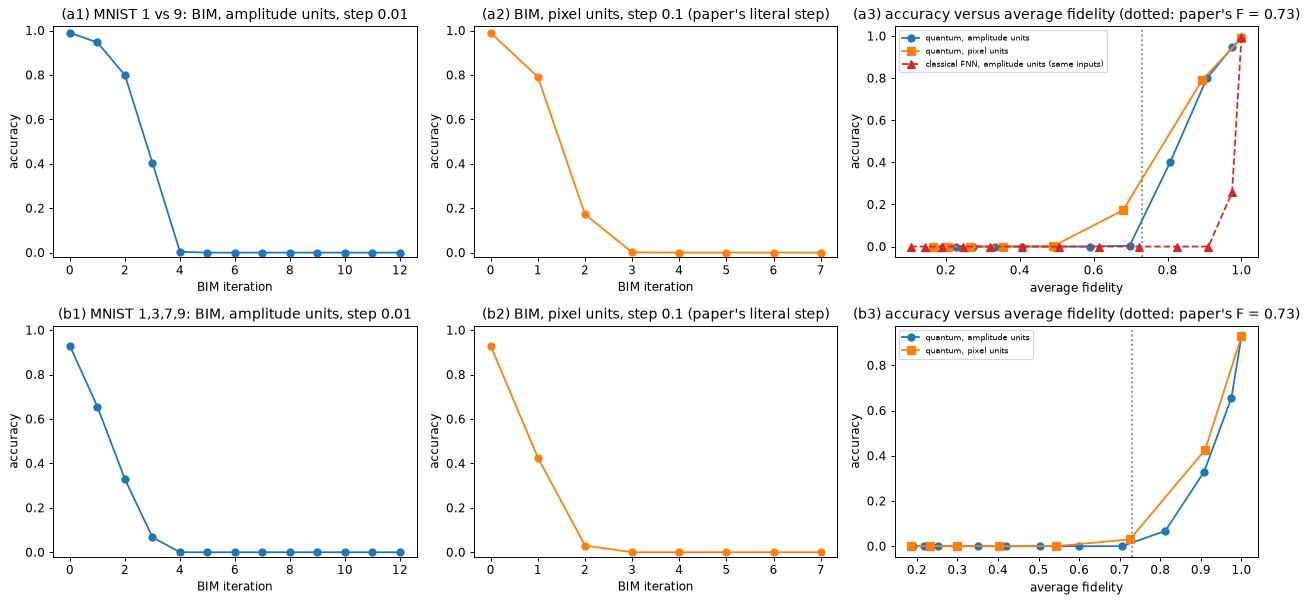

bin amp: accuracy 0.990 -> 0.000; first iteration with accuracy 0: 5, average fidelity there 0.589
bin pix: accuracy 0.990 -> 0.000; first iteration with accuracy 0: 4, average fidelity there 0.356
c4 amp: accuracy 0.929 -> 0.000; first iteration with accuracy 0: 4, average fidelity there 0.705
c4 pix: accuracy 0.929 -> 0.000; first iteration with accuracy 0: 3, average fidelity there 0.543


,task,correctly_classified,flipped,success_rate,median_F_at_flip,mean_F_at_flip,share_with_F_above_0_73
0,MNIST 1 vs 9,397,397,1.0,0.825,0.817,0.922
1,"MNIST 1,3,7,9",373,373,1.0,0.938,0.910,1.000
2,topological phases,381,381,1.0,0.969,0.956,1.000
3,Ising ground states,378,378,1.0,0.675,0.728,0.418


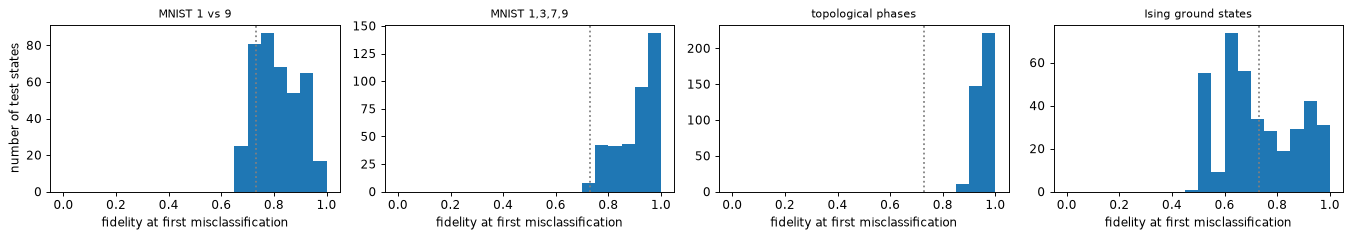

In [18]:
# ============ Fig. 7: accuracy versus BIM iteration and versus average fidelity (untargeted additive attack) ============
ALPHA_AMP, T_AMP = 0.01, 12            # CHOICE: BIM step in AMPLITUDE units (the paper's 0.1 is in unknown units); the PIXEL-unit curve uses the paper's literal 0.1
ALPHA_PIX, T_PIX = 0.1, 7

def curve(prob_fn, v0, y, steps, alpha, space):
    traj = iterative_sign_attack(prob_fn, v0, y, steps, alpha, space)
    out = [summarise(prob_fn, v0, v, y) for v in traj]
    return pd.DataFrame(out).assign(iteration=range(len(out)))

CURVES = {}
fig, ax = plt.subplots(2, 3, figsize=(15, 7.2))
for r, key in enumerate(["bin", "c4"]):
    qc = QM[key]; X, y = sub(key); pf = qc.probs
    va, vp = amp_normalise(X), X
    ca = curve(pf, va, y, T_AMP, ALPHA_AMP, "amp"); cp = curve(pf, vp, y, T_PIX, ALPHA_PIX, "pix")
    CURVES[key] = dict(amp=ca, pix=cp)
    ax[r, 0].plot(ca.iteration, ca.acc, "o-"); ax[r, 0].set_title(f"({'ab'[r]}1) {SPEC[key][0].split(' (')[0]}: BIM, amplitude units, step {ALPHA_AMP}")
    ax[r, 1].plot(cp.iteration, cp.acc, "o-", color="C1"); ax[r, 1].set_title(f"({'ab'[r]}2) BIM, pixel units, step {ALPHA_PIX} (paper's literal step)")
    for a in ax[r, :2]: a.set_xlabel("BIM iteration"); a.set_ylabel("accuracy"); a.set_ylim(-0.02, 1.02)
    ax[r, 2].plot(ca.fid, ca.acc, "o-", label="quantum, amplitude units"); ax[r, 2].plot(cp.fid, cp.acc, "s-", color="C1", label="quantum, pixel units")
    if key == "bin":                                                     # the classical FNN on the SAME inputs under the SAME attack
        fnn = FNNS["bin"]; cf = curve(fnn.probs, va, y, T_AMP, ALPHA_AMP, "amp")
        ax[r, 2].plot(cf.fid, cf.acc, "^--", color="C3", label="classical FNN, amplitude units (same inputs)"); CURVES[key]["fnn"] = cf
    ax[r, 2].axvline(PAPER["fig7_zero_acc_fidelity_min"], ls=":", color="gray"); ax[r, 2].set_xlabel("average fidelity"); ax[r, 2].set_ylabel("accuracy")
    ax[r, 2].set_title(f"({'ab'[r]}3) accuracy versus average fidelity (dotted: paper's F = 0.73)"); ax[r, 2].legend(fontsize=7)
plt.tight_layout(); plt.show()
for key in ["bin", "c4"]:
    for sp in ["amp", "pix"]:
        c = CURVES[key][sp]; z = c[c.acc <= 1e-9]
        print(f"{key} {sp}: accuracy {c.acc.iloc[0]:.3f} -> {c.acc.iloc[-1]:.3f}; first iteration with accuracy 0: "
              f"{int(z.iteration.iloc[0]) if len(z) else 'never'}" + (f", average fidelity there {z.fid.iloc[0]:.3f}" if len(z) else f", fidelity at the end {c.fid.iloc[-1]:.3f}"))

# ============ unit-free vulnerability: fidelity at which each test state is first misclassified ============
# BIM with a small step until the label flips (at most MAXIT steps); the fidelity of that first wrong state measures "how far a state must move".
def flip_stats(prob_fn, v0, y, alpha, maxit, space="amp"):
    traj = iterative_sign_attack(prob_fn, v0, y, maxit, alpha, space)
    wrong = torch.stack([predict_fn(prob_fn, v) != y for v in traj])            # [maxit+1, B]
    first = torch.where(wrong.any(0), wrong.float().argmax(0), torch.full((len(y),), -1))
    f_all = torch.stack([fidelity_vec(v0, v) for v in traj])                    # [maxit+1, B]
    f_flip = torch.where(first >= 0, f_all.gather(0, first.clamp(min=0)[None])[0], torch.full((len(y),), float("nan")))
    return first, f_flip

FLIP_ALPHA, FLIP_MAXIT, FLIP_N = 0.004, 25 if FAST_MODE else 60, 100 if FAST_MODE else 400
rows, FLIPF = [], {}
for key in ["bin", "c4", "qah", "ising"]:
    qc = QM[key]; X, y = sub(key, FLIP_N); v0 = amp_normalise(X)
    clean_ok = qc.predict(X) == y                                              # only samples that are correct at the start can be "flipped"
    first, ff = flip_stats(qc.probs, v0, y, FLIP_ALPHA, FLIP_MAXIT)
    ok = clean_ok & (first >= 1)
    f = ff[ok].numpy()
    FLIPF[key] = f
    rows.append(dict(task=SPEC[key][0].split(" (")[0], correctly_classified=int(clean_ok.sum()), flipped=int(ok.sum()),
                     success_rate=float(ok.sum() / max(1, clean_ok.sum())), median_F_at_flip=float(np.median(f)) if len(f) else np.nan,
                     mean_F_at_flip=float(f.mean()) if len(f) else np.nan, share_with_F_above_0_73=float((f > 0.73).mean()) if len(f) else np.nan))
FLIP_TABLE = pd.DataFrame(rows)
display(FLIP_TABLE.round(3))
R["flip"] = FLIP_TABLE
fig, ax = plt.subplots(1, 4, figsize=(16, 2.9))
for a, key in zip(ax, ["bin", "c4", "qah", "ising"]):
    a.hist(FLIPF[key], bins=20, range=(0, 1), color="C0"); a.axvline(0.73, ls=":", color="gray"); a.set_xlabel("fidelity at first misclassification"); a.set_title(SPEC[key][0].split(" (")[0], fontsize=9)
ax[0].set_ylabel("number of test states")
plt.tight_layout(); plt.show()


### 4.3 Functional attacks (Fig. 8) and targeted attacks (Fig. 9, 10, Table II)

**Functional attack.** Instead of changing every amplitude, the attacker applies a layer of local unitaries (Euler rotations on every data qubit, 24 angles) in front of the classifier and searches for the angles that maximise the loss (BIM with step 0.1 rad, or FGSM with one
step). The search space is much smaller; the circuit that is executed is architecture D in the circuit section.

**Targeted attack.** The attacker wants the classifier to answer a *chosen* wrong digit. For every target digit all images of the other digits are attacked by descending the loss of the target (Eq. 5). Fig. 9 shows clean and attacked states
(the amplitude vector reshaped to 16 x 16); Fig. 10(a-d) follows the probabilities and losses of one digit-1 image attacked towards the digit 3 (additively and with the functional attack); Fig. 10(e,f) plots accuracy against average fidelity for every target; Table II
compares the average accuracy over the four targets.

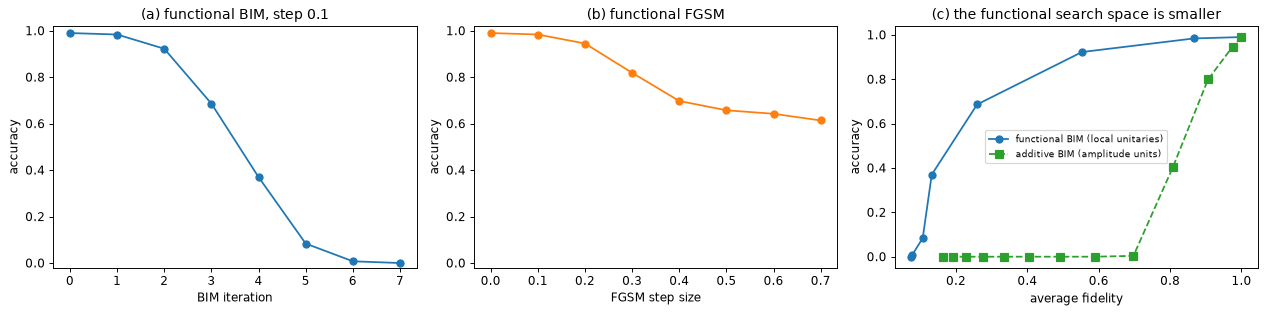

  acc   fid  iteration
0.990 1.000          0
0.984 0.866          1
0.923 0.553          2
0.686 0.259          3
0.370 0.132          4
0.084 0.107          5
0.007 0.077          6
0.000 0.075          7


,attack,how,eps,acc target 1,acc target 3,acc target 7,acc target 9,mean_acc,mean_F,mean_target_success,paper_acc,paper_mean_F
0,"BIM(3,0.05)",literal (amplitude units),0.050,0.000,0.000,0.000,0.000,0.000,0.606,1.000,"[0.057, 0.066, 0.027, 0.0]",0.938
1,"BIM(3,0.05)",iso-fidelity (eps calibrated to the paper's F),0.016,0.703,0.600,0.569,0.636,0.627,0.940,0.358,"[0.057, 0.066, 0.027, 0.0]",0.938
2,"FGSM(1,0.03)",literal (amplitude units),0.030,0.134,0.124,0.266,0.231,0.189,0.812,0.810,"[0.021, 0.109, 0.157, 0.119]",0.901
3,"FGSM(1,0.03)",iso-fidelity (eps calibrated to the paper's F),0.021,0.536,0.406,0.485,0.492,0.480,0.896,0.514,"[0.021, 0.109, 0.157, 0.119]",0.901


In [19]:
# ============ Fig. 8: FUNCTIONAL attack = one layer of local unitaries (Euler rotations on every data qubit) in front of the classifier ============
qc = QM["bin"]; X, y = sub("bin"); psi0 = amp_normalise(X)
sts = functional_attack(qc, X, y, F_T, F_STEP)
fb = pd.DataFrame([summarise_states(qc, psi0, s, y) for s in sts]).assign(iteration=range(F_T + 1))
eps_list = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
fg = pd.DataFrame([summarise_states(qc, psi0, functional_attack(qc, X, y, 1, e)[-1], y) if e > 0 else summarise_states(qc, psi0, psi0.to(CDT), y) for e in eps_list]).assign(step=eps_list)
FUNC = dict(bim=fb, fgsm=fg)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(fb.iteration, fb.acc, "o-"); ax[0].set_xlabel("BIM iteration"); ax[0].set_ylabel("accuracy"); ax[0].set_title("(a) functional BIM, step 0.1"); ax[0].set_ylim(-0.02, 1.02)
ax[1].plot(fg.step, fg.acc, "o-", color="C1"); ax[1].set_xlabel("FGSM step size"); ax[1].set_ylabel("accuracy"); ax[1].set_title("(b) functional FGSM"); ax[1].set_ylim(-0.02, 1.02)
ax[2].plot(fb.fid, fb.acc, "o-", label="functional BIM (local unitaries)"); ax[2].plot(CURVES["bin"]["amp"].fid, CURVES["bin"]["amp"].acc, "s--", color="C2", label="additive BIM (amplitude units)")
ax[2].set_xlabel("average fidelity"); ax[2].set_ylabel("accuracy"); ax[2].set_title("(c) the functional search space is smaller"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(fb.round(3).to_string(index=False))
R["func"] = FUNC

# ============ targeted white-box attacks on the 4-category classifier: Fig. 9, Fig. 10, Table II ============
qc = QM["c4"]; X4, y4 = sub("c4"); pf = qc.probs; DIG = [1, 3, 7, 9]
X4v, y4v = subval("c4", 400)                                        # validation samples: used only to calibrate budgets
def targeted_all(steps, eps, space="amp", n=None, alpha=None, validation=False):
    """Attack every sample towards every target label l != its own label; returns {l: (v0, v_adv, y, target)} (samples with y == l are excluded).
    validation=True uses validation samples (budget calibration), otherwise the attacked test samples."""
    out = {}
    XX, yy = (X4v, y4v) if validation else (X4, y4)
    for l in range(4):
        m = (yy != l)
        Xl, yl = XX[m][:n] if n else XX[m], yy[m][:n] if n else yy[m]
        tl = torch.full_like(yl, l)
        v0 = amp_normalise(Xl) if space == "amp" else Xl
        a = (eps / steps) if alpha is None else alpha
        v = iterative_sign_attack(pf, v0, yl, steps, a, space, target=tl, return_traj=False)
        out[l] = (v0, v, yl, tl)
    return out

def table2_rows(res, how, name, eps):
    acc, fid, suc = [], [], []
    for l in range(4):
        v0, v, yl, tl = res[l]; s = summarise(pf, v0, v, yl, tl); acc.append(s["acc"]); fid.append(s["fid"]); suc.append(s["success"])
    return dict(attack=name, how=how, eps=eps, **{f"acc target {DIG[l]}": acc[l] for l in range(4)}, mean_acc=float(np.mean(acc)), mean_F=float(np.mean(fid)),
                mean_target_success=float(np.mean(suc)), paper_acc=PAPER["table2"][name]["acc"], paper_mean_F=float(np.mean(PAPER["table2"][name]["fid"]))), acc, fid

rows = []
NCT = 80
for name, steps, eps in [("BIM(3,0.05)", 3, 0.05), ("FGSM(1,0.03)", 1, 0.03)]:
    row, a_, f_ = table2_rows(targeted_all(steps, eps), "literal (amplitude units)", name, eps); rows.append(row)
    pF = float(np.mean(PAPER["table2"][name]["fid"]))
    def make(e):                                                   # mean fidelity over the four targets on a small VALIDATION subset
        r = targeted_all(steps, e, n=NCT, validation=True)
        return torch.cat([fidelity_vec(r[l][0], r[l][1]) for l in range(4)])
    lo, hi = 1e-4, 1.0
    for _ in range(7):
        mid = math.sqrt(lo * hi); f = float(make(mid).mean()); lo, hi = (mid, hi) if f > pF else (lo, mid)
    e_cal = math.sqrt(lo * hi)
    row, a_, f_ = table2_rows(targeted_all(steps, e_cal), "iso-fidelity (eps calibrated to the paper's F)", name, e_cal); rows.append(row)
    R[f"t2_cal_{name}"] = dict(eps=e_cal)
TABLE_II = pd.DataFrame(rows)
display(TABLE_II.round(3)); R["table2"] = TABLE_II


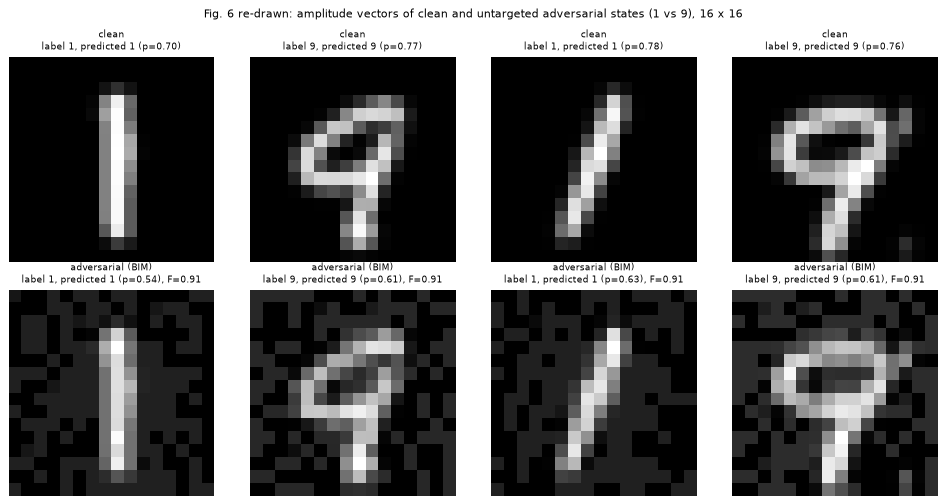

BIM(3, 0.0189) has average fidelity ~0.916 on the validation samples. Confidence of the correctly classified clean test states: mean 0.72, share above 0.78: 0.13  (paper: the displayed clean images are classified with confidence > 78%, adversarial ones with 73%)


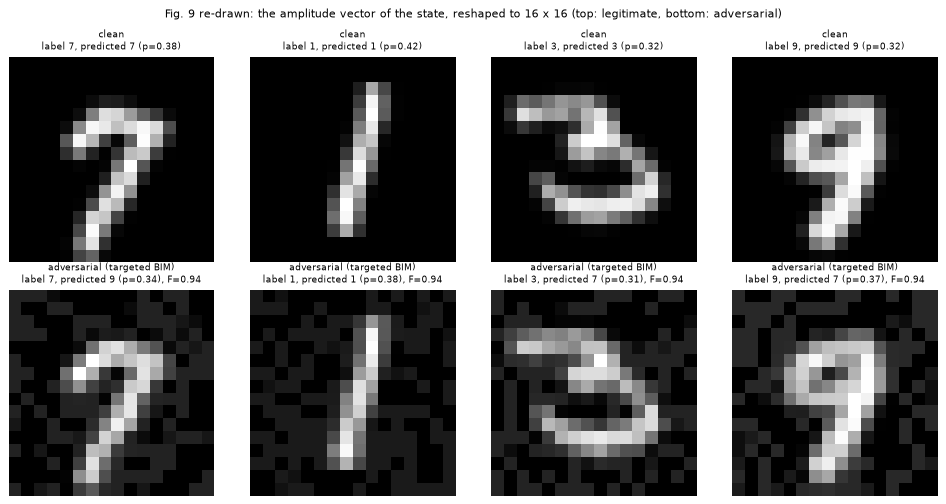

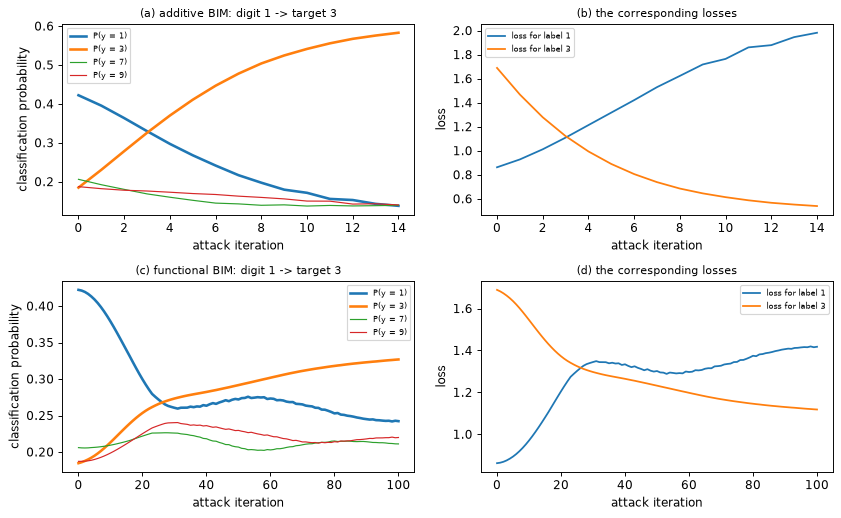

additive: P(1) 0.42 -> 0.14, P(3) 0.18 -> 0.58; P(3) > P(1) from iteration 4  (paper: P(1) ~ 0.41 at the start, P(3) > P(1) after about 6 iterations)


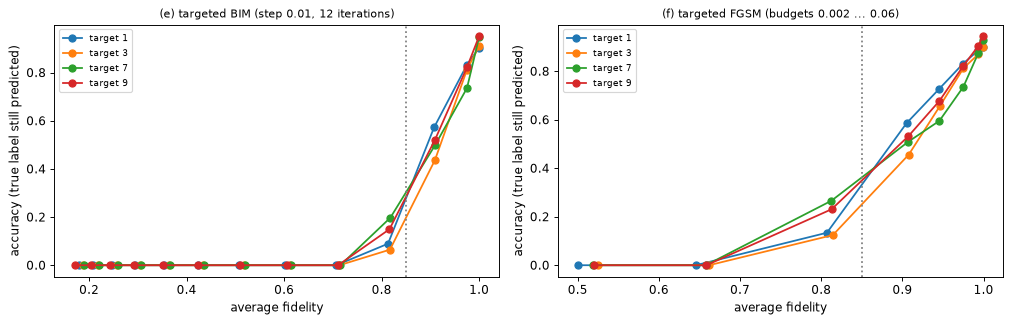

average fidelity at the first BIM iteration with accuracy 0, per target: {1: 0.707, 3: 0.713, 7: 0.715, 9: 0.711}  (paper: accuracy reaches 0 while F stays > 0.85)


In [20]:
# ============ Fig. 6: clean and untargeted adversarial images of the 2-category classifier (BIM(3), amplitude budget calibrated to the paper's average fidelity 0.916) ============
qb = QM["bin"]; Xb, yb = sub("bin"); pfb = qb.probs
Xvb, yvb = subval("bin", NC); v0c = amp_normalise(Xvb)
e6 = calib_eps(lambda e: bim(pfb, v0c, yvb, 3, e, "amp"), v0c, PAPER["fig6_fidelity"])
with torch.no_grad():
    pr_b = pfb(amp_normalise(Xb)); conf_b = pr_b.max(1).values; ok_b = pr_b.argmax(1) == yb
fig, ax = plt.subplots(2, 4, figsize=(11.5, 6))
for j, cls in enumerate([0, 1, 0, 1]):                                # two images of the digit 1 and two of the digit 9 (the first correctly classified ones)
    i = [int(t) for t in torch.where((yb == cls) & ok_b)[0]][j // 2]
    v0 = amp_normalise(Xb[i:i + 1]); va = bim(pfb, v0, yb[i:i + 1], 3, e6, "amp")
    with torch.no_grad():
        p0, p1 = pfb(v0)[0], pfb(va)[0]
    for r_, (vv, pp, ttl) in enumerate([(v0, p0, "clean"), (va, p1, "adversarial (BIM)")]):
        ax[r_, j].imshow(vv[0].numpy().reshape(IMG, IMG), cmap="gray"); ax[r_, j].axis("off")
        extra = f", F={float(fidelity_vec(v0, va)):.2f}" if r_ == 1 else ""
        ax[r_, j].set_title(f"{ttl}\nlabel {(1, 9)[cls]}, predicted {(1, 9)[int(pp.argmax())]} (p={float(pp.max()):.2f}){extra}", fontsize=8)
plt.suptitle("Fig. 6 re-drawn: amplitude vectors of clean and untargeted adversarial states (1 vs 9), 16 x 16", fontsize=9)
plt.tight_layout(); plt.show()
R["fig6"] = dict(eps=e6, conf_mean=float(conf_b[ok_b].mean()), conf_share=float((conf_b[ok_b] > 0.78).float().mean()))
print(f"BIM(3, {e6:.4f}) has average fidelity ~{PAPER['fig6_fidelity']} on the validation samples. Confidence of the correctly classified clean test states: mean {R['fig6']['conf_mean']:.2f}, "
      f"share above 0.78: {R['fig6']['conf_share']:.2f}  (paper: the displayed clean images are classified with confidence > 78%, adversarial ones with 73%)")

# ============ Fig. 9: clean vs targeted adversarial states (digits 7,1,3,9 pushed to the targets 9,3,7,7, as in the paper) ============
e_cal = R["t2_cal_BIM(3,0.05)"]["eps"]
fig, ax = plt.subplots(2, 4, figsize=(11.5, 6))
pairs = [(7, 9), (1, 3), (3, 7), (9, 7)]
for j, (src, tgt) in enumerate(pairs):
    cands = torch.where(torch.as_tensor(C4["te"]["digit"][:len(y4)]) == src)[0]
    cands = [int(i) for i in cands if int(qc.predict(X4[i:i + 1])) == DIG.index(src)]          # a correctly classified image of the source digit
    i = cands[0]
    v0 = amp_normalise(X4[i:i + 1]); yt = torch.tensor([DIG.index(tgt)])
    va = iterative_sign_attack(pf, v0, torch.tensor([DIG.index(src)]), 3, e_cal / 3, "amp", target=yt, return_traj=False)
    with torch.no_grad():
        p0, p1 = pf(v0)[0], pf(va)[0]
    for r_, (vv, pp, ttl) in enumerate([(v0, p0, "clean"), (va, p1, "adversarial (targeted BIM)")]):
        ax[r_, j].imshow(vv[0].numpy().reshape(IMG, IMG), cmap="gray"); ax[r_, j].axis("off")
        extra = f", F={float(fidelity_vec(v0, va)):.2f}" if r_ == 1 else ""
        ax[r_, j].set_title(f"{ttl}\nlabel {src}, predicted {DIG[int(pp.argmax())]} (p={float(pp.max()):.2f}){extra}", fontsize=8)
plt.suptitle("Fig. 9 re-drawn: the amplitude vector of the state, reshaped to 16 x 16 (top: legitimate, bottom: adversarial)", fontsize=9)
plt.tight_layout(); plt.show()

# ============ Fig. 10(a-d): one digit-1 image attacked towards the digit 3: probabilities and losses along the attack ============
i1 = [int(i) for i in torch.where(y4 == 0)[0] if int(qc.predict(X4[i:i + 1])) == 0][0]
v0 = amp_normalise(X4[i1:i1 + 1]); y1 = torch.tensor([0]); t3 = torch.tensor([1])
tr = iterative_sign_attack(pf, v0, y1, 14, 0.01, "amp", target=t3)
P_add = torch.cat([pf(v).detach() for v in tr]).numpy()
sts = functional_attack(qc, X4[i1:i1 + 1], y1, 100, 0.01, target=t3)
P_fun = torch.cat([qc.probs_psi(s).detach() for s in sts]).numpy()
fig, ax = plt.subplots(2, 2, figsize=(10, 6.2))
for (a_p, a_l, P, ttl, xl) in [(ax[0, 0], ax[0, 1], P_add, "additive BIM", "attack iteration"), (ax[1, 0], ax[1, 1], P_fun, "functional BIM", "attack iteration")]:
    for k in range(4):
        a_p.plot(P[:, k], label=f"P(y = {DIG[k]})", lw=2.2 if k in (0, 1) else 1)
    a_p.set_xlabel(xl); a_p.set_ylabel("classification probability"); a_p.set_title(f"({'a' if ttl.startswith('add') else 'c'}) {ttl}: digit 1 -> target 3", fontsize=9); a_p.legend(fontsize=7)
    a_l.plot(-np.log(P[:, 0] + 1e-7), label="loss for label 1"); a_l.plot(-np.log(P[:, 1] + 1e-7), label="loss for label 3"); a_l.set_xlabel(xl); a_l.set_ylabel("loss")
    a_l.set_title(f"({'b' if ttl.startswith('add') else 'd'}) the corresponding losses", fontsize=9); a_l.legend(fontsize=7)
plt.tight_layout(); plt.show()
cross = int(np.argmax(P_add[:, 1] > P_add[:, 0])) if (P_add[:, 1] > P_add[:, 0]).any() else None
print(f"additive: P(1) {P_add[0,0]:.2f} -> {P_add[-1,0]:.2f}, P(3) {P_add[0,1]:.2f} -> {P_add[-1,1]:.2f}; P(3) > P(1) from iteration {cross}  (paper: P(1) ~ 0.41 at the start, P(3) > P(1) after about 6 iterations)")

# ============ Fig. 10(e,f): accuracy versus average fidelity for each target label (additive attacks, BIM iterations and FGSM budgets) ============
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
T10 = {}
for l in range(4):
    m = (y4 != l); Xl, yl = X4[m], y4[m]; tl = torch.full_like(yl, l); v0 = amp_normalise(Xl)
    trj = iterative_sign_attack(pf, v0, yl, 12, 0.01, "amp", target=tl)
    cb = pd.DataFrame([summarise(pf, v0, v, yl, tl) for v in trj])
    cf = pd.DataFrame([summarise(pf, v0, fgsm(pf, v0, yl, e, "amp", target=tl), yl, tl) for e in [0.002, 0.005, 0.01, 0.015, 0.02, 0.03, 0.045, 0.06]])
    T10[l] = (cb, cf)
    ax[0].plot(cb.fid, cb.acc, "o-", label=f"target {DIG[l]}"); ax[1].plot(cf.fid, cf.acc, "o-", label=f"target {DIG[l]}")
for a, ttl in zip(ax, ["(e) targeted BIM (step 0.01, 12 iterations)", "(f) targeted FGSM (budgets 0.002 ... 0.06)"]):
    a.set_xlabel("average fidelity"); a.set_ylabel("accuracy (true label still predicted)"); a.set_title(ttl, fontsize=9); a.axvline(0.85, ls=":", color="gray"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
fz = {DIG[l]: float(T10[l][0][T10[l][0].acc <= 1e-9].fid.iloc[0]) if (T10[l][0].acc <= 1e-9).any() else float("nan") for l in range(4)}
print("average fidelity at the first BIM iteration with accuracy 0, per target:", {k: round(v, 3) for k, v in fz.items()}, " (paper: accuracy reaches 0 while F stays > 0.85)")
R["fig10_fz"] = fz


### 4.4 Phases of matter: topological images (Fig. 12, 13, Table IV) and Ising ground states (Fig. 15)

The same additive white-box attacks on the topological classifier (steps of 0.01 as in Fig. 12(b); Table IV: BIM(3, 0.01) and FGSM(1, 0.03)) and on the Ising ground-state classifier (BIM with step 0.05 and ten iterations, FGSM with budgets 0.1 ... 1.0, Fig. 15). The Ising panel (c) repeats the
attack with a much smaller step so that the interesting range of fidelities becomes visible, and shows the classical FNN under the same attack.

,attack,how,eps,fidelity,accuracy,paper_fidelity,paper_accuracy
0,"BIM(3,0.01)",literal (amplitude units),0.010,0.953,0.185,0.988,0.316
1,"BIM(3,0.01)",iso-fidelity (eps calibrated to the paper's F),0.005,0.988,0.744,0.988,0.316
2,"FGSM(1,0.03)",literal (amplitude units),0.030,0.690,0.000,0.952,0.063
3,"FGSM(1,0.03)",iso-fidelity (eps calibrated to the paper's F),0.010,0.953,0.206,0.952,0.063


Fig. 12(b): accuracy after 0 / 3 / 6 BIM iterations (step 0.01): 0.954 / 0.000 / 0.000   (paper: below 0.4 after about six iterations)


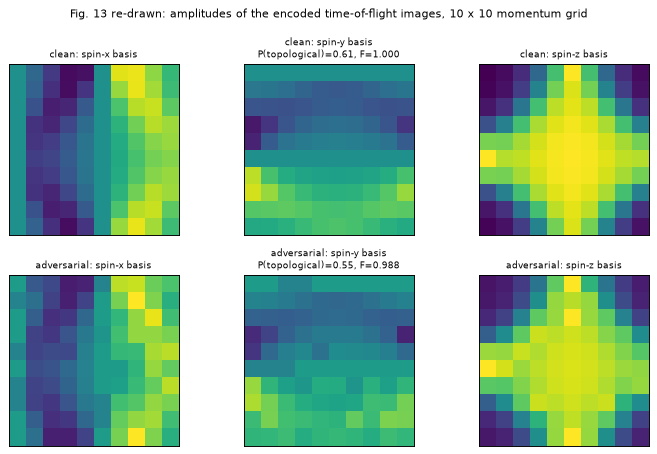

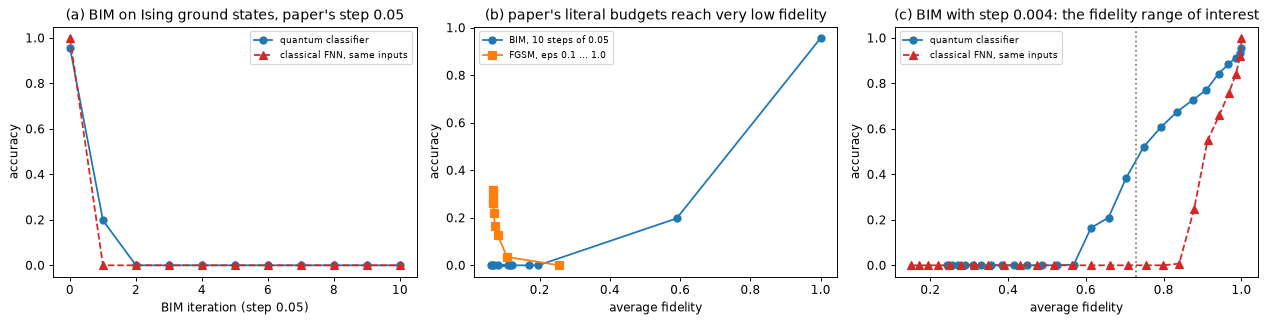

Ising, paper's step 0.05: accuracy 0 first at iteration 2 with average fidelity 0.196; step 0.004: accuracy 0 first at iteration 14 with average fidelity 0.526


In [21]:
# ============ topological phases (QAH time-of-flight images): Fig. 12(b), Fig. 13, Table IV ============
qc = QM["qah"]; Xq, yq = sub("qah"); pf = qc.probs
v0 = amp_normalise(Xq)
cq = curve(pf, v0, yq, 12, 0.01, "amp")                       # CHOICE: step 0.01 as in Fig. 12(b), in amplitude units
rows = []
for name, steps, eps in [("BIM(3,0.01)", 3, 0.01), ("FGSM(1,0.03)", 1, 0.03)]:
    pF, pA = PAPER["table4"][name]
    adv = bim(pf, v0, yq, steps, eps, "amp") if steps > 1 else fgsm(pf, v0, yq, eps, "amp")
    s = summarise(pf, v0, adv, yq)
    rows.append(dict(attack=name, how="literal (amplitude units)", eps=eps, fidelity=s["fid"], accuracy=s["acc"], paper_fidelity=pF, paper_accuracy=pA))
    Xvq, yc = subval("qah", NC); vc = amp_normalise(Xvq)                    # calibrate on validation samples
    make = (lambda e, steps=steps: bim(pf, vc, yc, steps, e, "amp")) if steps > 1 else (lambda e: fgsm(pf, vc, yc, e, "amp"))
    e_c = calib_eps(make, vc, pF)
    adv = bim(pf, v0, yq, steps, e_c, "amp") if steps > 1 else fgsm(pf, v0, yq, e_c, "amp")
    s = summarise(pf, v0, adv, yq)
    rows.append(dict(attack=name, how="iso-fidelity (eps calibrated to the paper's F)", eps=e_c, fidelity=s["fid"], accuracy=s["acc"], paper_fidelity=pF, paper_accuracy=pA))
TABLE_IV = pd.DataFrame(rows); display(TABLE_IV.round(3)); R["table4"] = TABLE_IV; R["qah_curve"] = cq
print(f"Fig. 12(b): accuracy after 0 / 3 / 6 BIM iterations (step 0.01): {cq.acc[0]:.3f} / {cq.acc[3]:.3f} / {cq.acc[6]:.3f}   (paper: below 0.4 after about six iterations)")

# Fig. 13: a clean time-of-flight image (three spin bases) and its adversarial counterpart, drawn as the first 300 amplitudes (3 x 10 x 10)
i = [int(j) for j in torch.where(yq == 1)[0] if int(qc.predict(Xq[j:j + 1])) == 1][0]
v_i = amp_normalise(Xq[i:i + 1]); e_c = float(TABLE_IV[(TABLE_IV.attack == "BIM(3,0.01)") & TABLE_IV.how.str.startswith("iso")].eps.iloc[0])
v_adv = bim(pf, v_i, yq[i:i + 1], 3, e_c, "amp")
fig, ax = plt.subplots(2, 3, figsize=(8.5, 5.4))
for r_, (vv, ttl) in enumerate([(v_i, "clean"), (v_adv, "adversarial")]):
    with torch.no_grad():
        pr = pf(vv)[0]
    for k, nm in enumerate(["spin-x basis", "spin-y basis", "spin-z basis"]):
        ax[r_, k].imshow(vv[0, 100 * k:100 * (k + 1)].numpy().reshape(L_K, L_K), cmap="viridis", vmin=0, vmax=float(v_i.max())); ax[r_, k].set_xticks([]); ax[r_, k].set_yticks([])
        ax[r_, k].set_title(f"{ttl}: {nm}" + (f"\nP(topological)={float(pr[1]):.2f}, F={float(fidelity_vec(v_i, vv)):.3f}" if k == 1 else ""), fontsize=8)
plt.suptitle("Fig. 13 re-drawn: amplitudes of the encoded time-of-flight images, 10 x 10 momentum grid", fontsize=9)
plt.tight_layout(); plt.show()

# ============ Ising ground states: Fig. 15 (additive attacks, L = 8) ============
qc = QM["ising"]; Xi, yi = sub("ising", min(N_ATTACK, len(ISING["te"]["y"]))); pf = qc.probs; v0 = amp_normalise(Xi)
ci = curve(pf, v0, yi, 10, 0.05, "amp")                                           # paper: step 0.05, ten iterations (amplitude units: the states are real unit vectors)
fnn_i = FNNS["ising"]; ci_fnn = curve(fnn_i.probs, v0, yi, 10, 0.05, "amp")
eps_f = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
cfg = pd.DataFrame([summarise(pf, v0, fgsm(pf, v0, yi, e, "amp"), yi) for e in eps_f]).assign(eps=eps_f)
# the same attacks with a step small enough to see the whole fidelity range (CHOICE, see the table of choices)
ci_s = curve(pf, v0, yi, 25, 0.004, "amp"); ci_s_fnn = curve(fnn_i.probs, v0, yi, 25, 0.004, "amp")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
ax[0].plot(ci.iteration, ci.acc, "o-", label="quantum classifier"); ax[0].plot(ci_fnn.iteration, ci_fnn.acc, "^--", color="C3", label="classical FNN, same inputs")
ax[0].set_xlabel("BIM iteration (step 0.05)"); ax[0].set_ylabel("accuracy"); ax[0].set_title("(a) BIM on Ising ground states, paper's step 0.05"); ax[0].legend(fontsize=8)
ax[1].plot(ci.fid, ci.acc, "o-", label="BIM, 10 steps of 0.05"); ax[1].plot(cfg.fid, cfg.acc, "s-", color="C1", label="FGSM, eps 0.1 ... 1.0")
ax[1].set_xlabel("average fidelity"); ax[1].set_ylabel("accuracy"); ax[1].set_title("(b) paper's literal budgets reach very low fidelity"); ax[1].legend(fontsize=8)
ax[2].plot(ci_s.fid, ci_s.acc, "o-", label="quantum classifier"); ax[2].plot(ci_s_fnn.fid, ci_s_fnn.acc, "^--", color="C3", label="classical FNN, same inputs"); ax[2].axvline(0.73, ls=":", color="gray")
ax[2].set_xlabel("average fidelity"); ax[2].set_ylabel("accuracy"); ax[2].set_title("(c) BIM with step 0.004: the fidelity range of interest"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
R["ising_curve"] = ci; R["ising_curve_small"] = ci_s
z = ci[ci.acc <= 1e-9]; zs = ci_s[ci_s.acc <= 1e-9]
print(f"Ising, paper's step 0.05: accuracy 0 first at iteration {int(z.iteration.iloc[0]) if len(z) else 'never'} with average fidelity {z.fid.iloc[0] if len(z) else float('nan'):.3f}; "
      f"step 0.004: accuracy 0 first at iteration {int(zs.iteration.iloc[0]) if len(zs) else 'never'} with average fidelity {zs.fid.iloc[0] if len(zs) else float('nan'):.3f}")


### 4.5 Random noise is not an adversarial perturbation (Fig. 11) and black-box transfer (Table III)

**Noise.** Depolarising noise with strength beta (Eq. 6) is applied to every data qubit of the input state, as random Pauli trajectories (a new random realisation for every state and repetition); accuracy and average fidelity are averaged.
Right-hand panels: the same average fidelity reached by an adversarial perturbation costs far more accuracy than random noise does.

**Black-box transfer.** An attacker without access to the quantum circuit trains a classical CNN or FNN on the same four digits (28 x 28 pixels), attacks *that* network with BIM(50, 0.01), FGSM(1, 0.3) and MIM(10, 0.06, decay 1) (l_inf ball of radius 0.3 around the image, pixels clipped to [0, 1]), and
feeds the adversarial images (bilinearly reduced to 16 x 16) to the quantum classifier. A control feeds images with random-sign noise of the same size 0.3, to separate "adversarial direction" from "big perturbation".

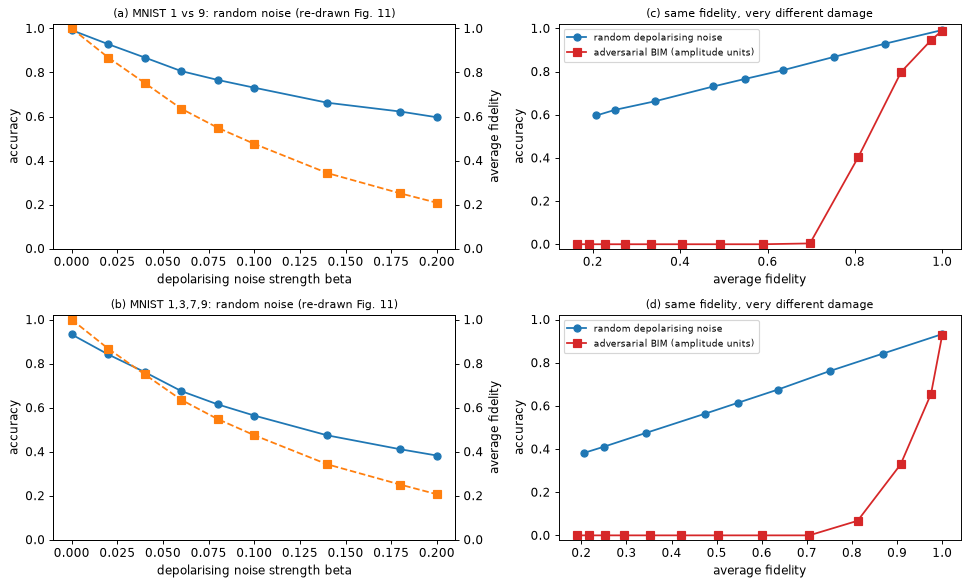

bin: accuracy 0.993 -> 0.597 at beta = 0.2 (average fidelity 0.208); linear fit R^2 = 0.959
c4: accuracy 0.933 -> 0.382 at beta = 0.2 (average fidelity 0.206); linear fit R^2 = 0.959


CNN: clean test accuracy 0.9878  (paper 0.989 / 0.999)   [245 s]


FNN: clean test accuracy 0.9809  (paper 0.989 / 0.999)   [256 s]


quantum 4-class classifier on the same images (torch resize): 0.9283   (PIL resize used for training/testing: 0.9287; paper 0.920)


,surrogate,attack,classical acc on adv,classical clean acc,quantum acc on adv,quantum clean acc,quantum drop,quantum acc under random noise (control),paper: classical acc on adv,paper: quantum acc on adv,paper: quantum drop
0,CNN,"BIM(50,0.01)",0.0,0.985,0.290,0.928,0.638,0.822,0.001,0.664,0.256
1,CNN,"FGSM(1,0.3)",0.0,0.985,0.240,0.928,0.688,0.822,0.006,0.516,0.404
2,CNN,"MIM(10,0.06)",0.0,0.985,0.257,0.928,0.672,0.822,0.007,0.623,0.297
3,FNN,"BIM(50,0.01)",0.0,0.977,0.275,0.928,0.653,0.822,0.006,0.681,0.239
4,FNN,"FGSM(1,0.3)",0.0,0.977,0.238,0.928,0.690,0.822,0.010,0.568,0.352
5,FNN,"MIM(10,0.06)",0.0,0.977,0.248,0.928,0.680,0.822,0.008,0.599,0.321


In [22]:
# ============ Fig. 11: random depolarising noise, Eq. (6), versus adversarial perturbations ============
N_NS = 120 if FAST_MODE else 400                         # test states per noise strength (CHOICE; the paper averages 1000 random realisations)
betas = [0, 0.02, 0.04, 0.06, 0.08, 0.10, 0.14, 0.18, 0.20]
NOISE = {}
fig, ax = plt.subplots(2, 2, figsize=(11.5, 7))
for r_, key in enumerate(["bin", "c4"]):
    qc = QM[key]; X, y = sub(key, N_NS); psi = amp_normalise(X); gen = torch.Generator().manual_seed(SEED + 7)
    accs, fids = [], []
    for b in betas:
        a_, f_ = [], []
        for rep in range(N_NOISE_REAL):
            noisy = depolarise(psi, b, qc.n, gen)
            with torch.no_grad():
                a_.append((qc.probs_psi(noisy).argmax(1) == y).float().mean()); f_.append(fid_states(psi, noisy).mean())
        accs.append(float(torch.stack(a_).mean())); fids.append(float(torch.stack(f_).mean()))
    NOISE[key] = pd.DataFrame(dict(beta=betas, acc=accs, fid=fids))
    a1 = ax[r_, 0]; a1.plot(betas, accs, "o-", label="accuracy"); a1.set_xlabel("depolarising noise strength beta"); a1.set_ylabel("accuracy"); a1.set_ylim(0, 1.02)
    a2 = a1.twinx(); a2.plot(betas, fids, "s--", color="C1", label="average fidelity"); a2.set_ylabel("average fidelity"); a2.set_ylim(0, 1.02)
    a1.set_title(f"({'ab'[r_]}) {SPEC[key][0].split(' (')[0]}: random noise (re-drawn Fig. 11)", fontsize=9)
    ax[r_, 1].plot(NOISE[key].fid, NOISE[key].acc, "o-", label="random depolarising noise"); ca = CURVES[key]["amp"]
    ax[r_, 1].plot(ca.fid, ca.acc, "s-", color="C3", label="adversarial BIM (amplitude units)"); ax[r_, 1].set_xlabel("average fidelity"); ax[r_, 1].set_ylabel("accuracy")
    ax[r_, 1].set_title(f"({'cd'[r_]}) same fidelity, very different damage", fontsize=9); ax[r_, 1].legend(fontsize=8); ax[r_, 1].set_ylim(-0.02, 1.02)
plt.tight_layout(); plt.show()
for key in ["bin", "c4"]:
    nz = NOISE[key]; lin = np.polyfit(nz.beta, nz.acc, 1); r2 = 1 - ((nz.acc - np.polyval(lin, nz.beta)) ** 2).sum() / ((nz.acc - nz.acc.mean()) ** 2).sum()
    print(f"{key}: accuracy {nz.acc.iloc[0]:.3f} -> {nz.acc.iloc[-1]:.3f} at beta = {nz.beta.iloc[-1]} (average fidelity {nz.fid.iloc[-1]:.3f}); linear fit R^2 = {r2:.3f}")
    R[f"noise_{key}"] = dict(r2=float(r2), acc_end=float(nz.acc.iloc[-1]), fid_end=float(nz.fid.iloc[-1]))

# ============ Table III: black-box transfer attack (adversarial examples crafted for classical CNN / FNN, evaluated on the quantum classifier) ============
class CNN(nn.Module):
    """Table V: Conv(64,8,8)+ReLU, Conv(128,4,4)+ReLU, Conv(128,2,2)+ReLU, Flatten, Dropout(0.5), FC(4)+softmax.
    CHOICE: (filters, kernel, kernel) read as filters, kernel size, with stride 2 and 'same' padding (as in the Cleverhans tutorial network): 28x28 -> 14x14 -> 7x7 -> 4x4."""
    def __init__(self, k=4):
        super().__init__()
        self.c1 = nn.Conv2d(1, 64, 8, stride=2, padding=3); self.c2 = nn.Conv2d(64, 128, 4, stride=2, padding=1); self.c3 = nn.Conv2d(128, 128, 2, stride=2, padding=1)
        self.drop = nn.Dropout(0.5); self.fc = nn.Linear(128 * 4 * 4, k)
    def forward(self, v):
        x = v.reshape(-1, 1, 28, 28)
        x = F.relu(self.c1(x)); x = F.relu(self.c2(x)); x = F.relu(self.c3(x))
        return self.fc(self.drop(x.flatten(1)))
    def probs(self, v):
        return F.softmax(self.forward(v), dim=1)

x28_tr = T(C4["tr"]["x28"][:N_CLASSICAL].reshape(-1, 784) / 255.0); y_tr = torch.as_tensor(C4["tr"]["y"][:N_CLASSICAL])
x28_te = T(C4["te"]["x28"].reshape(-1, 784) / 255.0); y_te = torch.as_tensor(C4["te"]["y"])
SURR = {}
t0 = time.time()
torch.manual_seed(SEED)
for nm, net in [("CNN", CNN(4)), ("FNN", FNN(784, 4))]:
    SURR[nm] = fit_torch_clf(net, x28_tr, y_tr, CLASSICAL_EPOCHS, lr=1e-3, batch=256)
    with torch.no_grad():
        print(f"{nm}: clean test accuracy {float((SURR[nm](x28_te).argmax(1) == y_te).float().mean()):.4f}  (paper 0.989 / 0.999)   [{time.time() - t0:.0f} s]")

def to16(v784):
    """784 pixel vector -> 256 pixel vector (bilinear with antialiasing, same recipe as the data preparation but on float images)."""
    return F.interpolate(v784.reshape(-1, 1, 28, 28), size=(IMG, IMG), mode="bilinear", antialias=True, align_corners=False).reshape(-1, IMG * IMG)

N3 = 100 if FAST_MODE else 600                                       # CHOICE: number of test images attacked (paper: whole test set)
xs, ys_ = x28_te[:N3], y_te[:N3]; qc = QM["c4"]
q_clean = float((qc.predict(to16(xs)) == ys_).float().mean())
print(f"quantum 4-class classifier on the same images (torch resize): {q_clean:.4f}   (PIL resize used for training/testing: {R['clean_c4']:.4f}; paper 0.920)")
ATT = {"BIM(50,0.01)": dict(steps=50, alpha=0.01), "FGSM(1,0.3)": dict(steps=1, alpha=0.3), "MIM(10,0.06)": dict(steps=10, alpha=0.06, momentum=1.0)}
rows = []
for nm in ["CNN", "FNN"]:
    net = SURR[nm]
    for an, kw in ATT.items():
        adv = iterative_sign_attack(net.probs, xs, ys_, kw["steps"], kw["alpha"], "pix", momentum=kw.get("momentum"), ball=0.3, return_traj=False)   # eps = 0.3 l_inf ball (Cleverhans default for MNIST)
        with torch.no_grad():
            ac = float((net(adv).argmax(1) == ys_).float().mean())
            clean_c = float((net(xs).argmax(1) == ys_).float().mean())
        aq = float((qc.predict(to16(adv)) == ys_).float().mean())
        # control: random-sign noise of the same l_inf size instead of the adversarial direction
        gen = torch.Generator().manual_seed(SEED)
        rnd = (xs + 0.3 * torch.sign(torch.rand(xs.shape, generator=gen) - 0.5)).clamp(0, 1)
        aq_r = float((qc.predict(to16(rnd)) == ys_).float().mean())
        pc, pq = PAPER["table3"][(nm, an)]
        rows.append({"surrogate": nm, "attack": an, "classical acc on adv": ac, "classical clean acc": clean_c, "quantum acc on adv": aq, "quantum clean acc": q_clean,
                     "quantum drop": q_clean - aq, "quantum acc under random noise (control)": aq_r, "paper: classical acc on adv": pc, "paper: quantum acc on adv": pq,
                     "paper: quantum drop": PAPER["table3_clean_q"] - pq})
TABLE_III = pd.DataFrame(rows); display(TABLE_III.round(3)); R["table3"] = TABLE_III


## 5. Defence: quantum adversarial training (Fig. 16) and adaptive attacks

**Adversarial training** solves the min-max problem of Eq. (10) with the three-step procedure of the paper: for every mini-batch (1) take the current parameters, (2) craft BIM(3, eps) adversarial states for the batch, (3) take one Adam step on the
legitimate and the crafted states together. Training starts from random parameters. The attack budget is chosen so that the undefended classifier is as badly hurt as in the paper's Table I (see the table of choices). A **control** is trained identically but
with *random-sign noise of the same size* instead of adversarial states, which tests the paper's remark that adversarial examples are a better augmentation than random noise. After every epoch the white-box BIM attack is rerun against the *current* parameters on held-out test states.

adversarial-training budget: BIM(3, 0.0339) in amplitude units (undefended accuracy ~15.6% as in the paper's Table I; average fidelity 0.765); the paper's literal 0.05 is 1.5x larger


  [adv] epoch   1/15  train loss 0.707 acc 0.490 | val loss 0.444 acc 0.965 |   29.5s


  [adv] epoch   3/15  train loss 0.599 acc 0.626 | val loss 0.405 acc 0.969 |   92.2s


  [adv] epoch   6/15  train loss 0.585 acc 0.654 | val loss 0.396 acc 0.970 |  187.7s


  [adv] epoch   9/15  train loss 0.580 acc 0.662 | val loss 0.394 acc 0.974 |  275.5s


...

  [noise] epoch   6/15  train loss 0.403 acc 0.982 | val loss 0.372 acc 0.973 |   74.5s


  [noise] epoch   9/15  train loss 0.397 acc 0.980 | val loss 0.368 acc 0.972 |  106.2s


  [noise] epoch  12/15  train loss 0.394 acc 0.981 | val loss 0.366 acc 0.966 |  139.1s


  [noise] epoch  15/15  train loss 0.389 acc 0.979 | val loss 0.361 acc 0.967 |  167.4s


   noise: final legitimate test acc 0.995, white-box BIM(3, 0.034) test acc 0.155, F 0.767  (602 s)


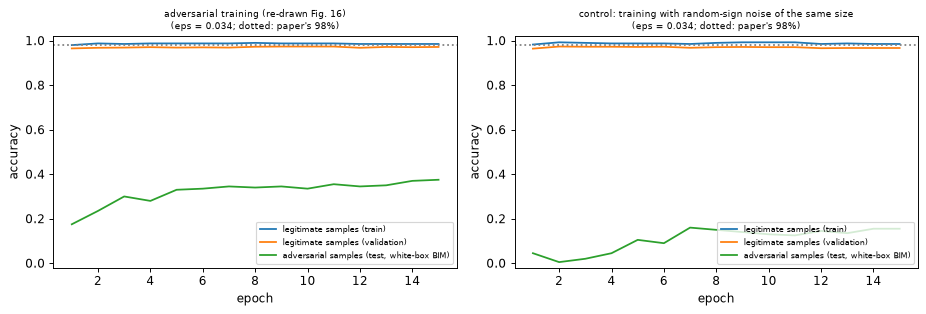

In [23]:
# ============ Fig. 16: quantum adversarial training  min_Theta  mean_i  max_{U_delta}  L(h(U_delta |psi_i>; Theta), y_i)  ============
# Every mini-batch: (1) take the current parameters, (2) craft BIM(3, eps) adversarial states for the batch (inner maximisation), (3) one Adam step on
# the legitimate AND the crafted states (outer minimisation).  Starting from random parameters, as in the paper.
# Budget: the paper's "BIM(3, 0.05)" cannot be mapped to amplitude units (see the table of choices; taken literally it gives F ~ 0.6 and a circuit of this size
# cannot become robust).  CHOICE: we use the amplitude-space budget at which the UNDEFENDED classifier is as badly hurt as in the paper's Table I
# (BIM(3, .) leaves 15.6% accuracy), i.e. an attack of the same effectiveness.
Xtr_a, ytr_a = BIN["tr"]["x"][:ADV_N_TRAIN], BIN["tr"]["y"][:ADV_N_TRAIN]
Xva_a, yva_a = BIN["va"]["x"], BIN["va"]["y"]
N_AT = min(N_ATTACK, 200)                                                         # adversarial test states per epoch (white-box BIM on the CURRENT parameters)
Xat, yat = sub("bin", N_AT)

def calib_eps_acc(qc, X, y, target_acc, lo=1e-3, hi=0.2, iters=9):
    v0 = amp_normalise(X)
    for _ in range(iters):
        mid = math.sqrt(lo * hi)
        a = float((predict_fn(qc.probs, bim(qc.probs, v0, y, 3, mid)) == y).float().mean())
        lo, hi = (mid, hi) if a > target_acc else (lo, mid)
    return math.sqrt(lo * hi)

EPS_LIT = 0.05
Xcal, ycal = subval("bin", 150)                                                   # the budget is calibrated on VALIDATION samples
EPS_ACC = calib_eps_acc(QM["bin"], Xcal, ycal, PAPER["table1"][("bin", "BIM(3,0.1)")][1])
Fa = float(fidelity_vec(amp_normalise(Xat), bim(QM["bin"].probs, amp_normalise(Xat), yat, 3, EPS_ACC)).mean())
print(f"adversarial-training budget: BIM(3, {EPS_ACC:.4f}) in amplitude units (undefended accuracy ~15.6% as in the paper's Table I; average fidelity {Fa:.3f}); the paper's literal 0.05 is {EPS_LIT / EPS_ACC:.1f}x larger")

def adv_transform(eps):
    def f(qc, v, y):
        v = amp_normalise(v)
        va = bim(qc.probs, v, y, 3, eps, "amp")
        return torch.cat([v, va]), torch.cat([y, y])
    return f

def noise_transform(eps, gen):
    def f(qc, v, y):
        v = amp_normalise(v)
        vn = amp_normalise(v + eps * torch.sign(torch.rand(v.shape, generator=gen) - 0.5))   # random-sign noise with the same l_inf size eps as the BIM(3, eps) attack
        return torch.cat([v, vn]), torch.cat([y, y])
    return f

def make_cb(eps):
    def cb(qc, ep):
        adv = bim(qc.probs, amp_normalise(Xat), yat, 3, eps, "amp")
        return dict(legit_train_acc=acc_of(qc, Xtr_a[:400], ytr_a[:400]), legit_test_acc=float((qc.predict(Xat) == yat).float().mean()),
                    adv_test_acc=float((qc.predict(adv) == yat).float().mean()), adv_test_fid=float(fidelity_vec(amp_normalise(Xat), adv).mean()))
    return cb

ADV = {}
t0 = time.time()
for tag, kind in [("adv", "adv"), ("noise", "noise")]:
    qa = QC(8, 1, P_DEPTH, SEED + 5)
    tf = adv_transform(EPS_ACC) if kind == "adv" else noise_transform(EPS_ACC, torch.Generator().manual_seed(SEED + 11))
    h = train_qc(qa, Xtr_a, ytr_a, Xva_a, yva_a, ADV_EPOCHS, BATCH["bin"] // 2, LR, SEED, batch_transform=tf, tag=tag, epoch_cb=make_cb(EPS_ACC))
    qa.theta.requires_grad_(False)
    ADV[tag] = dict(qc=qa, hist=h, eps=EPS_ACC, kind=kind)
    print(f"   {tag}: final legitimate test acc {h.legit_test_acc.iloc[-1]:.3f}, white-box BIM(3, {EPS_ACC:.3f}) test acc {h.adv_test_acc.iloc[-1]:.3f}, F {h.adv_test_fid.iloc[-1]:.3f}  ({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, tag, ttl in zip(ax, ["adv", "noise"], ["adversarial training (re-drawn Fig. 16)", "control: training with random-sign noise of the same size"]):
    h = ADV[tag]["hist"]
    a.plot(h.epoch, h.legit_train_acc, label="legitimate samples (train)"); a.plot(h.epoch, h.val_acc, label="legitimate samples (validation)"); a.plot(h.epoch, h.adv_test_acc, label="adversarial samples (test, white-box BIM)")
    a.axhline(PAPER["fig16_adv_train_acc"], ls=":", color="gray"); a.set_xlabel("epoch"); a.set_ylabel("accuracy"); a.set_ylim(-0.02, 1.02); a.set_title(f"{ttl}\n(eps = {EPS_ACC:.3f}; dotted: paper's 98%)", fontsize=8); a.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()


### Is the robustness real? Adaptive attacks

A defence can look good simply because the attack used to evaluate it no longer finds its gradient useful ("gradient masking"); the paper itself warns that adversarial training may be more robust to white-box than to black-box attacks for this reason.
The next cell attacks the undefended, the adversarially trained and the noise-trained classifier with the *same budget* by: one-step FGSM, the training attack BIM(3), MIM, PGD with random starts and restarts (worst case over the restarts), a **gradient-free** random search
that only queries the classifier, a **black-box transfer** attack crafted on the undefended model, and PGD with 3x and 10x the budget. The checklist of Athalye et al. / Carlini et al. is then evaluated automatically: iterative attacks must be at least as strong as one-step attacks,
white-box at least as strong as black-box, a large budget must reach 0 % accuracy, gradient-free attacks must not beat gradient-based ones, and more steps/restarts must not change the picture.

In [24]:
# ============ Adaptive attacks: is the robustness of the adversarially trained classifiers real, or is it gradient masking? ============
# Checklist (Athalye et al. 2018, Carlini et al. 2019): (1) iterative attacks must be at least as strong as one-step attacks, (2) white-box attacks must be at
# least as strong as black-box (transfer) attacks, (3) a large enough budget must reach 0% accuracy, (4) gradient-free attacks must not beat gradient-based
# ones, (5) more iterations / random restarts must not change the picture.  All attacks below use the SAME budget eps (l_inf size before re-normalisation).
N_MASK = 80 if FAST_MODE else 300
Xm, ym = sub("bin", N_MASK); vm = amp_normalise(Xm)

def square_like(prob_fn, v0, y, eps, iters, gen, p_flip=0.1):
    """Gradient-free l_inf attack (query access only): random-sign perturbation; flip random coordinates; keep the change when the loss on the true label grows."""
    delta = eps * torch.sign(torch.rand(v0.shape, generator=gen) - 0.5)
    best = amp_normalise(v0 + delta)
    with torch.no_grad():
        best_loss = ce_loss(prob_fn(best), y, "none")
        for _ in range(iters):
            cand_delta = torch.where(torch.rand(v0.shape, generator=gen) < p_flip, -delta, delta)
            cand = amp_normalise(v0 + cand_delta)
            l = ce_loss(prob_fn(cand), y, "none"); better = l > best_loss
            delta = torch.where(better[:, None], cand_delta, delta); best_loss = torch.where(better, l, best_loss); best = torch.where(better[:, None], cand, best)
    return best

def worst_case_acc(prob_fn, advs, y):
    """Accuracy when an attacked state counts as robust only if ALL attack variants fail on it."""
    ok = torch.stack([predict_fn(prob_fn, v) == y for v in advs]).all(0)
    return float(ok.float().mean())

def suite(model, eps, source=None, tag=""):
    """Accuracy of `model` (a QC) under a list of attacks of budget eps; `source` is the undefended QC used for the transfer attack."""
    pf = model.probs; gen = torch.Generator().manual_seed(SEED + 3)
    acc = lambda v: float((predict_fn(pf, v) == ym).float().mean())
    out = {"clean": acc(vm), "FGSM(1, eps)": acc(fgsm(pf, vm, ym, eps)), "BIM(3, eps)  [training attack]": acc(bim(pf, vm, ym, 3, eps))}
    out["MIM(10, eps)"] = acc(iterative_sign_attack(pf, vm, ym, 10, eps / 10, "amp", momentum=1.0, return_traj=False))
    pgd = [iterative_sign_attack(pf, vm, ym, 20, eps / 5, "amp", ball=eps, rand_start=True, gen=gen, return_traj=False) for _ in range(2)]
    out["PGD(20 steps, 2 random restarts, worst case)"] = worst_case_acc(pf, pgd, ym)
    out["gradient-free random search (200 queries)"] = acc(square_like(pf, vm, ym, eps, 200, gen))
    if source is not None:
        out["black-box transfer: BIM(3, eps) crafted on the undefended model"] = acc(bim(source.probs, vm, ym, 3, eps))
    out["PGD with 3 x eps"] = acc(iterative_sign_attack(pf, vm, ym, 20, 3 * eps / 5, "amp", ball=3 * eps, rand_start=True, gen=gen, return_traj=False))
    out["PGD with 10 x eps"] = acc(iterative_sign_attack(pf, vm, ym, 20, 10 * eps / 5, "amp", ball=10 * eps, rand_start=True, gen=gen, return_traj=False))
    return out

t0 = time.time()
cols = {}
base = QM["bin"]
cols["undefended"] = suite(base, EPS_ACC, None)
cols["adversarially trained"] = suite(ADV["adv"]["qc"], EPS_ACC, base)
cols["noise-trained (control)"] = suite(ADV["noise"]["qc"], EPS_ACC, base)
MASK = pd.DataFrame(cols)
display(MASK.round(3)); print(f"({time.time() - t0:.0f} s)")
R["mask"] = MASK

def flags(col):
    c = MASK[col]; f = {}
    f["(1) iterative at least as strong as one-step"] = c["BIM(3, eps)  [training attack]"] <= c["FGSM(1, eps)"] + 0.02
    if "black-box transfer: BIM(3, eps) crafted on the undefended model" in c.index and not np.isnan(c["black-box transfer: BIM(3, eps) crafted on the undefended model"]):
        f["(2) white-box at least as strong as black-box"] = c["PGD(20 steps, 2 random restarts, worst case)"] <= c["black-box transfer: BIM(3, eps) crafted on the undefended model"] + 0.02
    f["(3) 10 x eps reaches ~0% accuracy"] = c["PGD with 10 x eps"] <= 0.05
    f["(4) gradient-free not stronger than gradient-based"] = c["gradient-free random search (200 queries)"] >= c["PGD(20 steps, 2 random restarts, worst case)"] - 0.02
    f["(5) PGD (more steps + restarts) not far stronger than BIM(3)"] = c["PGD(20 steps, 2 random restarts, worst case)"] >= c["BIM(3, eps)  [training attack]"] - 0.10
    return f
for col in ["adversarially trained"]:
    fl = flags(col)
    print(f"\n{col}: " + ("all five checks pass: no sign of gradient masking, the BIM(3) numbers can be trusted" if all(fl.values()) else "at least one check FAILS: the evaluation with the training attack is not trustworthy (see below)"))
    for k, v in fl.items():
        print(f"   {'pass' if v else 'FAIL'}  {k}")
    R["mask_flags"] = fl


,undefended,adversarially trained,noise-trained (control)
clean,0.990,0.993,0.993
"FGSM(1, eps)",0.277,0.500,0.250
"BIM(3, eps) [training attack]",0.167,0.373,0.147
"MIM(10, eps)",0.170,0.380,0.153
"PGD(20 steps, 2 random restarts, worst case)",0.073,0.280,0.093
gradient-free random search (200 queries),0.887,0.893,0.883
PGD with 3 x eps,0.000,0.000,0.000
PGD with 10 x eps,0.000,0.000,0.000
"black-box transfer: BIM(3, eps) crafted on the undefended model",NaN,0.883,0.830


(94 s)

adversarially trained: all five checks pass: no sign of gradient masking, the BIM(3) numbers can be trusted
   pass  (1) iterative at least as strong as one-step
   pass  (2) white-box at least as strong as black-box
   pass  (3) 10 x eps reaches ~0% accuracy
   pass  (4) gradient-free not stronger than gradient-based
   pass  (5) PGD (more steps + restarts) not far stronger than BIM(3)


## 6. The paper's claims next to this notebook's numbers

Each claim gets one verdict: **reproduced** (within 2 accuracy points / 0.02, or the stated qualitative behaviour is observed), **not reached here** or **exceeded here** (outside the tolerance; for *attack* accuracies lower is stronger, so
"not reached here" means our attack leaves more accuracy than the paper's), or **cannot be checked** (no number in the paper, or specific images that cannot be recovered). Where the unit of a budget is ambiguous, the verdict is given on the
iso-fidelity comparison and the literal readings are listed in the "this notebook" column.

In [25]:
# ============ the paper's claims next to this notebook's numbers ============
# Verdicts: "reproduced" = within 2 accuracy points / 0.02 (or the stated qualitative behaviour is observed); "not reached here" / "exceeded here" = outside the
# tolerance (for ATTACK accuracies lower is stronger: "not reached here" means our attack leaves MORE accuracy than the paper's); "cannot be checked".
claims = []
def add(n, where, claim, paper, here, verdict):
    claims.append({"#": n, "where": where, "claim": claim, "paper": paper, "this notebook": here, "verdict": verdict})

def v_model(paper, here, tol=TOL_ACC):             # a model quality (accuracy): higher is better
    return "reproduced" if abs(here - paper) <= tol else ("exceeded here" if here > paper else "not reached here")
def v_attack(paper, here, tol=TOL_ACC):            # accuracy UNDER ATTACK: lower is a stronger attack
    return "reproduced" if abs(here - paper) <= tol else ("not reached here" if here > paper else "exceeded here")
def first_zero(c):
    z = c[c.acc <= 1e-9]
    return (int(z.iteration.iloc[0]), float(z.fid.iloc[0])) if len(z) else (None, float(c.fid.iloc[-1]))
n = 0
def nxt():
    global n; n += 1; return n

# ---- clean accuracies ----
for key, pa, where, note in [("bin", PAPER["acc_bin"], "Sec. III B, Fig. 4", ""), ("c4", PAPER["acc_c4"], "Sec. III B, Fig. 5", f" (paper depth 40, here depth {P_DEPTH_4C})"),
                              ("qah", PAPER["acc_qah"], "Sec. III C, Fig. 12(a)", ""), ("ising", PAPER["acc_ising"], "Sec. III D, Fig. 14", "")]:
    add(nxt(), where, f"test accuracy of the {SPEC[key][0].split(' (')[0]} classifier{note}", f"{pa:.3f}", f"{TEST_ACC[key]:.3f}", v_model(pa, TEST_ACC[key]))
# ---- Table I (iso-fidelity: the budget is calibrated so that the average fidelity equals the paper's) ----
T1 = R["table1"]
for _, r in T1[T1.how.str.startswith("iso")].iterrows():
    lit = T1[(T1.model == r.model) & (T1.attack == r.attack) & T1.how.str.startswith("literal")]
    lit_txt = "; literal parameters: " + ", ".join(f"{u} units F={f:.2f} acc={a:.3f}" for u, f, a in zip(lit.units, lit.fidelity, lit.accuracy))
    add(nxt(), "Table I", f"{r.model}, {r.attack}: accuracy at average fidelity {r.paper_fidelity:.3f}", f"{r.paper_accuracy:.3f}", f"{r.accuracy:.3f} (eps {r.eps_used:.3f}){lit_txt}", v_attack(r.paper_accuracy, r.accuracy))
# ---- Fig. 7 ----
for key, lab in [("bin", "2-category"), ("c4", "4-category")]:
    it, f = first_zero(CURVES[key]["amp"]); itp, fp = first_zero(CURVES[key]["pix"])
    add(nxt(), "Fig. 7", f"{lab}: accuracy reaches 0 after about 5 BIM iterations", "5", f"{it} (amplitude step 0.01); {itp} (pixel step 0.1)",
        "reproduced" if it is not None and abs(it - 5) <= 1 else ("not reached here" if it is None or it > 6 else "exceeded here"))
    add(nxt(), "Fig. 7", f"{lab}: average fidelity is still > 0.73 when accuracy first reaches 0", "> 0.73", f"{f:.3f} (amplitude); {fp:.3f} (pixel)", "reproduced" if f > 0.73 else "not reached here")
fl = R["flip"].set_index("task")
for key, lab in [("bin", "MNIST 1 vs 9"), ("c4", "MNIST 1,3,7,9")]:
    add(nxt(), "Fig. 7 (unit-free)", f"{lab}: adversarial examples with F > 0.73 exist for almost every test state (first misclassification along a fine BIM path)", "all (accuracy 0 at F > 0.73)",
        f"{fl.loc[lab, 'share_with_F_above_0_73']:.2%} of states flip at F > 0.73; median F at flip {fl.loc[lab, 'median_F_at_flip']:.3f}", "reproduced" if fl.loc[lab, "share_with_F_above_0_73"] >= 0.9 else "not reached here")
# ---- Table II (targeted) ----
T2 = R["table2"]
for name in ["BIM(3,0.05)", "FGSM(1,0.03)"]:
    r = T2[(T2.attack == name) & T2.how.str.startswith("iso")].iloc[0]; pm = float(np.mean(PAPER["table2"][name]["acc"]))
    add(nxt(), "Table II", f"targeted {name}, 4-category: accuracy averaged over the four targets at the paper's average fidelity", f"{pm:.3f} (mean of {PAPER['table2'][name]['acc']})",
        f"{r.mean_acc:.3f} (per target {[round(float(r[f'acc target {d}']), 3) for d in DIG]}, eps {r.eps:.3f}); target success {r.mean_target_success:.2f}", v_attack(pm, r.mean_acc))
fz = R["fig10_fz"]; mn = min(fz.values())
add(nxt(), "Fig. 10(e,f)", "targeted attack: accuracy reaches 0 for every target while the average fidelity stays > 0.85", "> 0.85", f"fidelity at first zero accuracy per target: { {k: round(v, 2) for k, v in fz.items()} }", "reproduced" if mn > 0.85 else "not reached here")
# ---- Fig. 8 (functional) ----
fb, fa = R["func"]["bim"], CURVES["bin"]["amp"]
add(nxt(), "Fig. 8(a,c)", "functional BIM: residual accuracy about 14% after six iterations (step 0.1), average fidelity 0.2", "0.14 / 0.2", f"{fb.acc[6]:.3f} / {fb.fid[6]:.3f}", v_attack(PAPER["fig8_resid_acc"], float(fb.acc[6])))
ff = float(fb[fb.acc <= 0.05].fid.iloc[0]) if (fb.acc <= 0.05).any() else float("nan"); fa_ = float(fa[fa.acc <= 0.05].fid.iloc[0])
add(nxt(), "Fig. 8 vs 7", "functional attacks are weaker than additive ones (they need a much lower fidelity to reach the same accuracy)", "qualitative", f"fidelity at accuracy <= 5%: functional {ff:.2f}, additive {fa_:.2f}", "reproduced" if ff < fa_ - 0.05 else "not reached here")
# ---- Table III ----
T3 = R["table3"]
for _, r in T3.iterrows():
    add(nxt(), "Table III", f"black-box transfer {r['attack']} from the {r['surrogate']}: accuracy of the quantum classifier on the adversarial images", f"{r['paper: quantum acc on adv']:.3f}",
        f"{r['quantum acc on adv']:.3f} (random-noise control {r['quantum acc under random noise (control)']:.3f}; classical surrogate accuracy on its own adversarial images {r['classical acc on adv']:.3f})", v_attack(r["paper: quantum acc on adv"], r["quantum acc on adv"]))
add(nxt(), "Table III", "the white-box attacks drive the classical networks below 1% accuracy", "< 0.01", f"max over the six rows {T3['classical acc on adv'].max():.3f}", "reproduced" if T3["classical acc on adv"].max() <= 0.01 + TOL_ACC else "not reached here")
# ---- Fig. 11 ----
for key, lab in [("bin", "2-category"), ("c4", "4-category")]:
    nz = NOISE[key]; ca = CURVES[key]["amp"]; it, f0 = first_zero(ca)
    f_s = nz.sort_values("fid"); a_noise = float(np.interp(f0, f_s.fid.values, f_s.acc.values))
    add(nxt(), "Fig. 11", f"{lab}: accuracy under random depolarising noise falls roughly linearly with the noise strength", "roughly linear", f"linear fit R^2 = {R[f'noise_{key}']['r2']:.3f}; accuracy {nz.acc.iloc[0]:.2f} -> {nz.acc.iloc[-1]:.2f}", "reproduced" if R[f"noise_{key}"]["r2"] >= 0.9 else "not reached here")
    add(nxt(), "Fig. 11 vs 7/10", f"{lab}: adversarial perturbations are not random noise (same fidelity, far smaller damage from noise)", "qualitative", f"at F = {f0:.2f}: adversarial accuracy 0, random-noise accuracy {a_noise:.2f}", "reproduced" if a_noise >= 0.2 else "not reached here")
# ---- topological phases ----
cq = R["qah_curve"]
add(nxt(), "Fig. 12(b)", "topological phases: accuracy below 0.4 after about six BIM iterations", "< 0.4", f"{cq.acc[6]:.3f} (step 0.01, amplitude units)", "reproduced" if cq.acc[6] < 0.4 else "not reached here")
for _, r in R["table4"][R["table4"].how.str.startswith("iso")].iterrows():
    add(nxt(), "Table IV", f"topological phases, {r.attack}: accuracy at average fidelity {r.paper_fidelity:.3f}", f"{r.paper_accuracy:.3f}", f"{r.accuracy:.3f} (eps {r.eps:.4f})", v_attack(r.paper_accuracy, r.accuracy))
# ---- Ising ----
ci, cs = R["ising_curve"], R["ising_curve_small"]; itz, fz_ = first_zero(cs); lit_it, lit_f = first_zero(ci)
add(nxt(), "Fig. 15(a)", "Ising: accuracy decreases to zero after ten BIM iterations (step 0.05)", "0 after 10", f"{ci.acc.iloc[-1]:.3f} after 10 (first zero at iteration {lit_it})", "reproduced" if ci.acc.iloc[-1] <= TOL_ACC else "not reached here")
add(nxt(), "Fig. 15(b)", "Ising: the average fidelity stays 'moderately large' while the accuracy goes to zero", "no number given", f"F at first zero accuracy: {lit_f:.2f} with the paper's step 0.05, {fz_:.2f} with step 0.004", "cannot be checked")
# ---- adversarial training ----
h_adv, h_noise = ADV["adv"]["hist"], ADV["noise"]["hist"]
und = float(R["mask"].loc["BIM(3, eps)  [training attack]", "undefended"])
add(nxt(), "Fig. 16", "after adversarial training the accuracy on adversarial AND legitimate samples exceeds 98%", "> 0.98 / > 0.98", f"adversarial {h_adv.adv_test_acc.iloc[-1]:.3f} / legitimate {h_adv.legit_test_acc.iloc[-1]:.3f} (undefended on the same attack {und:.3f})",
    "reproduced" if h_adv.adv_test_acc.iloc[-1] >= 0.98 - TOL_ACC and h_adv.legit_test_acc.iloc[-1] >= 0.98 - TOL_ACC else "not reached here")
add(nxt(), "Fig. 16", "adversarial training raises the accuracy on adversarial samples substantially", "0 -> > 0.98", f"{und:.3f} -> {h_adv.adv_test_acc.iloc[-1]:.3f}", "reproduced" if h_adv.adv_test_acc.iloc[-1] - und > 0.10 else "not reached here")
add(nxt(), "Sec. III B 4", "augmenting with adversarial examples is noticeably better than augmenting with random noise", "adversarial > random noise", f"adversarial test accuracy {h_adv.adv_test_acc.iloc[-1]:.3f} vs {h_noise.adv_test_acc.iloc[-1]:.3f} (noise-augmented)",
    "reproduced" if h_adv.adv_test_acc.iloc[-1] > h_noise.adv_test_acc.iloc[-1] + TOL_ACC else "not reached here")
M = R["mask"]["adversarially trained"]
tb = M["black-box transfer: BIM(3, eps) crafted on the undefended model"]; wb = M["PGD(20 steps, 2 random restarts, worst case)"]
add(nxt(), "Sec. IV", "adversarial training gives more robustness to white-box than to black-box attacks (gradient masking)", "white-box acc > black-box acc", f"white-box PGD {wb:.3f}, black-box transfer {tb:.3f}", "reproduced" if wb > tb + TOL_ACC else "not reached here")
add(nxt(), "own check", "adaptive attacks (PGD with restarts, MIM, gradient-free search, 10x budget) expose gradient masking in the adversarially trained model", "-", ("none of the five checks fails" if all(R["mask_flags"].values()) else "FAILED: " + ", ".join(k for k, v in R["mask_flags"].items() if not v)), "cannot be checked")
cf_it, cf_f = first_zero(CURVES["bin"]["fnn"]); cq_it, cq_f = first_zero(CURVES["bin"]["amp"])
add(nxt(), "own baseline", "a classical FNN on the same 256 amplitudes is attacked with the same BIM: it is at least as vulnerable as the quantum classifier (the paper has no such comparison)", "-",
    f"accuracy 0 first at iteration {cf_it} (F = {cf_f:.2f}) for the FNN and at iteration {cq_it} (F = {cq_f:.2f}) for the quantum classifier; clean accuracy {R['clean_bin']:.3f} / FNN {float(BASE_TABLE.loc[0, 'FNN acc']):.3f}", "cannot be checked")
add(nxt(), "Fig. 6", "the clean images of Fig. 6 are classified with confidence > 78%; adversarial ones with 73%; average fidelity 0.916", "78% / 73% / 0.916",
    f"specific images of the paper cannot be recovered; our correctly classified clean test states have mean confidence {R['fig6']['conf_mean']:.2f} ({R['fig6']['conf_share']:.0%} above 0.78); BIM(3, {R['fig6']['eps']:.3f}) gives F = 0.916 on validation samples", "cannot be checked")

CLAIMS = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 140)
display(CLAIMS.style.hide(axis="index").set_properties(**{"text-align": "left"}))
print("\nverdict counts:", CLAIMS.verdict.value_counts().to_dict())
print(f"total run time of the notebook so far: {(time.time() - T_START) / 60:.1f} min")


#,where,claim,paper,this notebook,verdict
1,"Sec. III B, Fig. 4",test accuracy of the MNIST 1 vs 9 classifier,0.980,0.986,reproduced
2,"Sec. III B, Fig. 5","test accuracy of the MNIST 1,3,7,9 classifier (paper depth 40, here depth 10)",0.916,0.928,reproduced
3,"Sec. III C, Fig. 12(a)",test accuracy of the topological phases classifier,0.900,0.953,exceeded here
4,"Sec. III D, Fig. 14",test accuracy of the Ising ground states classifier,0.980,0.957,not reached here
5,Table I,"MNIST 1 vs 9, BIM(3,0.1): accuracy at average fidelity 0.923",0.156,"0.839 (eps 0.018); literal parameters: amplitude units F=0.22 acc=0.000, pixel units F=0.89 acc=0.777",not reached here
6,Table I,"MNIST 1 vs 9, FGSM(1,0.03): accuracy at average fidelity 0.901",0.000,"0.793 (eps 0.021); literal parameters: amplitude units F=0.81 acc=0.480, pixel units F=0.99 acc=0.974",not reached here
7,Table I,"MNIST 1,3,7,9, BIM(3,0.1): accuracy at average fidelity 0.943",0.237,"0.439 (eps 0.016); literal parameters: amplitude units F=0.26 acc=0.000, pixel units F=0.91 acc=0.412",not reached here
8,Table I,"MNIST 1,3,7,9, FGSM(1,0.05): accuracy at average fidelity 0.528",0.000,"0.000 (eps 0.059); literal parameters: amplitude units F=0.61 acc=0.000, pixel units F=0.98 acc=0.725",reproduced
9,Fig. 7,2-category: accuracy reaches 0 after about 5 BIM iterations,5,5 (amplitude step 0.01); 4 (pixel step 0.1),reproduced
10,Fig. 7,2-category: average fidelity is still > 0.73 when accuracy first reaches 0,> 0.73,0.589 (amplitude); 0.356 (pixel),not reached here



verdict counts: {'reproduced': 17, 'not reached here': 13, 'exceeded here': 8, 'cannot be checked': 4}
total run time of the notebook so far: 49.5 min


## Reading the paper critically

*(written after the full run, `FAST_MODE = False`, about 50 minutes on one CPU thread; numbers refer to that run, one seed, single runs, no error bars. With 800 attacked test states a binomial error of about +-1.5 accuracy points applies to every attack accuracy.)*

**Overall verdict: partially reproduced.** Of the 42 claims in the table above, 17 are reproduced, 13 are not reached, 8 are exceeded and 4 cannot be checked. The *qualitative* message of the paper is reproduced on every data set we could build; most *numerical* entries of its Tables I, II and IV are not, and the reasons are mostly not a failure of the paper but of what the paper leaves unsaid.

* **What is solidly reproduced.** (1) The classifiers train to the stated accuracies (98.7 % for 1 vs 9, 92.8 % for the four digits with depth 10, 95 % topological, 96 % Ising). (2) Every classifier is fooled: along a fine BIM path *all* correctly classified test states flip their label, the median fidelity at the first wrong label is 0.83 (1 vs 9), 0.94 (four digits), 0.97 (topological images) and 0.68 (Ising), and 92 % / 100 % / 100 % / 42 % of the states flip at a fidelity above 0.73. The Ising result is the exception to the paper's picture: its ground states have to be moved further. (3) Random depolarising noise is a different thing: accuracy falls roughly linearly with the noise strength (R^2 = 0.96), and at the average fidelity where BIM has driven the accuracy to 0 the noisy states are still classified with 73-78 % accuracy. (4) Functional attacks (a layer of local unitaries) need a far lower fidelity than additive ones to do damage, as the paper says. (5) Adversarial training helps against the attack it was trained on and beats training on random noise of the same size (37.5 % against 15.5 % robust accuracy, the undefended classifier keeps 16.7 %).
* **What is not reproduced, and why one should be careful.** At the *same average fidelity as the paper* our classifiers keep much more accuracy: 84 % instead of 15.6 % (1 vs 9, BIM(3, 0.1), F = 0.923), 79 % instead of 0 % (FGSM, F = 0.90), 44 % instead of 24 % (four digits), 74 % and 21 % instead of 32 % and 6 % (topological). The paper's Table I is also internally odd for any single unit: BIM(3, 0.1) has *higher* fidelity (0.923) than FGSM(1, 0.03) (0.901) although a three-step 0.1 attack should move further than a one-step 0.03 attack; read literally in amplitude units BIM(3, 0.1) gives F = 0.22. We therefore think the paper's step sizes are not in the units of the normalised amplitudes, and that is why the notebook compares at equal fidelity. Even so our circuits are less brittle than the authors'. Candidate reasons that we could not test: the authors train 200 epochs (7-15 times more optimiser steps than we do), they use depth 20 or 40 for several of these numbers, their entangler and initialisation are unknown, and a long training with a small learning rate may produce sharper decision boundaries.
* **Black-box transfer is stronger here than in the paper.** The quantum accuracy on adversarial images crafted for a classical CNN or FNN falls to 24-29 % (paper: 52-68 %); a control with random-sign noise of the same size 0.3 leaves 82 %, so this is the adversarial direction and not the size of the perturbation. The paper's "29.7 % transfer" is thus not a property of quantum classifiers in general; in our setting two thirds of the attacks transfer. The resizing of the 28 x 28 adversarial images to 16 x 16 and the training length of the surrogate networks are not specified in the paper and may matter.
* **Adversarial training works, but nowhere near the paper's 98 %.** Starting from random angles and an attack that leaves the undefended model at about 17 %, 15 epochs on 6000 images give 37.5 % robust accuracy at 99.5 % clean accuracy; the paper trains 100 epochs on 20000 images. The budget (F about 0.77) is large: a circuit with 270 angles may simply not be able to be robust at that radius. Adaptive attacks show that the BIM(3) number is slightly optimistic (PGD with restarts: 28 %). The five checks (iterative >= one-step, white-box >= black-box, 10x budget reaches 0, gradient-free not better than gradient-based, PGD not far stronger than BIM) all pass, but check 5 passes with a margin of less than one point (BIM(3) 37.3 % against PGD 28.0 %) and the threshold of ten points is our choice. The paper's remark that adversarial training is "more robust to white-box than to black-box attacks" is *not* observed: the transfer attack (88 % accuracy) is far weaker than the white-box attack (28 %).
* **A classical network is not more robust, and is not needed.** On exactly the same 256 amplitudes a feed-forward network reaches the same accuracy (99.7 % against 98.7 % on the full test set) and is destroyed by the same BIM at a *higher* fidelity (accuracy 0 at F = 0.91 after 2 steps, against F = 0.59 after 5 steps for the quantum classifier). For the two physics data sets SVC, random forest and FNN are at 100 %, so "learning phases of matter with a quantum classifier" is not a case where the quantum model is needed - not a criticism of the paper, whose point is vulnerability, but worth knowing.
* **Fidelity is a generous yardstick for classical data.** Amplitude encoding turns a pixel change into a rotation of the state; F = 0.92 means a state moved by an angle of about 16 degrees, which for 256 amplitudes is a clearly visible noise pattern on the images of Fig. 9, not an "imperceptible" one. The statement of the paper is correct as a statement about fidelity, but a reader should not equate it with a pixel-wise imperceptibility. The same holds for the topological images, whose amplitudes include 212 zero-padding entries that the additive attack is also allowed to change.
* **Our data differ from the paper's in ways that matter.** Our topological images contain all three spin bases and are classified at 95-100 % by every model; the Ising labels follow the critical field J_x = 1 of an open 8-spin chain whose crossover is smooth, which caps the accuracy of every model near the transition. The paper does not give its sampling.
* **What the notebook cannot say.** One seed, one entangler, depth 10, a reduced training budget, and no real quantum hardware or shot noise: the paper's outlook (experiments on NISQ devices) is untouched here. The exact images of Figs. 6, 9 and 13 cannot be recovered from the paper (the notebook draws new ones of the same kind).


## Exercises

1. **Seeds and error bars.** Re-run the notebook with `SEED = 0, 1, 2` and report mean +- std of the iso-fidelity accuracies of Table I. Which verdicts are stable and which depend on the seed?
2. **Depth.** Set `P_DEPTH = 20` (and, with patience, `P_DEPTH_4C = 40`). Do deeper circuits become more or less vulnerable at the same average fidelity? Is the fidelity at which the labels flip (the histograms of Section 4.2) different?
3. **Entangler.** Replace the CNOT ring by an open chain or by a layer of CZ gates (change `cnot_ring_src` and `qiskit_classifier` together; the equivalence cell will tell you whether you made a mistake). Does the classifier or its robustness change?
4. **Units.** Fit, for the two-category classifier, the pixel-unit step at which BIM(3, step) reproduces the average fidelity 0.923 of Table I and compare the remaining accuracy with the amplitude-unit iso-fidelity value. Why can the two differ?
5. **Better defence.** Use PGD with random starts (instead of BIM(3)) for the inner maximisation of the adversarial training and re-evaluate with the adaptive suite of Section 5. Does the robust accuracy at the training budget go up, and does the gradient-masking checklist still pass?